# Proyecto 5 · Temperatura del módulo solar (Plantas 1 y 2)
**Analítica de Datos I · Universidad Icesi · 2026-2 · Grupo 7**
Nicolás Díaz Higuera · Juan David Maldonado · Luis Miguel Zambrano

Este notebook sigue la metodología CRISP-DM de la consigna:

| Parte | Tarea | Estado |
|---|---|---|
| Comprensión del negocio | Tarea 1: contexto y preguntas analíticas (en el informe) | ✅ |
| Comprensión y preparación de los datos | **Tarea 2: datos y EDA** (secciones 1 a 12) | ✅ |
| Modelado y evaluación | **Tarea 3: modelos, Planta 2 y uso para el negocio** (secciones 3.0 a 3.7, ajustadas con la guía de la clase 15) | ✅ |

**Preguntas analíticas del proyecto**
- **P1.** ¿Cuántos °C por encima del aire se calienta el módulo por cada kW/m² de irradiación en la Planta 1, y está dentro del rango que predice el modelo de Ross (unos 21 a 31 °C por kW/m²)?
- **P2.** ¿Cuánto aumenta el error del modelo (RMSE y MAE) al aplicarlo sin reentrenar en la Planta 2, y en qué se diferencian los coeficientes de ambas plantas?
- **P3.** ¿Qué porcentaje de potencia se pierde por calor en las horas de sol de la Planta 1, y cuántas alertas habría generado en el periodo de prueba un umbral basado en los residuos del modelo?

**Cómo ejecutarlo:** Dejar el ZIP o los CSV de Kaggle en cualquier carpeta dentro del proyecto. La función `buscar_datos` del Anexo B de la consigna los encuentra. Ejecutar las celdas en orden.

> **Sobre las decisiones.** Los recuadros que empiezan con **Decisión** explican cada decisión de limpieza y de modelado y por qué se tomó. Los valores están reunidos en la celda de parámetros (sección 0.2) y en la de la sección 3.0.

## 0. Preparación
### 0.1 Librerías y versiones
Las versiones se reportan en *Materiales y métodos* del informe.

In [1]:
import os, glob, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from sklearn.model_selection import TimeSeriesSplit

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
print('Python', platform.python_version(), '| pandas', pd.__version__, '| numpy', np.__version__,
      '| matplotlib', mpl.__version__, '| scikit-learn', sklearn.__version__)

Python 3.14.0 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.8 | scikit-learn 1.8.0


### 0.2 Parámetros y decisiones del grupo
Todas las decisiones de la Tarea 2 están en esta celda. Cada una se justifica más abajo, en el paso donde se usa.

In [2]:
RANDOM_STATE = 42                    # semilla fija (consigna)
VARS = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
OBJETIVO = 'MODULE_TEMPERATURE'
FORMATO_FECHA = '%Y-%m-%d %H:%M:%S'   # formato de DATE_TIME en los archivos de sensores (paso 1)
INICIO, FIN = '2020-05-15 00:00', '2020-06-17 23:45'   # periodo completo: 34 días × 96 registros

# Decisiones (cada una se justifica en el paso donde se usa)
RANGOS_FISICOS = {'AMBIENT_TEMPERATURE': (0, 50), 'MODULE_TEMPERATURE': (0, 85), 'IRRADIATION': (0, 1.5)}  # paso 5
K_IQR = 3            # paso 6: k de la regla IQR por cuarto de hora (3 = solo valores extremos)
MAX_HUECO = 4        # paso 7: hueco más largo que se interpola (4 registros = 1 hora)
UMBRAL_SOL = 0.05    # paso 9: horas de sol = IRRADIATION > 0.05 kW/m²
REZAGOS = (1, 2, 4)  # paso 10: 15, 30 y 60 minutos antes
CORTE = '2020-06-11' # paso 11: entrenamiento hasta el 10 de junio; prueba del 11 al 17 de junio

### 0.3 Funciones de apoyo
`buscar_datos` y `agregar_rezagos` son las del **Anexo B de la consigna**. `rellenar_huecos_cortos` es la de la guía de series de tiempo de la semana 14. Las demás son de este notebook.

In [3]:
def buscar_datos(archivo='Plant_1_Weather_Sensor_Data.csv', carpeta='.'):
    """Anexo B de la consigna: devuelve la carpeta donde están los CSV (descomprime el ZIP si hace falta)."""
    hallados = glob.glob(os.path.join(carpeta, '**', archivo), recursive=True)
    if hallados:
        return os.path.dirname(hallados[0])
    for ruta_zip in glob.glob(os.path.join(carpeta, '*.zip')):
        with zipfile.ZipFile(ruta_zip) as z:
            if any(n.endswith(archivo) for n in z.namelist()):
                destino = os.path.join(carpeta, 'datos_solar')
                z.extractall(destino)
                return buscar_datos(archivo, destino)
    raise FileNotFoundError(f'No se encontró {archivo}. Descarguen el ZIP desde Kaggle y déjenlo '
                            'en la carpeta del notebook, o indiquen la ruta con el argumento carpeta.')


def agregar_rezagos(df, columna, pasos=(1, 2, 4), freq='15min'):
    """Anexo B de la consigna: rezagos buscados por fecha (no por posición de fila)."""
    serie = df.set_index('DATE_TIME')[columna]
    if not serie.index.is_unique:
        raise ValueError('Hay fechas repetidas: agreguen o eliminen duplicados primero.')
    for p in pasos:
        pasado = serie.shift(p, freq=freq)   # el valor de t queda asociado a t + p intervalos
        df[f'{columna}_lag{p}'] = df['DATE_TIME'].map(pasado)
    return df


def rellenar_huecos_cortos(s, max_pasos=4):
    """Guía semana 14: interpola solo huecos de hasta max_pasos registros seguidos (4 = 1 hora)."""
    falta = s.isna()
    tramo = (falta != falta.shift()).cumsum()
    largo = falta.groupby(tramo).transform('sum')
    corto = falta & (largo <= max_pasos)
    return s.where(~corto, s.interpolate(method='time'))


def hora_decimal(indice):
    return indice.hour + indice.minute / 60


def tabla_huecos(s):
    """Un renglón por hueco: inicio, fin, registros, horas y si cae de día o de noche."""
    falta = s.isna()
    tramo = (falta != falta.shift()).cumsum()
    filas = []
    for _, g in s[falta].groupby(tramo[falta]):
        h = hora_decimal(g.index)
        de_dia = ((h >= 6) & (h <= 18.5)).mean()
        filas.append({'inicio': g.index[0], 'fin': g.index[-1], 'registros': len(g), 'horas': len(g) * 0.25,
                      'franja': 'día' if de_dia == 1 else ('noche' if de_dia == 0 else 'día y noche')})
    return pd.DataFrame(filas)


def atipicos_por_cuarto(d, col, k, solo=None):
    """IQR dentro de cada cuarto de hora del día (no de toda la columna, que mezcla noches y mediodías)."""
    base = d if solo is None else d[solo]
    hd = hora_decimal(base.index)
    q1 = base.groupby(hd)[col].transform(lambda s: s.quantile(0.25))
    q3 = base.groupby(hd)[col].transform(lambda s: s.quantile(0.75))
    marca = (base[col] > q3 + k * (q3 - q1)) | (base[col] < q1 - k * (q3 - q1))
    return marca.reindex(d.index, fill_value=False)

**Estilo de las gráficas.** Las gráficas usan el mismo color para cada planta en todo el notebook: **azul = Planta 1** y **naranja = Planta 2**. 

In [4]:
COLOR = {'Planta 1': '#2a78d6', 'Planta 2': '#eb6834'}
TINTA, TINTA2, TENUE, REJILLA, EJE, FONDO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SECUENCIAL = LinearSegmentedColormap.from_list('azules', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
DIVERGENTE = LinearSegmentedColormap.from_list('rojo_azul', ['#b83232', '#e66767', '#f5bcbb', '#f0efec', '#b7d3f6', '#5598e7', '#184f95'])
mpl.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.edgecolor': EJE, 'axes.labelcolor': TINTA2, 'xtick.color': TENUE, 'ytick.color': TENUE,
    'text.color': TINTA, 'axes.titlecolor': TINTA, 'axes.grid': True, 'grid.color': REJILLA,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.6,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False, 'figure.dpi': 100,
    'axes.axisbelow': True})

import matplotlib.dates as mdates


def ejes_fecha(eje, cada=4):
    """Fechas legibles en el eje x: una marca cada `cada` días, formato día/mes."""
    eje.xaxis.set_major_locator(mdates.DayLocator(interval=cada))
    eje.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))


FIGURAS = Path('..') / 'informe' / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f'{nombre}.png', dpi=200, bbox_inches='tight')

## 1. Cargar los datos y convertir la fecha
Se pide usar **solo los archivos de sensores** de las dos plantas: `Plant_1_Weather_Sensor_Data.csv` y `Plant_2_Weather_Sensor_Data.csv`. Los archivos de generación no se usan en este proyecto.

In [5]:
ruta = buscar_datos('Plant_1_Weather_Sensor_Data.csv', carpeta='..')
print('Datos en:', ruta)
crudos = {'Planta 1': pd.read_csv(os.path.join(ruta, 'Plant_1_Weather_Sensor_Data.csv')),
          'Planta 2': pd.read_csv(os.path.join(ruta, 'Plant_2_Weather_Sensor_Data.csv'))}
for n, df in crudos.items():
    print(f'\n{n}: {df.shape[0]} filas × {df.shape[1]} columnas')
    print(df.head(3).to_string(index=False))

Datos en: ..\notebooks



Planta 1: 3182 filas × 6 columnas
          DATE_TIME  PLANT_ID      SOURCE_KEY  AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  IRRADIATION
2020-05-15 00:00:00   4135001 HmiyD2TTLFNqkNe            25.184316           22.857507          0.0
2020-05-15 00:15:00   4135001 HmiyD2TTLFNqkNe            25.084589           22.761668          0.0
2020-05-15 00:30:00   4135001 HmiyD2TTLFNqkNe            24.935753           22.592306          0.0

Planta 2: 3259 filas × 6 columnas
          DATE_TIME  PLANT_ID      SOURCE_KEY  AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  IRRADIATION
2020-05-15 00:00:00   4136001 iq8k7ZNt4Mwm3w0            27.004764           25.060789          0.0
2020-05-15 00:15:00   4136001 iq8k7ZNt4Mwm3w0            26.880811           24.421869          0.0
2020-05-15 00:30:00   4136001 iq8k7ZNt4Mwm3w0            26.682055           24.427290          0.0


In [6]:
datos = {}
for n, df in crudos.items():
    df = df.copy()
    tipo_antes = df['DATE_TIME'].dtype
    df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], format=FORMATO_FECHA, errors='coerce')
    print(f'{n}: tipo {tipo_antes} -> {df["DATE_TIME"].dtype} | fechas inválidas: {df["DATE_TIME"].isna().sum()} | '
          f'{df["DATE_TIME"].min()} -> {df["DATE_TIME"].max()}')
    print(f'   PLANT_ID: {df["PLANT_ID"].unique()} | SOURCE_KEY: {df["SOURCE_KEY"].unique()}')
    datos[n] = df

Planta 1: tipo object -> datetime64[ns] | fechas inválidas: 0 | 2020-05-15 00:00:00 -> 2020-06-17 23:45:00


   PLANT_ID: [4135001] | SOURCE_KEY: ['HmiyD2TTLFNqkNe']
Planta 2: tipo object -> datetime64[ns] | fechas inválidas: 0 | 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
   PLANT_ID: [4136001] | SOURCE_KEY: ['iq8k7ZNt4Mwm3w0']


**Interpretación**
- En los dos archivos la fecha llega como texto con el formato `año-mes-día hora:minuto:segundo`. Se convirtió con el **formato explícito** y no quedó **ninguna fecha inválida**.
- La consigna advierte que hay formatos de fecha distintos entre archivos. Eso pasa en los archivos de **generación** (la Planta 1 usa `día-mes-año`), que este proyecto no usa. Los dos archivos de sensores tienen el mismo formato.
- Cada archivo tiene **un solo sensor** (`SOURCE_KEY`) y una sola planta, así que no hay que agregar por equipo: hay un registro por instante.

## 2. Ordenar y medir la resolución
Si todo está bien, entre un registro y el siguiente hay siempre 15 minutos.

In [7]:
for n, df in datos.items():
    df = df.sort_values('DATE_TIME').reset_index(drop=True)
    datos[n] = df
    paso = df['DATE_TIME'].diff().value_counts().sort_index()
    tabla = pd.DataFrame({'veces': paso.values,
                          'registros que faltan en medio': (paso.index / pd.Timedelta('15min') - 1).astype(int)},
                         index=paso.index.astype(str))
    tabla.index.name = 'tiempo entre registros'
    print(f'\n{n}')
    display(tabla)


Planta 1


,veces,registros que faltan en medio
tiempo entre registros,,
0 days 00:15:00,3173,0
0 days 00:30:00,2,1
0 days 01:00:00,1,3
0 days 01:30:00,1,5
0 days 03:00:00,1,11
0 days 04:15:00,1,16
0 days 04:30:00,1,17
0 days 07:15:00,1,28



Planta 2


,veces,registros que faltan en medio
tiempo entre registros,,
0 days 00:15:00,3253,0
0 days 00:30:00,5,1


**Interpretación**
- El paso normal es **15 minutos**.
- En la **Planta 2** solo hay 5 saltos de 30 minutos: 5 registros sueltos que no llegaron.
- En la **Planta 1** hay saltos de 30 minutos, 1 hora y 1 h 30 min, y además **huecos largos de 3 h, 4 h 15 min, 4 h 30 min y 7 h 15 min**. El paso 4 los ubica en el calendario.

## 3. Quitar fechas repetidas

In [8]:
for n, df in datos.items():
    print(f'{n}: fechas repetidas = {df.duplicated("DATE_TIME").sum()} | filas idénticas = {df.duplicated().sum()}')

Planta 1: fechas repetidas = 0 | filas idénticas = 0
Planta 2: fechas repetidas = 0 | filas idénticas = 0


 No hay fechas repetidas en ninguna planta, así que no se borra nada. Como cada archivo tiene un solo sensor, tampoco hay que agregar por equipo.

## 4. Completar la rejilla y contar faltantes
Un registro que nunca llegó no aparece como `NaN`, simplemente no está. Por eso primero se construye la **rejilla completa** de instantes esperados, de 15 en 15 minutos, y después se reindexa.

In [9]:
rejilla = pd.date_range(INICIO, FIN, freq='15min')
completos = {}
for n, df in datos.items():
    d = df.set_index('DATE_TIME')[VARS].reindex(rejilla)
    d.index.name = 'DATE_TIME'
    completos[n] = d
    print(f'{n}: {len(rejilla)} esperados (34 días × 96) | {len(df)} recibidos | faltan {d[OBJETIVO].isna().sum()} '
          f'({d[OBJETIVO].isna().mean():.1%})')

Planta 1: 3264 esperados (34 días × 96) | 3182 recibidos | faltan 82 (2.5%)
Planta 2: 3264 esperados (34 días × 96) | 3259 recibidos | faltan 5 (0.2%)


In [10]:
huecos = {n: tabla_huecos(d[OBJETIVO]) for n, d in completos.items()}
for n, t in huecos.items():
    print(f'\n{n}: {len(t)} huecos')
    display(t)


Planta 1: 8 huecos


,inicio,fin,registros,horas,franja
0,2020-05-15 23:15:00,2020-05-16 01:45:00,11,2.75,noche
1,2020-05-19 11:45:00,2020-05-19 12:15:00,3,0.75,día
2,2020-05-20 13:30:00,2020-05-20 17:15:00,16,4.00,día
3,2020-05-21 00:45:00,2020-05-21 07:30:00,28,7.00,día y noche
4,2020-05-23 05:30:00,2020-05-23 06:30:00,5,1.25,día y noche
5,2020-05-23 21:45:00,2020-05-23 21:45:00,1,0.25,noche
6,2020-05-29 02:00:00,2020-05-29 06:00:00,17,4.25,día y noche
7,2020-06-03 14:00:00,2020-06-03 14:00:00,1,0.25,día



Planta 2: 5 huecos


,inicio,fin,registros,horas,franja
0,2020-05-15 23:15:00,2020-05-15 23:15:00,1,0.25,noche
1,2020-05-19 16:00:00,2020-05-19 16:00:00,1,0.25,día
2,2020-05-29 16:00:00,2020-05-29 16:00:00,1,0.25,día
3,2020-06-01 17:45:00,2020-06-01 17:45:00,1,0.25,día
4,2020-06-03 14:00:00,2020-06-03 14:00:00,1,0.25,día


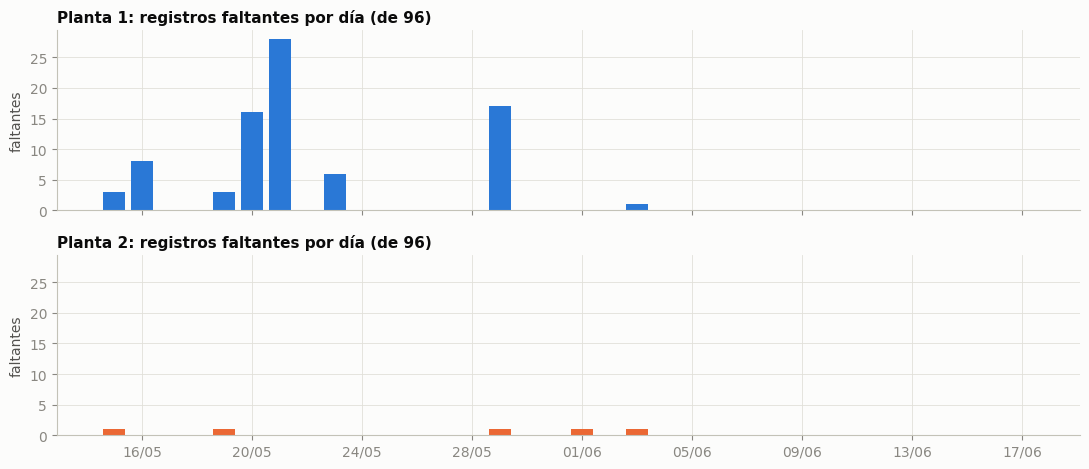

In [11]:
fig, ejes = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, sharey=True)
for eje, (n, d) in zip(ejes, completos.items()):
    falt = d[OBJETIVO].isna().groupby(d.index.date).sum()
    eje.bar(pd.to_datetime(falt.index), falt.values, width=0.8, color=COLOR[n])
    eje.set_title(f'{n}: registros faltantes por día (de 96)', loc='left')
    eje.set_ylabel('faltantes'); ejes_fecha(eje)
fig.tight_layout(); guardar(fig, 'p4_faltantes_por_dia'); plt.show()

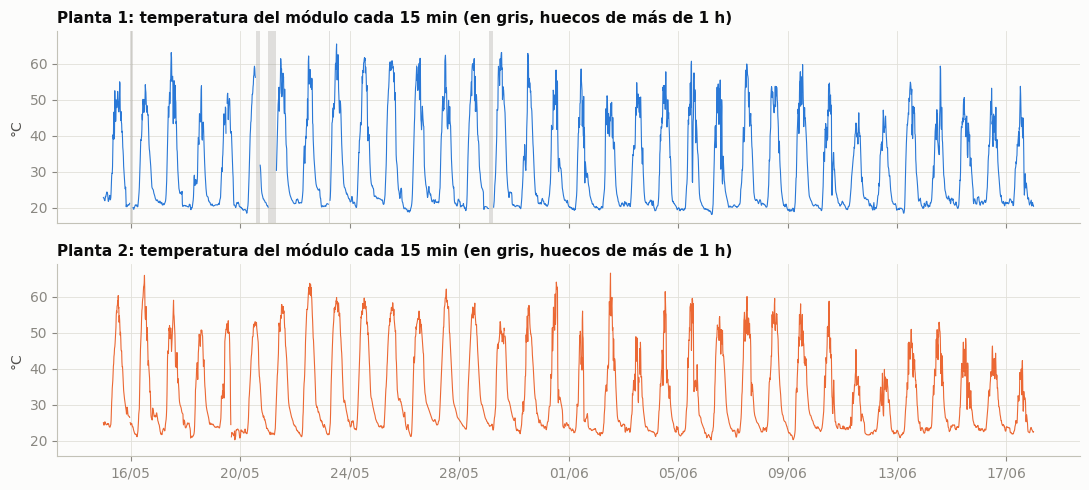

In [12]:
fig, ejes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, sharey=True)
for eje, (n, d) in zip(ejes, completos.items()):
    eje.plot(d.index, d[OBJETIVO], color=COLOR[n], linewidth=0.8)
    for _, h in huecos[n][huecos[n]['registros'] > MAX_HUECO].iterrows():
        eje.axvspan(h['inicio'], h['fin'], color=TENUE, alpha=0.25, linewidth=0)
    eje.set_title(f'{n}: temperatura del módulo cada 15 min (en gris, huecos de más de 1 h)', loc='left')
    eje.set_ylabel('°C'); ejes_fecha(eje)
fig.tight_layout(); guardar(fig, 'p4_serie_completa'); plt.show()

**Interpretación**
- La **Planta 1** tiene **82 registros faltantes (2,5 %)** en 8 huecos. Tres son cortos (de 15 a 45 min) y cinco son largos (de 1 h 15 min a 7 h). **Cuatro de los cinco largos son nocturnos o de madrugada.** El único hueco largo de día es el del **20 de mayo, de 13:30 a 17:15**.
- La **Planta 2** tiene solo **5 faltantes (0,15 %)**, todos de 15 minutos.
- El día con más faltantes es el **21 de mayo en la Planta 1**: 28 de 96 registros, entre las 00:45 y las 7:30, casi todo de noche.

> **Decisión: no se descarta ningún día completo.** El peor día (21 de mayo) pierde sobre todo horas de noche. Si el grupo modela solo las horas de sol (paso 9), ese día conserva casi toda su información útil. Los huecos largos se dejan como faltantes (paso 7) y esos instantes se excluyen del modelo.

## 5. Detectar valores imposibles
Se revisan **las tres columnas**, porque un predictor con errores engaña al modelo igual que un objetivo con errores.

In [13]:
for n, d in completos.items():
    print(f'\n{n}')
    display(d.describe().T.round(3))


Planta 1


,count,mean,std,min,25%,50%,75%,max
AMBIENT_TEMPERATURE,3182.0,25.532,3.355,20.399,22.705,24.614,27.921,35.252
MODULE_TEMPERATURE,3182.0,31.091,12.261,18.140,21.091,24.618,41.308,65.546
IRRADIATION,3182.0,0.228,0.301,0.000,0.000,0.025,0.450,1.222



Planta 2


,count,mean,std,min,25%,50%,75%,max
AMBIENT_TEMPERATURE,3259.0,28.069,4.062,20.942,24.602,26.981,31.057,39.182
MODULE_TEMPERATURE,3259.0,32.772,11.344,20.265,23.717,27.535,40.481,66.636
IRRADIATION,3259.0,0.233,0.313,0.000,0.000,0.019,0.439,1.099


In [14]:
filas = []
for n, d in completos.items():
    for c, (lo, hi) in RANGOS_FISICOS.items():
        fuera = ((d[c] < lo) | (d[c] > hi)).sum()
        filas.append({'planta': n, 'variable': c, 'rango físico': f'[{lo}, {hi}]', 'fuera del rango': fuera})
display(pd.DataFrame(filas))

,planta,variable,rango físico,fuera del rango
0,Planta 1,AMBIENT_TEMPERATURE,"[0, 50]",0
1,Planta 1,MODULE_TEMPERATURE,"[0, 85]",0
2,Planta 1,IRRADIATION,"[0, 1.5]",0
3,Planta 2,AMBIENT_TEMPERATURE,"[0, 50]",0
4,Planta 2,MODULE_TEMPERATURE,"[0, 85]",0
5,Planta 2,IRRADIATION,"[0, 1.5]",0


In [15]:
# Sensor congelado: el mismo valor más de 1 hora seguida (5 registros o más).
# En la irradiación solo cuenta si el valor es > 0, porque de noche es normal que se quede en 0.
filas = []
for n, d in completos.items():
    for c in VARS:
        s = d[c].dropna()
        largo = s.groupby((s.diff() != 0).cumsum()).transform('size')
        congelado = (largo >= 5) & ((s > 0) if c == 'IRRADIATION' else True)
        filas.append({'planta': n, 'variable': c, 'registros congelados': int(congelado.sum())})
display(pd.DataFrame(filas))

for n, d in completos.items():
    h = hora_decimal(d.index)
    noche = (h < 5) | (h >= 19)
    print(f'{n}: irradiación máxima de noche (19:00 a 05:00) = {d.loc[noche, "IRRADIATION"].max():.3f} kW/m²')

,planta,variable,registros congelados
0,Planta 1,AMBIENT_TEMPERATURE,0
1,Planta 1,MODULE_TEMPERATURE,0
2,Planta 1,IRRADIATION,0
3,Planta 2,AMBIENT_TEMPERATURE,0
4,Planta 2,MODULE_TEMPERATURE,0
5,Planta 2,IRRADIATION,0


Planta 1: irradiación máxima de noche (19:00 a 05:00) = 0.000 kW/m²
Planta 2: irradiación máxima de noche (19:00 a 05:00) = 0.003 kW/m²


**Interpretación**
- **Ningún valor sale de su rango físico.** La irradiación máxima es de 1,22 kW/m² en la Planta 1 y 1,10 kW/m² en la Planta 2. Es posible: con nubes que reflejan la luz, la irradiancia puede pasar brevemente de 1 kW/m².
- **No hay sensores congelados** en ninguna variable.
- De noche (19:00 a 05:00) la irradiación es prácticamente 0: el máximo es 0,003 kW/m² en la Planta 2, que es ruido del sensor. No tiene importancia física y queda muy por debajo del umbral de horas de sol del paso 9.

> **Resultado:** no hay valores imposibles que corregir.

## 6. Detectar atípicos
La regla del IQR aplicada a **toda la columna** mezcla noches y mediodías. Por eso se calcula **dentro de cada cuarto de hora del día**: cada valor se compara con los de la misma hora en los otros días. En la irradiación se usa **solo con sol**, porque de noche casi todos los valores son 0 y el IQR no tiene sentido.

In [16]:
filas = []
for n, d in completos.items():
    sol = d['IRRADIATION'] > UMBRAL_SOL
    for c in VARS:
        for k in (1.5, 2, 3):
            marca = atipicos_por_cuarto(d, c, k, solo=sol if c == 'IRRADIATION' else None)
            filas.append({'planta': n, 'variable': c, 'k': k, 'marcados': int(marca.sum())})
tabla_k = pd.DataFrame(filas).pivot_table(index=['planta', 'variable'], columns='k', values='marcados')
display(tabla_k)

k                              1.5   2.0  3.0
planta   variable                            
Planta 1 AMBIENT_TEMPERATURE  70.0  19.0  0.0
         IRRADIATION           5.0   1.0  0.0
         MODULE_TEMPERATURE   57.0  18.0  0.0
Planta 2 AMBIENT_TEMPERATURE  27.0   9.0  1.0
         IRRADIATION          18.0   3.0  1.0
         MODULE_TEMPERATURE   25.0   6.0  0.0

In [17]:
marcados = []
for n, d in completos.items():
    sol = d['IRRADIATION'] > UMBRAL_SOL
    for c in VARS:
        m = atipicos_por_cuarto(d, c, K_IQR, solo=sol if c == 'IRRADIATION' else None)
        for t in d.index[m]:
            marcados.append({'planta': n, 'fecha': t, 'variable': c, 'valor': round(d.loc[t, c], 3),
                             'T. ambiente': round(d.loc[t, 'AMBIENT_TEMPERATURE'], 2),
                             'T. módulo': round(d.loc[t, 'MODULE_TEMPERATURE'], 2),
                             'irradiación': round(d.loc[t, 'IRRADIATION'], 3)})
tabla_atipicos = pd.DataFrame(marcados)
print(f'Atípicos con k = {K_IQR}: {len(tabla_atipicos)}')
display(tabla_atipicos)

Atípicos con k = 3: 2


,planta,fecha,variable,valor,T. ambiente,T. módulo,irradiación
0,Planta 2,2020-06-12 12:15:00,AMBIENT_TEMPERATURE,23.301,23.30,26.91,0.382
1,Planta 2,2020-06-02 06:45:00,IRRADIATION,0.148,23.86,24.49,0.148


In [18]:
# Regla física 1: sin sol, el módulo debe estar cerca de la temperatura del aire.
# Regla física 2: con sol fuerte, el módulo debe estar por encima del aire.
for n, d in completos.items():
    dif = d['MODULE_TEMPERATURE'] - d['AMBIENT_TEMPERATURE']
    noche, sol_fuerte = d['IRRADIATION'] == 0, d['IRRADIATION'] > 0.3
    print(f'{n}: módulo − aire de noche: media {dif[noche].mean():.2f} °C, rango [{dif[noche].min():.2f}, '
          f'{dif[noche].max():.2f}] | con sol fuerte (> 0,3 kW/m²) y módulo más frío que el aire: '
          f'{int((dif[sol_fuerte] < 0).sum())} registros')

Planta 1: módulo − aire de noche: media -1.82 °C, rango [-3.42, -0.03] | con sol fuerte (> 0,3 kW/m²) y módulo más frío que el aire: 0 registros
Planta 2: módulo − aire de noche: media -1.29 °C, rango [-3.98, 0.39] | con sol fuerte (> 0,3 kW/m²) y módulo más frío que el aire: 0 registros


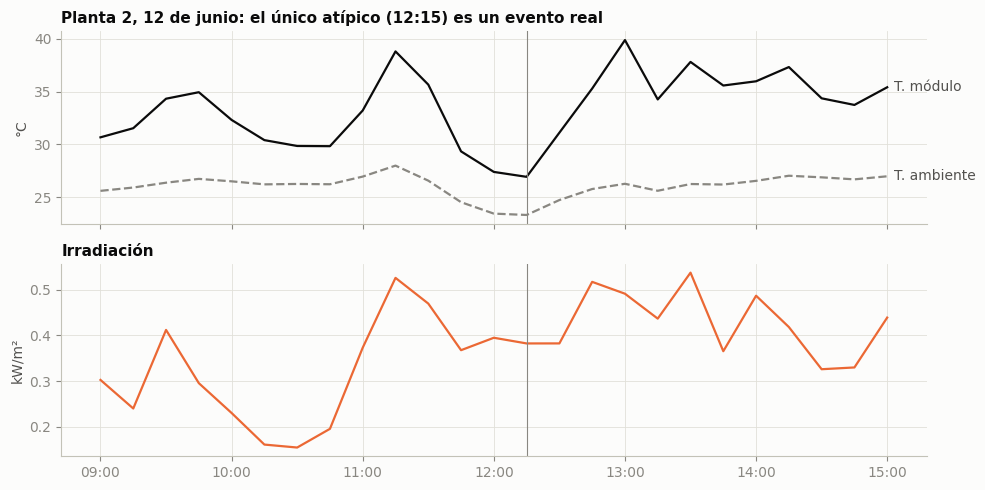

In [19]:
d = completos['Planta 2'].loc['2020-06-12 09:00':'2020-06-12 15:00']
fig, ejes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ejes[0].plot(d.index, d['MODULE_TEMPERATURE'], color=TINTA, label='T. módulo')
ejes[0].plot(d.index, d['AMBIENT_TEMPERATURE'], color=TENUE, linestyle='--', label='T. ambiente')
ejes[0].annotate('T. módulo', (d.index[-1], d['MODULE_TEMPERATURE'].iloc[-1]), xytext=(5, 0), textcoords='offset points', color=TINTA2, va='center')
ejes[0].annotate('T. ambiente', (d.index[-1], d['AMBIENT_TEMPERATURE'].iloc[-1]), xytext=(5, 0), textcoords='offset points', color=TINTA2, va='center')
ejes[0].axvline(pd.Timestamp('2020-06-12 12:15'), color=TENUE, linewidth=0.8)
ejes[0].set_ylabel('°C'); ejes[0].set_title('Planta 2, 12 de junio: el único atípico (12:15) es un evento real', loc='left')
ejes[1].plot(d.index, d['IRRADIATION'], color=COLOR['Planta 2'])
ejes[1].axvline(pd.Timestamp('2020-06-12 12:15'), color=TENUE, linewidth=0.8)
ejes[1].set_ylabel('kW/m²'); ejes[1].set_title('Irradiación', loc='left')
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.tight_layout(); plt.show()

**Interpretación**
- Con k = 1,5 la regla marca decenas de valores normales (hasta 70 en la temperatura ambiente de la Planta 1): mañanas y tardes de días muy despejados o muy nublados. Con **k = 3** quedan solo **2 valores**.
- **Temperatura:** el único atípico es el de la **Planta 2 el 12 de junio a las 12:15**. Ahí la temperatura ambiente cae 3 °C y la del módulo y la irradiación bajan al mismo tiempo. Es un **aguacero**, un evento real y coherente entre las tres variables, no un error del sensor (gráfica de arriba).
- **Irradiación:** el único atípico es el de la **Planta 2 el 2 de junio a las 6:45**: 0,148 kW/m², cuando la mediana a esa hora es 0,087. Es una **mañana muy despejada**. La irradiación sube de forma suave (0,077 → 0,148 → 0,182 kW/m² entre las 6:30 y las 7:00) y el módulo se calienta al mismo ritmo. Es real.
- **Las reglas físicas no encuentran errores.** De noche el módulo queda entre 1 y 2 °C **más frío** que el aire, porque se enfría irradiando calor hacia el cielo, como anticipa la consigna. Con sol fuerte (más de 0,3 kW/m²) **nunca** está por debajo del aire.

> **Decisión: k = 3 y no se borra ningún atípico.** Se usa k = 3, el valor más bajo que no marca valores normales de temperatura, como recomienda la guía. Los dos valores marcados son **eventos reales** (un aguacero y una mañana despejada), así que se conservan: el modelo debe aprender a estimarlos. Si un valor estuviera mal, se convertiría en `NaN` y se trataría en el paso 7.

## 7. Rellenar faltantes
La guía de la semana 14 recomienda **interpolar en el tiempo solo los huecos cortos** y dejar los largos sin rellenar, porque una recta no recupera la curva de varias horas. También se compara la distribución antes y después, como pide la consigna.

In [20]:
limpios, resumen_imputacion = {}, []
for n, d in completos.items():
    d = d.copy()
    faltaba = d[OBJETIVO].isna()
    antes = d[VARS].agg(['count', 'mean', 'std']).T
    for c in VARS:
        d[c] = rellenar_huecos_cortos(d[c], MAX_HUECO)
    d['imputado'] = faltaba & d[OBJETIVO].notna()
    despues = d[VARS].agg(['count', 'mean', 'std']).T
    limpios[n] = d
    resumen_imputacion.append({'planta': n, 'faltantes': int(faltaba.sum()), 'rellenados': int(d['imputado'].sum()),
                               'sin rellenar (huecos largos)': int(d[OBJETIVO].isna().sum())})
    print(f'\n{n}: antes y después de rellenar')
    display(pd.concat({'antes': antes, 'después': despues}, axis=1).round(3))
display(pd.DataFrame(resumen_imputacion))


Planta 1: antes y después de rellenar


antes                 después                
                      count    mean     std   count    mean     std
AMBIENT_TEMPERATURE  3182.0  25.532   3.355  3187.0  25.536   3.354
MODULE_TEMPERATURE   3182.0  31.091  12.261  3187.0  31.107  12.264
IRRADIATION          3182.0   0.228   0.301  3187.0   0.229   0.301


Planta 2: antes y después de rellenar


antes                 después                
                      count    mean     std   count    mean     std
AMBIENT_TEMPERATURE  3259.0  28.069   4.062  3264.0  28.070   4.063
MODULE_TEMPERATURE   3259.0  32.772  11.344  3264.0  32.772  11.343
IRRADIATION          3259.0   0.233   0.313  3264.0   0.233   0.313

,planta,faltantes,rellenados,sin rellenar (huecos largos)
0,Planta 1,82,5,77
1,Planta 2,5,5,0


**Interpretación**
- Se rellenaron **5 registros en cada planta**: los huecos de hasta 1 hora.
- En la Planta 1 quedan **77 registros sin rellenar**: los 5 huecos largos.
- La media y la desviación estándar casi no cambian, así que **el relleno no altera la distribución**.
- La columna `imputado` permite revisar después si el modelo se equivoca más en esos valores.

> **Decisión: interpolar solo huecos de hasta 1 hora (`MAX_HUECO = 4`).** En 15 a 45 minutos la temperatura cambia poco y la interpolación tiene un error pequeño. Según la guía, el error medio es de 0,4 °C, frente a 1,5 °C en los huecos largos. Los huecos largos quedan como `NaN` y **esos instantes se excluyen** del entrenamiento y de la prueba. No se usa la media de la columna, porque pondría valores del mediodía en la noche.

## 8. Explorar los patrones
### 8.1 ¿Las dos plantas tienen el mismo clima?
Histogramas y diagramas de caja de las tres variables. Para la irradiación se usan solo las horas de sol, porque de noche vale 0.

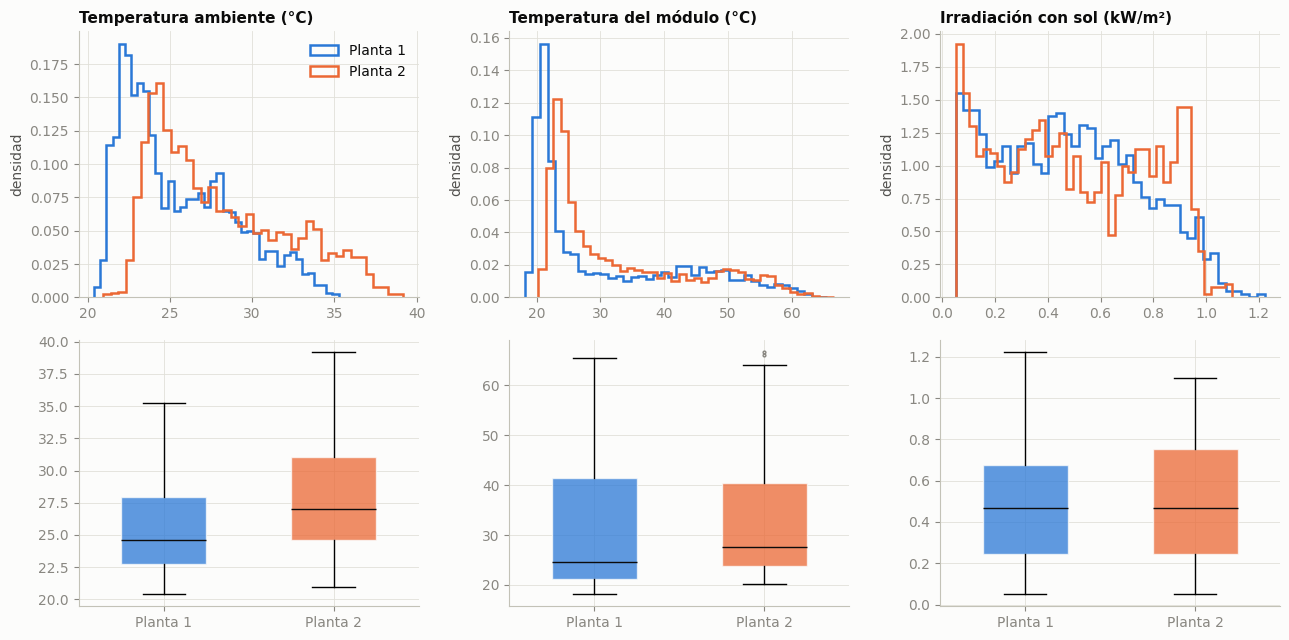

Planta 1                                           Planta 2                               
     AMBIENT_TEMPERATURE MODULE_TEMPERATURE IRRADIATION AMBIENT_TEMPERATURE MODULE_TEMPERATURE IRRADIATION
mean               25.54              31.11        0.23               28.07              32.77        0.23
50%                24.62              24.63        0.03               26.99              27.53        0.02
max                35.25              65.55        1.22               39.18              66.64        1.10

In [21]:
nombres = {'AMBIENT_TEMPERATURE': 'Temperatura ambiente (°C)', 'MODULE_TEMPERATURE': 'Temperatura del módulo (°C)',
           'IRRADIATION': 'Irradiación con sol (kW/m²)'}
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for j, c in enumerate(VARS):
    series = {n: (d.loc[d['IRRADIATION'] > UMBRAL_SOL, c] if c == 'IRRADIATION' else d[c]).dropna() for n, d in limpios.items()}
    for n, s in series.items():
        ejes[0, j].hist(s, bins=40, histtype='step', linewidth=1.8, color=COLOR[n], density=True, label=n)
    ejes[0, j].set_title(nombres[c], loc='left'); ejes[0, j].set_ylabel('densidad')
    caja = ejes[1, j].boxplot(list(series.values()), tick_labels=list(series.keys()), patch_artist=True, widths=0.5,
                              medianprops={'color': TINTA}, flierprops={'markersize': 2, 'markeredgecolor': TENUE})
    for parche, n in zip(caja['boxes'], series):
        parche.set_facecolor(COLOR[n]); parche.set_alpha(0.75); parche.set_edgecolor(FONDO)
ejes[0, 0].legend()
fig.tight_layout(); guardar(fig, 'p8_clima_dos_plantas'); plt.show()

tabla_clima = pd.concat({n: d[VARS].describe().loc[['mean', '50%', 'max']] for n, d in limpios.items()}, axis=1).round(2)
display(tabla_clima)

**Interpretación**
- **No tienen el mismo clima.** La **Planta 2 es más caliente**: su temperatura ambiente promedio es 2,5 °C mayor (28,1 °C contra 25,5 °C) y llega a 39 °C, contra 35 °C de la Planta 1.
- La **irradiación es muy parecida** en las dos plantas: el promedio es casi igual y la forma de la distribución también.
- La temperatura del módulo de la Planta 2 es solo 1,7 °C mayor en promedio, menos que la diferencia de la temperatura del aire. **Ese es un primer indicio de que los módulos de las dos plantas no se calientan igual con el mismo sol.** Esto conecta con P2: montaje, ventilación o tipo de módulo distintos.
- Las temperaturas tienen dos "jorobas" (noche y día). La irradiación con sol está repartida entre 0 y 1,2 kW/m².

### 8.2 El día típico: perfil diario
Para cada cuarto de hora del día, la mediana (línea) y la mitad central de los días (franja, del percentil 25 al 75).

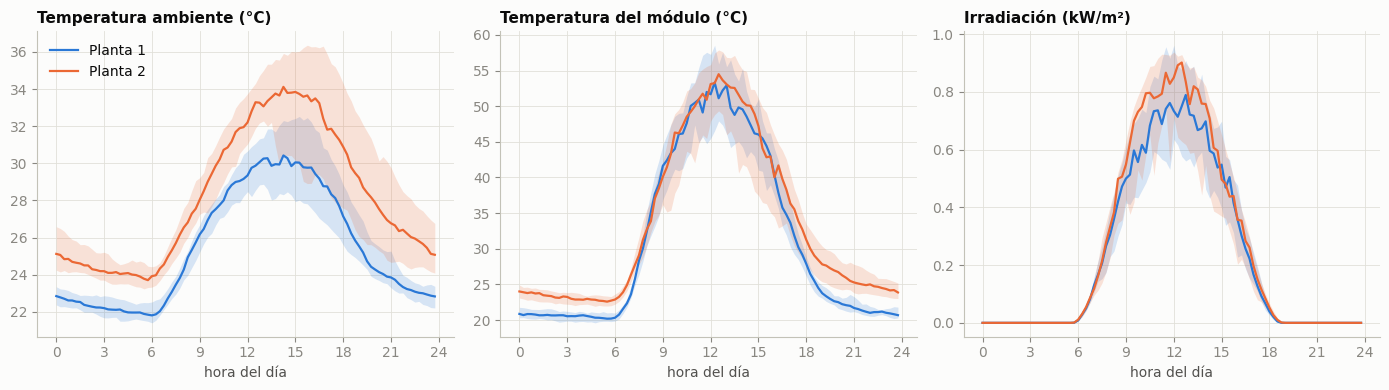

Planta 1: pico medio de irradiación a las 12.00 h | pico medio de T. módulo a las 12.25 h
Planta 2: pico medio de irradiación a las 12.50 h | pico medio de T. módulo a las 12.75 h


In [22]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for j, c in enumerate(VARS):
    for n, d in limpios.items():
        perfil = d.groupby(hora_decimal(d.index))[c].quantile([0.25, 0.5, 0.75]).unstack()
        ejes[j].fill_between(perfil.index, perfil[0.25], perfil[0.75], color=COLOR[n], alpha=0.18, linewidth=0)
        ejes[j].plot(perfil.index, perfil[0.5], color=COLOR[n], label=n)
    ejes[j].set_title(nombres[c].replace(' con sol', ''), loc='left'); ejes[j].set_xlabel('hora del día')
    ejes[j].set_xticks(range(0, 25, 3))
ejes[0].legend()
fig.tight_layout(); guardar(fig, 'p8_perfil_diario'); plt.show()
for n, d in limpios.items():
    h = hora_decimal(d.index)
    print(f'{n}: pico medio de irradiación a las {d.groupby(h)["IRRADIATION"].mean().idxmax():.2f} h | '
          f'pico medio de T. módulo a las {d.groupby(h)["MODULE_TEMPERATURE"].mean().idxmax():.2f} h')

**Interpretación**
- **El pico de irradiación cae al mediodía local**: a las 12:00 en la Planta 1 y a las 12:30 en la Planta 2. **La zona horaria es correcta**, así que la hora sirve como predictor.
- **La temperatura del módulo sigue a la irradiación**: sube desde las 6:00, llega a su máximo al mediodía (unos 15 minutos después del pico de sol) y baja al atardecer. La temperatura ambiente, en cambio, tiene su máximo más tarde, hacia las 14:00, porque el aire se calienta más despacio.
- **La franja es ancha al mediodía** porque los días nublados y despejados son muy distintos. **De noche es angosta**, porque todas las noches se enfrían parecido.

### 8.3 Cada día y cada hora: mapa día × hora de la temperatura del módulo

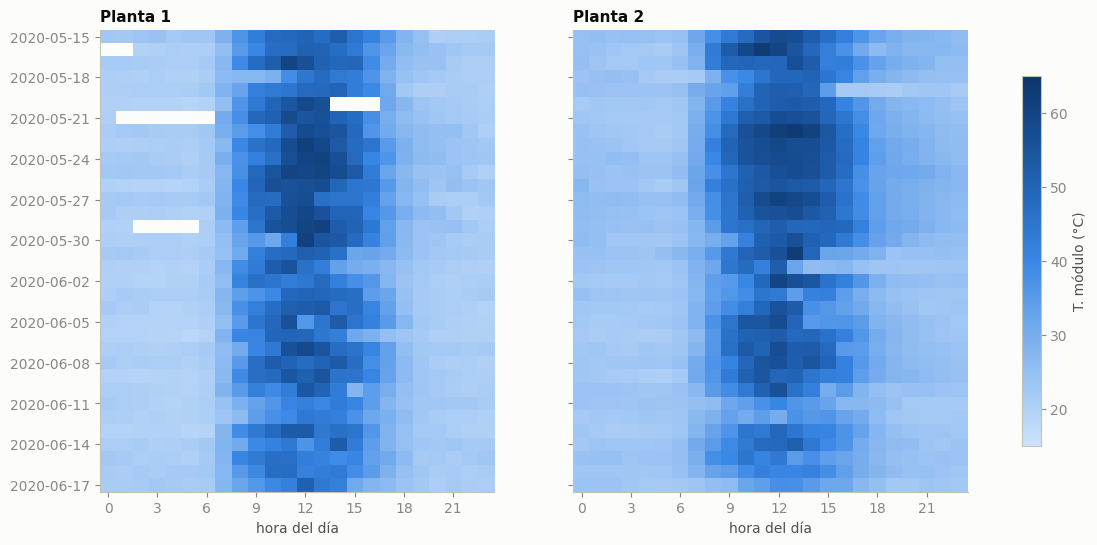

In [23]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for eje, (n, d) in zip(ejes, limpios.items()):
    tabla = d.pivot_table(index=d.index.date, columns=d.index.hour, values=OBJETIVO, aggfunc='mean', dropna=False)
    tabla = tabla.reindex(columns=range(24))
    im = eje.imshow(tabla.values, aspect='auto', cmap=SECUENCIAL, vmin=15, vmax=65, interpolation='nearest')
    eje.set_title(n, loc='left'); eje.set_xlabel('hora del día'); eje.set_xticks(range(0, 24, 3)); eje.grid(False)
    eje.set_yticks(range(0, len(tabla), 3)); eje.set_yticklabels([str(x) for x in tabla.index[::3]])
fig.colorbar(im, ax=ejes, label='T. módulo (°C)', shrink=0.8)
guardar(fig, 'p8_mapa_dia_hora'); plt.show()

**Interpretación**
- Cada fila es un día y cada columna una hora. **Los días nublados se ven como filas más claras al mediodía.**
- Las **celdas vacías** son los huecos largos de la Planta 1, sobre todo de madrugada. La Planta 2 no tiene celdas vacías.
- Muchos días nublados coinciden en las dos plantas, pero no todos: la irradiación diaria tiene una correlación de solo 0,61 entre plantas. Cada sensor ve su propio cielo.
- **Hacia el final del periodo (junio) las filas se aclaran**: hay más días nublados y frescos. El paso 8.4 lo confirma.

### 8.4 Entre días: tendencia y días nublados

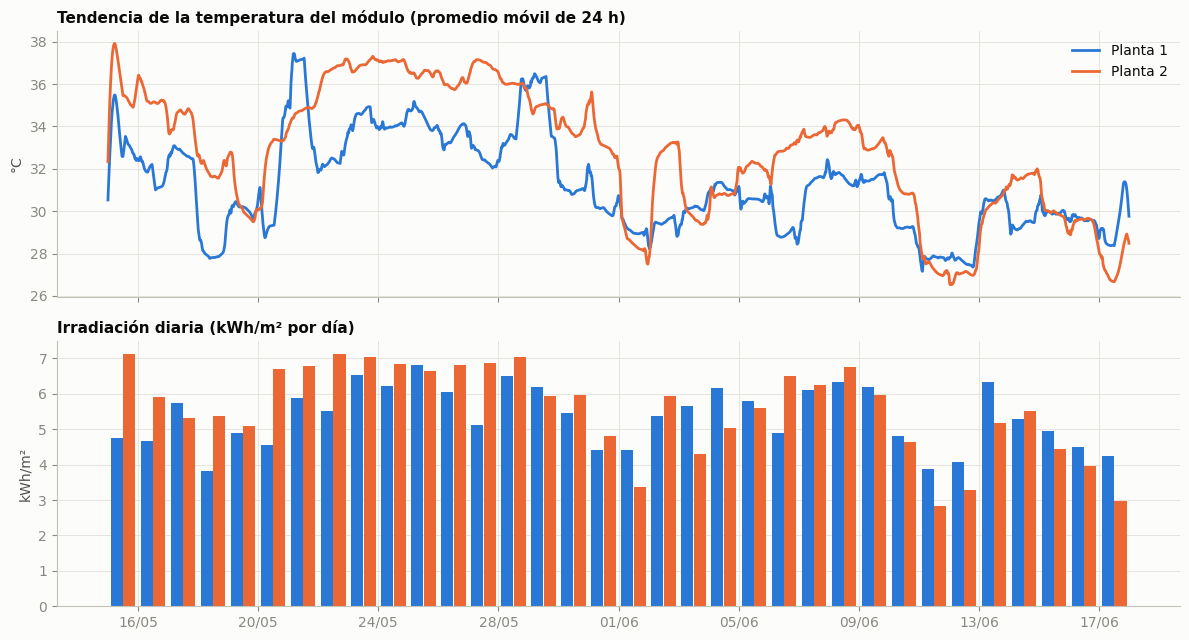

Planta 1: irradiación diaria media 5.36 kWh/m² | día más nublado 2020-05-18 (3.82) | más soleado 2020-05-25 (6.81)
Planta 2: irradiación diaria media 5.59 kWh/m² | día más nublado 2020-06-11 (2.82) | más soleado 2020-05-15 (7.14)


In [24]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for n, d in limpios.items():
    tendencia = d[OBJETIVO].rolling(96, center=True, min_periods=48).mean()
    ejes[0].plot(d.index, tendencia, color=COLOR[n], label=n, linewidth=2)
    energia = d['IRRADIATION'].resample('D').sum() * 0.25          # kWh/m² por día (cada registro dura 0,25 h)
    desfase = pd.Timedelta(hours=-5) if n == 'Planta 1' else pd.Timedelta(hours=5)
    ejes[1].bar(energia.index + desfase + pd.Timedelta(hours=12), energia.values, width=0.4, color=COLOR[n], label=n)
ejes[0].set_title('Tendencia de la temperatura del módulo (promedio móvil de 24 h)', loc='left'); ejes[0].set_ylabel('°C')
ejes[1].set_title('Irradiación diaria (kWh/m² por día)', loc='left'); ejes[1].set_ylabel('kWh/m²')
ejes_fecha(ejes[1]); ejes[0].legend(); fig.tight_layout(); guardar(fig, 'p8_tendencia_y_dias'); plt.show()

for n, d in limpios.items():
    e = d['IRRADIATION'].resample('D').sum() * 0.25
    print(f'{n}: irradiación diaria media {e.mean():.2f} kWh/m² | día más nublado {e.idxmin().date()} ({e.min():.2f}) | '
          f'más soleado {e.idxmax().date()} ({e.max():.2f})')

**Interpretación**
- **La tendencia baja en junio.** En la Planta 1, la temperatura media semanal del módulo pasa de unos 33 °C a finales de mayo a unos 29 a 30 °C en junio. Coincide con más días nublados.
- **Esto es clave para el paso 11: la semana de prueba (11 al 17 de junio) es la más nublada del periodo.** En la Planta 1, tres de los cinco días con menos irradiación caen ahí (11, 12 y 17 de junio). En la Planta 2 son cuatro de cinco (11, 12, 16 y 17 de junio). Es bueno para evaluar el modelo en condiciones difíciles, pero hay que tenerlo en cuenta al interpretar las métricas de la Tarea 3.
- Las barras de la Planta 1 de los días con huecos largos de día (el 20 de mayo) están **subestimadas**, porque la suma ignora los faltantes.

### 8.5 Los componentes de la serie
Serie = tendencia + ciclo diario + residuo. La desviación estándar de cada parte dice cuánto pesa.

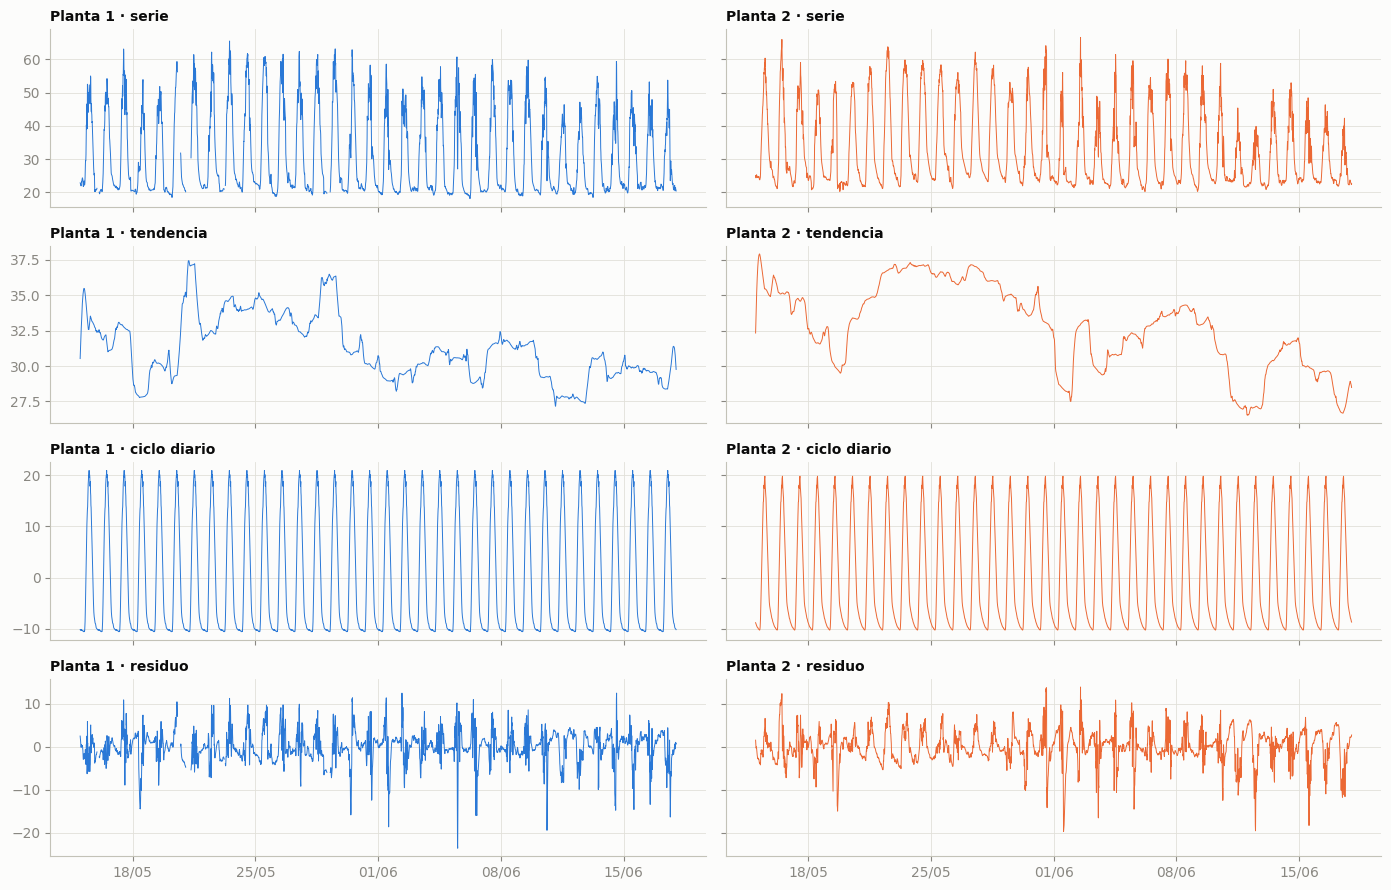

,Planta 1,Planta 2
desviación estándar (°C),,
serie,12.26,11.34
tendencia,2.23,2.97
ciclo diario,11.51,10.29
residuo,3.57,3.75


In [25]:
componentes = {}
fig, ejes = plt.subplots(4, 2, figsize=(14, 9), sharex='col', sharey='row')
for j, (n, d) in enumerate(limpios.items()):
    y = d[OBJETIVO]
    tendencia = y.rolling(96, center=True, min_periods=48).mean()
    ciclo = (y - tendencia).groupby(hora_decimal(d.index)).transform('mean')
    residuo = y - tendencia - ciclo
    partes = pd.DataFrame({'serie': y, 'tendencia': tendencia, 'ciclo diario': ciclo, 'residuo': residuo})
    componentes[n] = partes.std().round(2)
    for i, c in enumerate(partes.columns):
        ejes[i, j].plot(partes.index, partes[c], color=COLOR[n], linewidth=0.7)
        ejes[i, j].set_title(f'{n} · {c}', loc='left', fontsize=10)
    ejes_fecha(ejes[3, j], cada=7)
fig.tight_layout(); plt.show()
display(pd.DataFrame(componentes).rename_axis('desviación estándar (°C)'))

**Interpretación**
- **El ciclo diario domina**: varía casi tanto como la serie completa. **La hora del día es un predictor necesario.**
- **El residuo es mucho mayor que la tendencia**: lo que cambia de un día a otro son las nubes, no un nivel que sube o baja. Para explicar el residuo el modelo necesita **la irradiación**, porque la hora sola no sabe si el día está nublado.
- **La tendencia (desviación de 2,2 y 3,0 °C) es menor que el residuo (3,6 y 3,8 °C)** y mucho menor que el ciclo, **pero no es despreciable**: refleja el enfriamiento de junio. No se corrige antes de modelar, porque la irradiación y la temperatura ambiente ya explican esa baja: los días de junio son más nublados y frescos. Sí hay que tenerla en cuenta al dividir los datos (paso 11).

## 9. Relacionar las variables
### 9.1 ¿Día completo o solo horas de sol?
La consigna pide decidirlo y justificarlo con gráficos. La clave es la diferencia **módulo − aire**: aquí sirve **solo para explorar**. **No es un predictor**, porque se calcula con el objetivo del mismo instante y sería fuga de información.

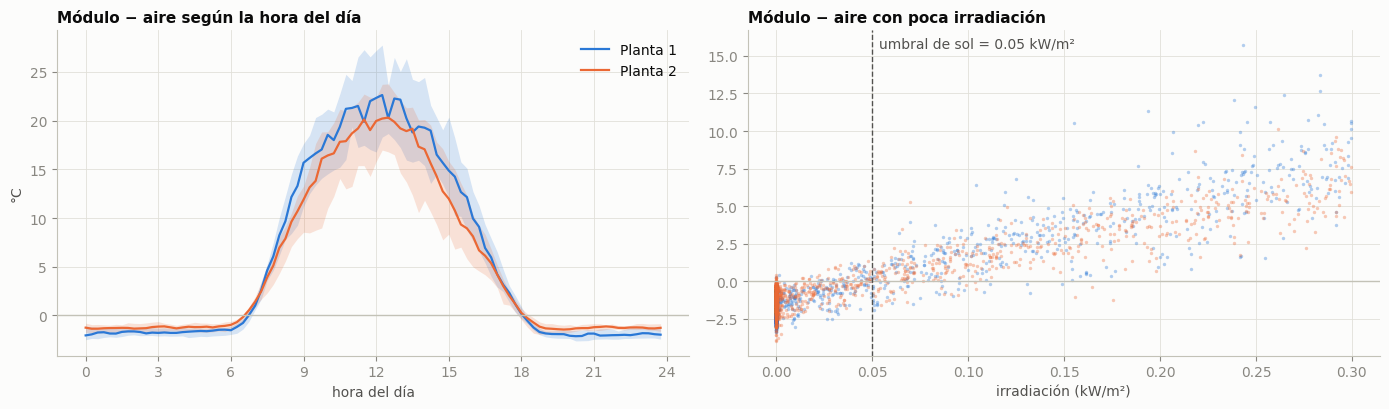


Planta 1: mediana de módulo − aire por tramo de irradiación (kW/m²)
IRRADIATION
(-0.001, 0.0]   -1.84
(0.0, 0.02]     -1.32
(0.02, 0.05]    -0.47
(0.05, 0.1]      0.96
(0.1, 0.2]       3.15
(0.2, 0.4]       8.53
Registros con sol (> 0.05 kW/m²): 1517 de 3264 (46%)

Planta 2: mediana de módulo − aire por tramo de irradiación (kW/m²)
IRRADIATION
(-0.001, 0.0]   -1.28
(0.0, 0.02]     -1.01
(0.02, 0.05]    -0.28
(0.05, 0.1]      0.72
(0.1, 0.2]       2.50
(0.2, 0.4]       6.40
Registros con sol (> 0.05 kW/m²): 1528 de 3264 (47%)


In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))
for n, d in limpios.items():
    dif = d['MODULE_TEMPERATURE'] - d['AMBIENT_TEMPERATURE']
    perfil = dif.groupby(hora_decimal(d.index)).quantile([0.25, 0.5, 0.75]).unstack()
    ejes[0].fill_between(perfil.index, perfil[0.25], perfil[0.75], color=COLOR[n], alpha=0.18, linewidth=0)
    ejes[0].plot(perfil.index, perfil[0.5], color=COLOR[n], label=n)
    bajo = d[d['IRRADIATION'] <= 0.3]
    ejes[1].scatter(bajo['IRRADIATION'], bajo['MODULE_TEMPERATURE'] - bajo['AMBIENT_TEMPERATURE'], s=6, alpha=0.35,
                    color=COLOR[n], label=n, linewidths=0)
for eje in ejes:
    eje.axhline(0, color=EJE, linewidth=1)
ejes[1].axvline(UMBRAL_SOL, color=TINTA2, linestyle='--', linewidth=1)
ejes[1].annotate(f'umbral de sol = {UMBRAL_SOL} kW/m²', (UMBRAL_SOL, ejes[1].get_ylim()[1]), xytext=(5, -12),
                 textcoords='offset points', color=TINTA2)
ejes[0].set_title('Módulo − aire según la hora del día', loc='left'); ejes[0].set_xlabel('hora del día'); ejes[0].set_ylabel('°C')
ejes[0].set_xticks(range(0, 25, 3)); ejes[0].legend()
ejes[1].set_title('Módulo − aire con poca irradiación', loc='left'); ejes[1].set_xlabel('irradiación (kW/m²)')
fig.tight_layout(); guardar(fig, 'p9_dia_o_noche'); plt.show()

for n, d in limpios.items():
    dif = d['MODULE_TEMPERATURE'] - d['AMBIENT_TEMPERATURE']
    tramos = pd.cut(d['IRRADIATION'], [-0.001, 0, 0.02, 0.05, 0.1, 0.2, 0.4])
    print(f'\n{n}: mediana de módulo − aire por tramo de irradiación (kW/m²)')
    print(dif.groupby(tramos, observed=True).median().round(2).to_string())
    print(f'Registros con sol (> {UMBRAL_SOL} kW/m²): {(d["IRRADIATION"] > UMBRAL_SOL).sum()} de {len(d)} '
          f'({(d["IRRADIATION"] > UMBRAL_SOL).mean():.0%})')

**Interpretación**
- **De noche** el módulo está entre 1 y 2 °C por **debajo** del aire, porque se enfría irradiando calor hacia el cielo. Ahí no hay sol que lo caliente y **el modelo de Ross no aplica**.
- **Con sol**, la diferencia se vuelve positiva y crece con la irradiación: la mediana llega a 23 °C en la Planta 1 y a 20 °C en la Planta 2 al mediodía. Es justo la relación que estudia el proyecto.
- En la segunda gráfica, la diferencia pasa de negativa a positiva **alrededor de 0,05 kW/m²**. Por debajo de ese valor, el módulo todavía se comporta como de noche.

> **Decisión: modelar solo las horas de sol (`IRRADIATION > 0,05 kW/m²`).**
> 1. **Física:** el calentamiento por irradiación, que es lo que describe el modelo de Ross y lo que pregunta P1, solo existe con sol. De noche el mecanismo es otro (enfriamiento radiativo).
> 2. **Negocio:** las pérdidas de potencia por calor (P3) y las alertas de puntos calientes solo importan cuando la planta genera.
> 3. **Métricas honestas:** las noches son fáciles de predecir (módulo ≈ aire). Si se incluyen, hacen que el error promedio parezca menor sin decir nada de lo que importa.
>
> Por debajo de 0,05 kW/m² el módulo aún no se calienta por encima del aire (tabla de arriba). Con ese umbral queda cerca de la mitad de los registros (46 a 47 %), de las 6:30 a las 18:00 aproximadamente.
> **Importante:** el filtro se aplica **después** de crear los rezagos (paso 10). Si se aplicara antes, el rezago de las 6:15 tomaría un valor del día anterior.

### 9.2 Gráficos de dispersión con sol: ¿la relación es lineal?, ¿es igual en las dos plantas?

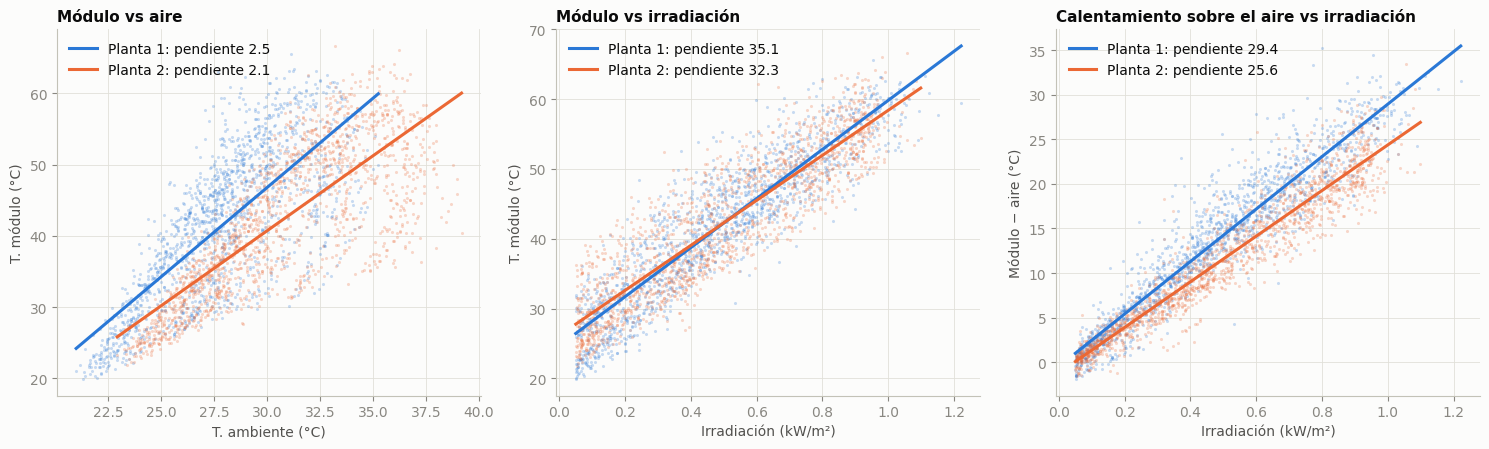

,relación,planta,pendiente,r
0,T. módulo (°C) vs T. ambiente (°C),Planta 1,2.51,0.742
1,T. módulo (°C) vs T. ambiente (°C),Planta 2,2.11,0.783
2,T. módulo (°C) vs Irradiación (kW/m²),Planta 1,35.15,0.912
3,T. módulo (°C) vs Irradiación (kW/m²),Planta 2,32.25,0.897
4,Módulo − aire (°C) vs Irradiación (kW/m²),Planta 1,29.44,0.949
5,Módulo − aire (°C) vs Irradiación (kW/m²),Planta 2,25.60,0.954


In [27]:
pares = [('AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'T. ambiente (°C)', 'T. módulo (°C)'),
         ('IRRADIATION', 'MODULE_TEMPERATURE', 'Irradiación (kW/m²)', 'T. módulo (°C)'),
         ('IRRADIATION', 'DIF', 'Irradiación (kW/m²)', 'Módulo − aire (°C)')]
pendientes = []
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
for j, (x, y, xl, yl) in enumerate(pares):
    for n, d in limpios.items():
        s = d[d['IRRADIATION'] > UMBRAL_SOL].dropna(subset=VARS).copy()
        s['DIF'] = s['MODULE_TEMPERATURE'] - s['AMBIENT_TEMPERATURE']
        ejes[j].scatter(s[x], s[y], s=5, alpha=0.25, color=COLOR[n], linewidths=0)
        m, b = np.polyfit(s[x], s[y], 1)
        xs = np.linspace(s[x].min(), s[x].max(), 50)
        ejes[j].plot(xs, m * xs + b, color=COLOR[n], linewidth=2.2, label=f'{n}: pendiente {m:.1f}')
        pendientes.append({'relación': f'{yl} vs {xl}', 'planta': n, 'pendiente': round(m, 2),
                           'r': round(s[x].corr(s[y]), 3)})
    ejes[j].set_xlabel(xl); ejes[j].set_ylabel(yl); ejes[j].legend(loc='upper left')
ejes[0].set_title('Módulo vs aire', loc='left'); ejes[1].set_title('Módulo vs irradiación', loc='left')
ejes[2].set_title('Calentamiento sobre el aire vs irradiación', loc='left')
fig.tight_layout(); guardar(fig, 'p9_dispersion'); plt.show()
display(pd.DataFrame(pendientes))

**Interpretación**
- **Módulo − aire contra irradiación (tercera gráfica)** es casi una **recta que pasa cerca del origen** (interceptos de −0,5 y −1,2 °C): sin sol no hay calentamiento, y a más sol, más calentamiento. **La relación es aproximadamente lineal** (r = 0,95), como predice el modelo de Ross (T_módulo = T_aire + k·G).
- **La pendiente es distinta en cada planta: 29,4 °C por kW/m² en la Planta 1 y 25,6 en la Planta 2.** El módulo de la Planta 2 se calienta menos con el mismo sol, aunque su aire es más caliente. Esto anticipa P2: montaje, ventilación o tipo de módulo distintos.
- Las dos pendientes están **dentro del rango de 21 a 31 °C por kW/m²** que anticipa la Tarea 1 (Ross para estructura abierta y NOCT de la ficha). Son pendientes **exploratorias**, de una recta simple: la respuesta formal a P1 sale de la regresión múltiple de la Tarea 3.
- La nube de **módulo contra aire** es mucho más dispersa: la temperatura del aire sola explica poco, porque a la misma temperatura puede haber o no haber sol. Por eso la línea base de "temperatura ambiente sola" va a ser débil.

### 9.3 Matriz de correlación con sol
Se calcula solo con horas de sol, porque los ceros de la noche inflarían las correlaciones.

Planta 1:


,AMBIENT_TEMPERATURE,IRRADIATION,HORA,MODULE_TEMPERATURE
AMBIENT_TEMPERATURE,1.000,0.500,0.626,0.742
IRRADIATION,0.500,1.000,-0.012,0.912
HORA,0.626,-0.012,1.000,0.200
MODULE_TEMPERATURE,0.742,0.912,0.200,1.000


Planta 2:


,AMBIENT_TEMPERATURE,IRRADIATION,HORA,MODULE_TEMPERATURE
AMBIENT_TEMPERATURE,1.000,0.497,0.619,0.783
IRRADIATION,0.497,1.000,-0.059,0.897
HORA,0.619,-0.059,1.000,0.222
MODULE_TEMPERATURE,0.783,0.897,0.222,1.000


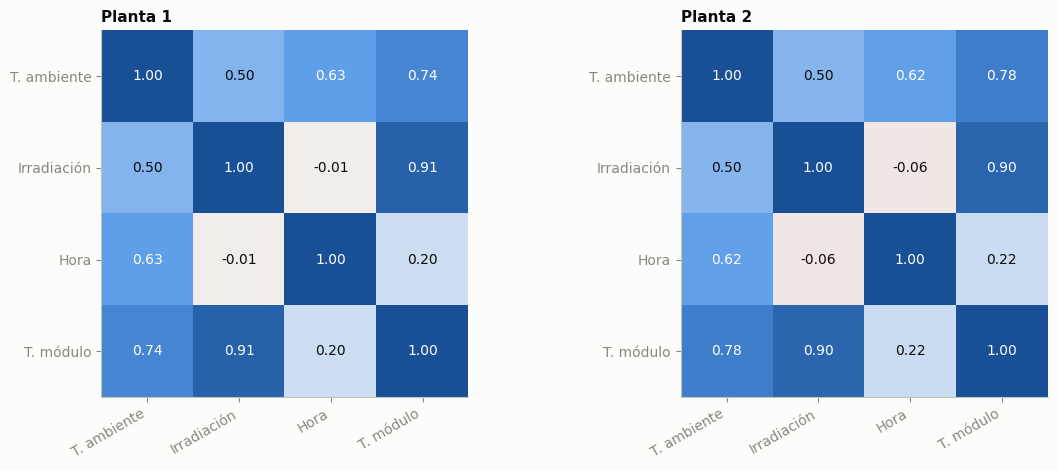

In [28]:
cols_corr = ['AMBIENT_TEMPERATURE', 'IRRADIATION', 'HORA', 'MODULE_TEMPERATURE']
etiquetas = ['T. ambiente', 'Irradiación', 'Hora', 'T. módulo']
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, (n, d) in zip(ejes, limpios.items()):
    s = d[d['IRRADIATION'] > UMBRAL_SOL].copy(); s['HORA'] = hora_decimal(s.index)
    c = s[cols_corr].corr()
    eje.imshow(c.values, cmap=DIVERGENTE, vmin=-1, vmax=1); eje.grid(False)
    eje.set_xticks(range(4)); eje.set_xticklabels(etiquetas, rotation=30, ha='right')
    eje.set_yticks(range(4)); eje.set_yticklabels(etiquetas); eje.set_title(n, loc='left')
    for i in range(4):
        for j in range(4):
            eje.text(j, i, f'{c.values[i, j]:.2f}', ha='center', va='center',
                     color='#ffffff' if abs(c.values[i, j]) > 0.6 else TINTA, fontsize=10)
    print(f'{n}:'); display(c.round(3))
fig.tight_layout(); guardar(fig, 'p9_correlacion'); plt.show()

**Interpretación**
- **La irradiación es la variable más relacionada** con la temperatura del módulo (r ≈ 0,90). Le sigue la temperatura ambiente (r ≈ 0,74 a 0,78).
- La **irradiación y la temperatura ambiente están solo moderadamente correlacionadas entre sí** (r ≈ 0,50). Aportan información distinta y **pueden ir juntas** en la regresión sin un problema serio de multicolinealidad. 
- La **hora** casi no se correlaciona linealmente con la temperatura del módulo dentro de las horas de sol, porque la relación es una curva (sube y baja). En el modelo lineal aporta poco. El árbol de decisión sí puede aprovecharla.

## 10. Autocorrelación: la memoria de la serie
### 10.1 Rezagos
Se crean con `agregar_rezagos` del Anexo B, **por fecha y no por posición**, sobre la **serie completa** (día y noche) y **antes** de filtrar las horas de sol. Si falta el registro anterior, el rezago queda vacío (`NaN`) y no toma un valor equivocado.

In [29]:
con_rezagos = {}
for n, d in limpios.items():
    t = d.reset_index()
    t = agregar_rezagos(t, 'MODULE_TEMPERATURE', REZAGOS)
    t = agregar_rezagos(t, 'IRRADIATION', REZAGOS)
    t['HORA'] = hora_decimal(pd.DatetimeIndex(t['DATE_TIME']))
    con_rezagos[n] = t.set_index('DATE_TIME')
print(con_rezagos['Planta 1'].loc['2020-05-15 10:00':'2020-05-15 11:00',
      ['MODULE_TEMPERATURE', 'MODULE_TEMPERATURE_lag1', 'MODULE_TEMPERATURE_lag4', 'IRRADIATION', 'IRRADIATION_lag1']].round(2))

                     MODULE_TEMPERATURE  MODULE_TEMPERATURE_lag1  MODULE_TEMPERATURE_lag4  IRRADIATION  IRRADIATION_lag1
DATE_TIME                                                                                                               
2020-05-15 10:00:00               52.55                    40.93                    45.01         0.67              0.54
2020-05-15 10:15:00               47.63                    52.55                    46.62         0.57              0.67
2020-05-15 10:30:00               49.25                    47.63                    39.14         0.46              0.57
2020-05-15 10:45:00               44.05                    49.25                    40.93         0.36              0.46
2020-05-15 11:00:00               47.69                    44.05                    52.55         0.64              0.36


### 10.2 Correlograma de la temperatura del módulo

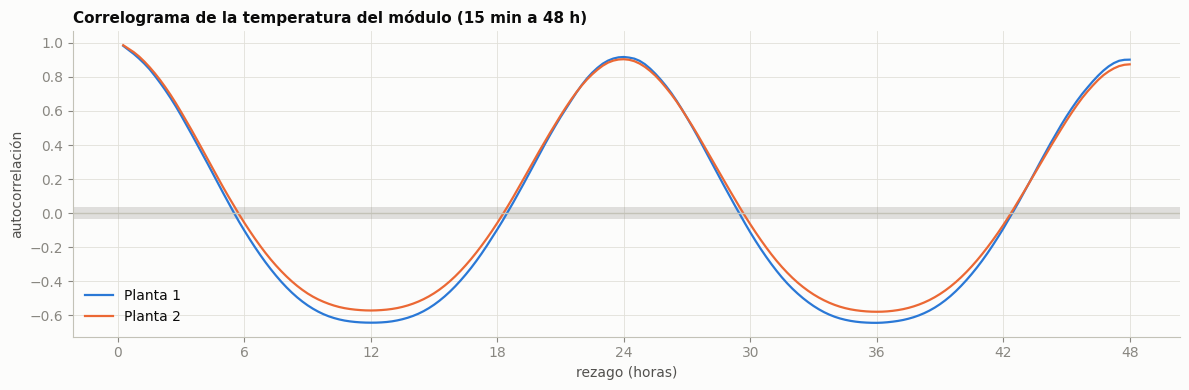

,Planta 1,Planta 2
rezago (×15 min),,
1,0.982,0.985
4,0.907,0.920
16,0.349,0.375
48,-0.642,-0.571
96,0.916,0.903
192,0.901,0.873


Autocorrelación sin el ciclo diario (anomalía):


,Planta 1,Planta 2
rezago (×15 min),,
1,0.863,0.935
4,0.573,0.785
16,0.244,0.451
96,0.239,0.452


In [30]:
rezagos_acf = range(1, 193)    # hasta 48 horas
acf, acf_anomalia = {}, {}
for n, d in limpios.items():
    y = d[OBJETIVO]
    anomalia = y - y.groupby(hora_decimal(d.index)).transform('mean')   # la serie sin ciclo diario
    acf[n] = pd.Series([y.autocorr(lag=k) for k in rezagos_acf], index=rezagos_acf)
    acf_anomalia[n] = pd.Series([anomalia.autocorr(lag=k) for k in (1, 4, 16, 96)], index=[1, 4, 16, 96])
banda = 1.96 / np.sqrt(limpios['Planta 1'][OBJETIVO].notna().sum())

fig, eje = plt.subplots(figsize=(12, 4))
for n, s in acf.items():
    eje.plot(np.array(s.index) / 4, s.values, color=COLOR[n], label=n)
eje.axhspan(-banda, banda, color=TENUE, alpha=0.25, linewidth=0)
eje.axhline(0, color=EJE, linewidth=1)
eje.set_xlabel('rezago (horas)'); eje.set_ylabel('autocorrelación'); eje.set_xticks(range(0, 49, 6))
eje.set_title('Correlograma de la temperatura del módulo (15 min a 48 h)', loc='left'); eje.legend()
fig.tight_layout(); guardar(fig, 'p10_correlograma'); plt.show()

display(pd.DataFrame({n: s.loc[[1, 4, 16, 48, 96, 192]] for n, s in acf.items()}).round(3).rename_axis('rezago (×15 min)'))
print('Autocorrelación sin el ciclo diario (anomalía):')
display(pd.DataFrame(acf_anomalia).round(3).rename_axis('rezago (×15 min)'))

**Interpretación**
- **Memoria de corto plazo:** la autocorrelación a 15 minutos es casi 1. El valor de hace 15 minutos es casi igual al actual. Por eso **la persistencia va a ser una línea base muy difícil de superar**.
- **Ciclo diario:** hay picos cada 24 horas (rezago 96) y valores negativos a las 12 horas (rezago 48), porque el día se opone a la noche.
- **Sin el ciclo diario (anomalía)**, la autocorrelación a 24 h **cae mucho**: de 0,92 a 0,24 en la Planta 1 y de 0,90 a 0,45 en la Planta 2. Casi todo lo que se repite de un día a otro es el sol. **No llega a cero** porque los días nublados vienen en rachas y por el enfriamiento de junio (paso 8.4).
- A 15 minutos la anomalía sigue alta (0,86 y 0,94): si ahora el módulo está más caliente de lo normal para la hora, en 15 minutos probablemente también. **Esa memoria de corto plazo es la que aprovechan los rezagos.**

### 10.3 Correlación cruzada con los predictores (horas de sol)
¿Qué rezago de cada predictor se relaciona más con la temperatura del módulo en t?

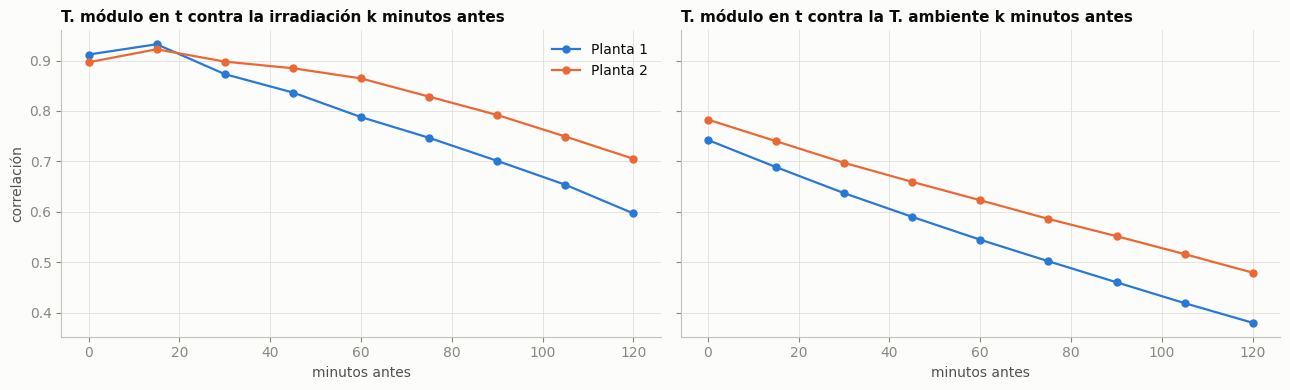

,predictor,planta,k=0,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8
0,IRRADIATION,Planta 1,0.912,0.932,0.873,0.837,0.788,0.747,0.701,0.654,0.597
1,IRRADIATION,Planta 2,0.897,0.922,0.898,0.885,0.865,0.828,0.792,0.749,0.705
2,AMBIENT_TEMPERATURE,Planta 1,0.742,0.689,0.637,0.590,0.544,0.502,0.460,0.419,0.380
3,AMBIENT_TEMPERATURE,Planta 2,0.783,0.740,0.697,0.659,0.623,0.586,0.552,0.516,0.479


In [31]:
filas = []
fig, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for j, (pred, etiqueta) in enumerate([('IRRADIATION', 'la irradiación'), ('AMBIENT_TEMPERATURE', 'la T. ambiente')]):
    for n, d in limpios.items():
        sol = d['IRRADIATION'] > UMBRAL_SOL
        r = [d.loc[sol, OBJETIVO].corr(d[pred].shift(k, freq='15min').reindex(d.index)[sol]) for k in range(9)]
        ejes[j].plot(np.arange(9) * 15, r, marker='o', markersize=5, color=COLOR[n], label=n)
        filas.append({'predictor': pred, 'planta': n, **{f'k={k}': round(v, 3) for k, v in enumerate(r)}})
    ejes[j].set_title(f'T. módulo en t contra {etiqueta} k minutos antes', loc='left'); ejes[j].set_xlabel('minutos antes')
ejes[0].set_ylabel('correlación'); ejes[0].legend()
fig.tight_layout(); guardar(fig, 'p10_correlacion_cruzada'); plt.show()
display(pd.DataFrame(filas))

**Interpretación**
- **Inercia térmica:** en las dos plantas, la temperatura del módulo se correlaciona **más con la irradiación de 15 minutos antes** (k = 1) que con la del mismo instante (k = 0). **El módulo tarda unos minutos en calentarse.** Coincide con lo que reporta Nguyen *et al.* [11] y con lo que anticipa la guía.
- Con la temperatura ambiente pasa lo contrario: la del mismo instante es la más relacionada, y la correlación baja a medida que k crece.
- En este Proyecto se estima la temperatura **en el mismo instante t**, así que la irradiación y la temperatura ambiente de t sí son predictores válidos. Los rezagos agregan información del pasado, que en la operación ya se conoce.

> **Decisión: variables candidatas para la Tarea 3.**
>
> | Variable | ¿Se usa? | Por qué |
> |---|---|---|
> | `AMBIENT_TEMPERATURE` (t) | ✅ Sí | Base física del modelo de Ross; r ≈ 0,74 a 0,78 |
> | `IRRADIATION` (t) | ✅ Sí | La más relacionada (r ≈ 0,90); su coeficiente responde P1 |
> | `HORA` (decimal) | ✅ Sí | El ciclo diario domina (paso 8.5); lo pide la consigna |
> | `IRRADIATION_lag1/2/4` | 🟡 Opcional | Inercia térmica (k = 1 es el máximo); comparar con y sin |
> | `MODULE_TEMPERATURE_lag1/2/4` | 🟡 Modelos "con rezagos" | Permitidos por la consigna; autocorrelación ≈ 1 a 15 min |
> | `MODULE_TEMPERATURE` (t) | ❌ No | Es el objetivo |
> | Módulo − aire (t) | ❌ No | **Fuga de información**: se calcula con el objetivo |
> | `PLANT_ID`, `SOURCE_KEY` | ❌ No | Son constantes |
>
> **Ojo para P1:** si el modelo incluye los rezagos de la temperatura del módulo, estos se llevan casi todo el efecto, y el coeficiente de la irradiación **ya no representa el k de Ross**. **P1 se responde con el modelo sin rezagos.** El modelo con rezagos sirve para predecir mejor y para competir con la persistencia.

### 10.4 Línea base de persistencia
La persistencia supone que la temperatura del módulo es igual a la de 15 minutos antes. Cualquier modelo con rezagos debe superarla.

In [32]:
filas = []
for n, d in con_rezagos.items():
    sol = d['IRRADIATION'] > UMBRAL_SOL
    d96 = d[OBJETIVO].shift(96, freq='15min').reindex(d.index)
    for nombre, pred in [('persistencia 15 min (lag1)', d['MODULE_TEMPERATURE_lag1']), ('persistencia diaria (lag96)', d96)]:
        e = (d[OBJETIVO] - pred)[sol].dropna()
        filas.append({'planta': n, 'línea base': nombre, 'MAE (°C)': round(e.abs().mean(), 2),
                      'RMSE (°C)': round(np.sqrt((e ** 2).mean()), 2), 'registros': len(e)})
display(pd.DataFrame(filas))

,planta,línea base,MAE (°C),RMSE (°C),registros
0,Planta 1,persistencia 15 min (lag1),2.46,3.36,1515
1,Planta 1,persistencia diaria (lag96),5.19,7.12,1451
2,Planta 2,persistencia 15 min (lag1),2.01,2.78,1528
3,Planta 2,persistencia diaria (lag96),4.73,6.83,1484


**Interpretación**
- Con sol, **la persistencia de 15 minutos se equivoca en promedio entre 2,0 y 2,5 °C** (MAE). La persistencia diaria, que usa el mismo instante del día anterior, se equivoca el doble: casi 5 °C.
- Es un error pequeño: **un modelo sin rezagos difícilmente le va a ganar**, porque no conoce el pasado reciente del módulo. Con rezagos, el reto es superarla.
- En la Tarea 3 estas métricas se recalculan **solo en el periodo de prueba**, para compararlas con los modelos.

## 11. Adelanto de la Tarea 3: dividir sin mirar el futuro
La división es **cronológica y por días completos**, como pide la consigna. El porcentaje no sale exacto, así que se reporta el real. La **validación** para elegir hiperparámetros es un `TimeSeriesSplit` de 5 particiones **dentro del entrenamiento**. La prueba se usa una sola vez, al final.

In [33]:
modelo = {}
for n, d in con_rezagos.items():
    s = d[(d['IRRADIATION'] > UMBRAL_SOL)].dropna(subset=VARS)
    modelo[n] = s
p1 = modelo['Planta 1']
train, test = p1[p1.index < CORTE], p1[p1.index >= CORTE]
dias_train, dias_test = train.index.normalize().nunique(), test.index.normalize().nunique()
print(f'Planta 1 con sol: {len(p1)} registros')
print(f'  Entrenamiento: {train.index.min()} -> {train.index.max()} | {dias_train} días | {len(train)} registros ({len(train)/len(p1):.1%})')
print(f'  Prueba:        {test.index.min()} -> {test.index.max()} | {dias_test} días | {len(test)} registros ({len(test)/len(p1):.1%})')
print(f'  ¿El último instante de train es anterior al primero de test? {train.index.max() < test.index.min()}')
print(f'\nPlanta 2 con sol: {len(modelo["Planta 2"])} registros (se usa completa para evaluar sin reentrenar)')

print('\nValidación cruzada para series de tiempo (dentro del entrenamiento):')
for i, (a, b) in enumerate(TimeSeriesSplit(n_splits=5).split(train)):
    print(f'  partición {i + 1}: entrena {train.index[a[0]]:%d/%m} a {train.index[a[-1]]:%d/%m} | '
          f'valida {train.index[b[0]]:%d/%m} a {train.index[b[-1]]:%d/%m}')

comparar = pd.DataFrame({'entrenamiento': train[VARS].mean(), 'prueba': test[VARS].mean()}).round(2)
print('\n¿Prueba más caliente o más nublada que el entrenamiento? (promedios con sol)')
display(comparar)

Planta 1 con sol: 1517 registros
  Entrenamiento: 2020-05-15 06:45:00 -> 2020-06-10 17:45:00 | 27 días | 1204 registros (79.4%)
  Prueba:        2020-06-11 07:00:00 -> 2020-06-17 17:45:00 | 7 días | 313 registros (20.6%)
  ¿El último instante de train es anterior al primero de test? True

Planta 2 con sol: 1528 registros (se usa completa para evaluar sin reentrenar)

Validación cruzada para series de tiempo (dentro del entrenamiento):
  partición 1: entrena 15/05 a 19/05 | valida 19/05 a 24/05
  partición 2: entrena 15/05 a 24/05 | valida 24/05 a 28/05
  partición 3: entrena 15/05 a 28/05 | valida 28/05 a 02/06
  partición 4: entrena 15/05 a 02/06 | valida 02/06 a 06/06
  partición 5: entrena 15/05 a 06/06 | valida 06/06 a 10/06

¿Prueba más caliente o más nublada que el entrenamiento? (promedios con sol)


,entrenamiento,prueba
AMBIENT_TEMPERATURE,28.28,26.38
MODULE_TEMPERATURE,42.45,37.68
IRRADIATION,0.49,0.42


**Interpretación**
- Se usan **27 días para entrenar** (15 de mayo a 10 de junio) y **7 días para probar** (11 a 17 de junio). Con horas de sol son **1.204 registros de entrenamiento (79,4 %) y 313 de prueba (20,6 %)**, prácticamente el 80/20 que pide la consigna.
- `TimeSeriesSplit` **siempre valida con días posteriores** a los de entrenamiento, como pasaría al usar el modelo en la operación. **No se divide al azar**: con una autocorrelación de 0,99 a 15 minutos, mezclar daría métricas falsamente buenas.
- **La prueba es más fresca y más nublada que el entrenamiento.** Con sol, la temperatura del aire promedia 1,9 °C menos y la del módulo 4,8 °C menos, y la irradiación es un 14 % menor. Es la semana más nublada del periodo (paso 8.4). Si el modelo se equivoca más en la prueba, **parte de la diferencia puede deberse al clima y no al sobreajuste**. Hay que tenerlo en cuenta al comparar entrenamiento con prueba en la Tarea 3.

> **Decisión: corte el 11 de junio a las 00:00.** Es un corte en el inicio de un día (no a mitad de día) y deja cerca de un 80/20, como pide la consigna.

## 12. Resumen de decisiones de limpieza
Se pide esta tabla como cierre de la Tarea 2. Va también en la sección de preparación de datos del informe.

In [34]:
h1 = huecos['Planta 1']
resumen = pd.DataFrame([
    {'paso': '1. Fecha', 'qué se revisó': 'Formato y fechas inválidas', 'resultado': '0 inválidas en ambas plantas',
     'decisión': f'Convertir con formato explícito {FORMATO_FECHA}'},
    {'paso': '2-3. Orden y duplicados', 'qué se revisó': 'Intervalos y fechas repetidas', 'resultado': '0 duplicados; 1 sensor por planta',
     'decisión': 'Nada que borrar ni agregar'},
    {'paso': '4. Faltantes', 'qué se revisó': 'Rejilla de 3.264 instantes',
     'resultado': f'P1: {int(completos["Planta 1"][OBJETIVO].isna().sum())} en {len(h1)} huecos; P2: {int(completos["Planta 2"][OBJETIVO].isna().sum())}',
     'decisión': 'No se descarta ningún día'},
    {'paso': '5. Valores imposibles', 'qué se revisó': 'Rangos físicos y sensores congelados', 'resultado': '0 en ambas plantas',
     'decisión': 'Nada que corregir'},
    {'paso': '6. Atípicos', 'qué se revisó': f'IQR por cuarto de hora (k = {K_IQR}) + reglas físicas',
     'resultado': f'{len(tabla_atipicos)} marcados; ambos eventos reales (aguacero y mañana despejada)', 'decisión': 'Se conservan'},
    {'paso': '7. Relleno', 'qué se revisó': 'Huecos de hasta 1 hora',
     'resultado': ' | '.join(f"{r['planta']}: {r['rellenados']} rellenados, {r['sin rellenar (huecos largos)']} sin rellenar" for r in resumen_imputacion),
     'decisión': 'Interpolar en el tiempo los cortos; excluir los largos'},
    {'paso': '9. Día o noche', 'qué se revisó': 'Módulo − aire por hora e irradiación', 'resultado': 'De noche el módulo queda bajo el aire; Ross no aplica',
     'decisión': f'Modelar solo horas de sol (IRRADIATION > {UMBRAL_SOL} kW/m²)'},
    {'paso': '10. Rezagos', 'qué se revisó': 'Autocorrelación y correlación cruzada', 'resultado': 'Memoria de 15 min ≈ 1; irradiación con 15 min de retraso',
     'decisión': f'Rezagos {REZAGOS} de T. módulo e irradiación, por fecha y antes del filtro de sol'},
    {'paso': '11. División', 'qué se revisó': 'Corte cronológico por días', 'resultado': f'Train {dias_train} días / test {dias_test} días',
     'decisión': f'Corte en {CORTE}; TimeSeriesSplit(5) dentro de train'},
])
with pd.option_context('display.max_colwidth', None):
    display(resumen)
print({n: s.shape for n, s in modelo.items()}, '-> datasets listos para la Tarea 3 (variable `modelo`)')
print('Figuras guardadas:', sorted(p.name for p in FIGURAS.glob('*.png')))

,paso,qué se revisó,resultado,decisión
0,1. Fecha,Formato y fechas inválidas,0 inválidas en ambas plantas,Convertir con formato explícito %Y-%m-%d %H:%M:%S
1,2-3. Orden y duplicados,Intervalos y fechas repetidas,0 duplicados; 1 sensor por planta,Nada que borrar ni agregar
2,4. Faltantes,Rejilla de 3.264 instantes,P1: 82 en 8 huecos; P2: 5,No se descarta ningún día
3,5. Valores imposibles,Rangos físicos y sensores congelados,0 en ambas plantas,Nada que corregir
4,6. Atípicos,IQR por cuarto de hora (k = 3) + reglas físicas,2 marcados; ambos eventos reales (aguacero y mañana despejada),Se conservan
5,7. Relleno,Huecos de hasta 1 hora,"Planta 1: 5 rellenados, 77 sin rellenar | Planta 2: 5 rellenados, 0 sin rellenar",Interpolar en el tiempo los cortos; excluir los largos
6,9. Día o noche,Módulo − aire por hora e irradiación,De noche el módulo queda bajo el aire; Ross no aplica,Modelar solo horas de sol (IRRADIATION > 0.05 kW/m²)
7,10. Rezagos,Autocorrelación y correlación cruzada,Memoria de 15 min ≈ 1; irradiación con 15 min de retraso,"Rezagos (1, 2, 4) de T. módulo e irradiación, por fecha y antes del filtro de sol"
8,11. División,Corte cronológico por días,Train 27 días / test 7 días,Corte en 2020-06-11; TimeSeriesSplit(5) dentro de train


{'Planta 1': (1517, 11), 'Planta 2': (1528, 11)} -> datasets listos para la Tarea 3 (variable `modelo`)
Figuras guardadas: ['inf_fig1_calentamiento.png', 'inf_fig2_real_vs_predicho.png', 'inf_fig3_residuos.png', 'inf_fig4_coeficientes.png', 'inf_fig5_negocio.png', 'p10_correlacion_cruzada.png', 'p10_correlograma.png', 'p4_faltantes_por_dia.png', 'p4_serie_completa.png', 'p8_clima_dos_plantas.png', 'p8_mapa_dia_hora.png', 'p8_perfil_diario.png', 'p8_tendencia_y_dias.png', 'p9_correlacion.png', 'p9_dia_o_noche.png', 'p9_dispersion.png', 't3_alertas.png', 't3_coef_estandarizados.png', 't3_coeficiente_irradiacion.png', 't3_comparacion_modelos.png', 't3_curva_profundidad.png', 't3_error_por_hora.png', 't3_grupos_predictores.png', 't3_importancia_arbol.png', 't3_perdidas_por_hora.png', 't3_real_vs_predicho.png', 't3_residuos.png', 't3_residuos_plantas.png', 't3_serie_prueba.png']


Los datasets listos para modelar están en la variable `modelo`: solo horas de sol, sin huecos largos y con rezagos.

# Tarea 3 · Modelado y evaluación
De lo simple a lo complejo y siempre contra una línea base, como pide la consigna. Todos los modelos se entrenan con la **Planta 1** (del 15 de mayo al 10 de junio) y se evalúan en la **prueba de la Planta 1** (del 11 al 17 de junio) y en la **Planta 2 sin reentrenar**. La estructura sigue la guía de modelado que el profe presentó en la clase 15.

| # | Modelo | Variables | Para qué |
|---|---|---|---|
| 1 | Línea base: regresión simple | T. ambiente | La referencia mínima que pide la consigna |
| 2 | Línea base: persistencia | T. módulo de 15 min antes | Repetir el último valor: el "piso" que hay que superar |
| 3 | Línea base: persistencia diaria | T. módulo de 24 h antes | El ingenuo estacional (*seasonal naive*) que pidió el profe en la clase 15 |
| 4 | Regresión lineal múltiple **sin rezagos** | T. ambiente, irradiación, hora | **Responde P1**: su coeficiente de irradiación estima el k de Ross |
| 5 | Regresión lineal múltiple **con rezagos** | Lo anterior + rezagos | Predecir mejor |
| 6 | Árbol de decisión sin rezagos | T. ambiente, irradiación, hora | Ver si un modelo no lineal le gana a la recta |
| 7 | Árbol de decisión con rezagos | Lo anterior + rezagos | Ídem, con memoria |
| 8 | Random Forest con rezagos (opcional) | Las del modelo 5 | Ensamble que promedia árboles |
| 9 | Gradient Boosting con rezagos (opcional) | Las del modelo 5 | Ensamble que suma árboles pequeños |

**Métricas.** Siguiendo la clase 15, la comparación se hace con **MAPE, RMSE y MAE**, y con la **habilidad** frente a la persistencia (1 − RMSE del modelo / RMSE de la persistencia). **No se usa el R²**, es engañoso para regresión. El MAPE se puede usar sin problema porque solo se modelan horas de sol, cuando la temperatura del módulo nunca está cerca de 0 °C.

## 3.0 Preparación
### Parámetros y decisiones de la Tarea 3

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

# Decisiones (cada una se justifica en el paso donde se usa)
F_AMB = ['AMBIENT_TEMPERATURE']                                   # línea base 1
F_SIN = ['AMBIENT_TEMPERATURE', 'IRRADIATION', 'HORA']            # sin rezagos (P1)
F_CON = F_SIN + ['IRRADIATION_lag1',                              # inercia térmica (paso 10.3)
                 'MODULE_TEMPERATURE_lag1', 'MODULE_TEMPERATURE_lag2', 'MODULE_TEMPERATURE_lag4']
HISTORIA = ['MODULE_TEMPERATURE_lag1', 'MODULE_TEMPERATURE_lag2', 'MODULE_TEMPERATURE_lag4', 'HORA']  # grupos de la guía
CLIMA = ['AMBIENT_TEMPERATURE', 'IRRADIATION', 'IRRADIATION_lag1']
REJILLA_ARBOL = {'modelo__max_depth': list(range(2, 16)), 'modelo__min_samples_leaf': [1, 10, 30]}
REJILLA_RF = {'modelo__max_depth': [4, 8, None], 'modelo__min_samples_leaf': [1, 10]}           # guía, paso 10
REJILLA_GB = {'modelo__learning_rate': [0.03, 0.1], 'modelo__max_depth': [2, 3, 4]}            # guía, paso 10
GAMMA = -0.30          # coeficiente de temperatura de Pmax (%/°C), ficha Jinko Tiger Neo [6]
T_STC = 25             # temperatura de referencia de las condiciones estándar de prueba (°C)
PERCENTIL_ALERTA = 99  # umbral de alerta = percentil 99 de los residuos de entrenamiento
assert set(HISTORIA + CLIMA) == set(F_CON)

### Tabla de predictores: ¿se conoce cada uno en el momento de estimar?
La regla práctica: si la empresa usa el modelo a las 10:00, **¿esa columna ya existe a las 10:00?** Si no existe, no entra. Aqui se busca estimar la temperatura **del mismo instante** (*nowcasting*), así que el clima medido en t sí se conoce; del módulo, solo su pasado.

| Predictor | Momento | ¿Se conoce a tiempo? | Modelos |
|---|---|---|---|
| `AMBIENT_TEMPERATURE` | t | ✅ Lo mide el sensor de clima en ese instante | 1, 4 a 9 |
| `IRRADIATION` | t | ✅ Igual | 4 a 9 |
| `HORA` (decimal) | t | ✅ Es el reloj, no una medición | 4 a 9 |
| `IRRADIATION_lag1` | t − 15 min | ✅ Lectura anterior | 5, 7, 8, 9 |
| `MODULE_TEMPERATURE_lag1`, `_lag2`, `_lag4` | t − 15, 30 y 60 min | ✅ Lecturas anteriores del propio sensor | 2, 5, 7, 8, 9 |
| `MODULE_TEMPERATURE_lag96` | t − 24 h | ✅ Lectura del día anterior | 3 |
| `MODULE_TEMPERATURE` | t | ❌ **Es el objetivo** | — |
| Módulo − aire | t | ❌ **Fuga**: se calcula con el objetivo (la sección 3.2 lo demuestra) | — |
| `DATE_TIME` (la fecha) | — | ❌ **No entra al modelo**, como dijo el profe en la clase 15. Solo sirve para crear la hora y los rezagos | — |
| `PLANT_ID`, `SOURCE_KEY` | — | ❌ Son constantes | — |

In [36]:
# Las mismas filas para todos los modelos: horas de sol y todos los predictores disponibles.
# (Se pierden solo los instantes justo después de un hueco largo, que no tienen rezago.)
# El rezago de 24 h se busca por fecha en la serie completa (día y noche), como los demás rezagos.
datos_m = {n: s.dropna(subset=F_CON + [OBJETIVO]).assign(
               MODULE_TEMPERATURE_lag96=lambda d, n=n: con_rezagos[n][OBJETIVO].shift(96, freq='15min').reindex(d.index))
           for n, s in modelo.items()}
p1, p2 = datos_m['Planta 1'], datos_m['Planta 2']
train, test = p1[p1.index < CORTE], p1[p1.index >= CORTE]
for n, s in modelo.items():
    print(f'{n}: {len(s)} registros con sol -> {len(datos_m[n])} con todos los predictores')
print(f'Planta 1 · entrenamiento {len(train)} ({len(train)/len(p1):.1%}) | prueba {len(test)} ({len(test)/len(p1):.1%})')
print(f'Planta 2 · evaluación completa sin reentrenar: {len(p2)}')
print('\nPrimeras filas de la tabla de modelado (Planta 1, entrenamiento):')
display(train[[OBJETIVO] + F_CON].iloc[20:25].round(2))

tscv = TimeSeriesSplit(n_splits=5)


def metricas(y, yhat):
    """MAPE, RMSE y MAE. Ignora los instantes sin predicción (la persistencia diaria no existe sin el día anterior)."""
    y, yhat = np.asarray(y, dtype=float), np.asarray(yhat, dtype=float)
    ok = ~np.isnan(yhat)
    y, yhat = y[ok], yhat[ok]
    return {'MAPE %': 100 * mean_absolute_percentage_error(y, yhat), 'RMSE': np.sqrt(mean_squared_error(y, yhat)),
            'MAE': mean_absolute_error(y, yhat)}


def tubo_lineal():
    # Imputación y escalado dentro del Pipeline: se ajustan solo con los datos de entrenamiento.
    return Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler()),
                     ('modelo', LinearRegression())])


def tubo_arbol(estimador=None):
    # Los árboles y los ensambles no necesitan escalado (dividen por umbrales); la imputación se deja por seguridad.
    return Pipeline([('imputar', SimpleImputer(strategy='median')),
                     ('modelo', estimador if estimador is not None else DecisionTreeRegressor(random_state=RANDOM_STATE))])

Planta 1: 1517 registros con sol -> 1504 con todos los predictores
Planta 2: 1528 registros con sol -> 1528 con todos los predictores
Planta 1 · entrenamiento 1191 (79.2%) | prueba 313 (20.8%)
Planta 2 · evaluación completa sin reentrenar: 1528

Primeras filas de la tabla de modelado (Planta 1, entrenamiento):


,MODULE_TEMPERATURE,AMBIENT_TEMPERATURE,IRRADIATION,HORA,IRRADIATION_lag1,MODULE_TEMPERATURE_lag1,MODULE_TEMPERATURE_lag2,MODULE_TEMPERATURE_lag4
DATE_TIME,,,,,,,,
2020-05-15 11:45:00,47.84,30.81,0.47,11.75,0.56,49.84,50.01,44.05
2020-05-15 12:00:00,49.18,31.31,0.51,12.00,0.47,47.84,49.84,47.69
2020-05-15 12:15:00,49.84,31.51,0.79,12.25,0.51,49.18,47.84,50.01
2020-05-15 12:30:00,52.35,32.15,0.65,12.50,0.79,49.84,49.18,49.84
2020-05-15 12:45:00,50.63,32.39,0.76,12.75,0.65,52.35,49.84,47.84


**Interpretación**
- Para comparar con justicia, **todos los modelos usan exactamente las mismas filas**: horas de sol con todos los predictores disponibles. En la Planta 1 se pierden solo **13 instantes**, los que siguen a un hueco largo y por eso no tienen rezago. En la Planta 2 no se pierde ninguno.
- El entrenamiento queda con **1.191 registros (79,2 %)** y la prueba con **313 (20,8 %)**.
- **Las primeras filas confirman que los rezagos están bien tomados:** el valor de una fila reaparece como `lag1` en la fila siguiente y como `lag2` dos filas después (la "diagonal" que muestra la guía).
- **La imputación y el escalado van dentro del `Pipeline`**, así que se ajustan solo con el entrenamiento, como pide la consigna. Después de la Tarea 2 no quedan `NaN` en estas filas, así que el imputador es una protección: si llegan datos con huecos, el modelo no falla y rellena con la mediana **del entrenamiento**, nunca de la prueba.
- **Por qué escalar:** en la regresión lineal el escalado no cambia las predicciones, pero deja los coeficientes en la misma escala, y así se puede ver qué variable pesa más (sección 3.4).

> **Decisión: qué entra en el modelo "con rezagos".** Se incluyen los rezagos de 15, 30 y 60 minutos de la temperatura del módulo, que permite la consigna, y el rezago de 15 minutos de la irradiación, por la inercia térmica que se vio en la correlación cruzada (paso 10.3).

## 3.1 Entrenar los modelos (Planta 1)
### Líneas base y regresiones lineales

In [37]:
modelos = {}
modelos['1. Base: T. ambiente sola'] = (tubo_lineal().fit(train[F_AMB], train[OBJETIVO]), F_AMB)
modelos['4. Lineal sin rezagos'] = (tubo_lineal().fit(train[F_SIN], train[OBJETIVO]), F_SIN)
modelos['5. Lineal con rezagos'] = (tubo_lineal().fit(train[F_CON], train[OBJETIVO]), F_CON)

# Validación cruzada para series de tiempo (RMSE en cada partición de validación)
cv_rmse = {}
for nombre, (m, F) in modelos.items():
    s = -cross_val_score(tubo_lineal(), train[F], train[OBJETIVO], cv=tscv, scoring='neg_root_mean_squared_error')
    cv_rmse[nombre] = s
    print(f'{nombre:<28} RMSE de validación por partición: {np.round(s, 2)} | media {s.mean():.2f} °C')

1. Base: T. ambiente sola    RMSE de validación por partición: [8.51 8.28 8.34 5.96 6.65] | media 7.55 °C


4. Lineal sin rezagos        RMSE de validación por partición: [2.32 2.51 3.39 2.79 2.21] | media 2.64 °C
5. Lineal con rezagos        RMSE de validación por partición: [1.54 1.53 2.07 2.06 1.71] | media 1.78 °C


### Árbol de decisión: elegir la profundidad con validación cruzada
No se deja el árbol con su configuración por defecto. Se buscan la **profundidad máxima** y el **mínimo de registros por hoja** con `GridSearchCV` y `TimeSeriesSplit(5)`, guardando también el error en entrenamiento para ver el sobreajuste. **La prueba no participa en esta elección.**

In [38]:
busquedas = {}
for nombre, F in [('6. Árbol sin rezagos', F_SIN), ('7. Árbol con rezagos', F_CON)]:
    gs = GridSearchCV(tubo_arbol(), REJILLA_ARBOL, cv=tscv, scoring='neg_root_mean_squared_error',
                      return_train_score=True)
    gs.fit(train[F], train[OBJETIVO])
    busquedas[nombre] = gs
    modelos[nombre] = (gs.best_estimator_, F)
    cv_rmse[nombre] = -np.array([gs.cv_results_[f'split{i}_test_score'][gs.best_index_] for i in range(5)])
    print(f'{nombre}: mejor {gs.best_params_} | RMSE de validación media {-gs.best_score_:.2f} °C')

6. Árbol sin rezagos: mejor {'modelo__max_depth': 7, 'modelo__min_samples_leaf': 10} | RMSE de validación media 3.22 °C


7. Árbol con rezagos: mejor {'modelo__max_depth': 6, 'modelo__min_samples_leaf': 1} | RMSE de validación media 2.74 °C


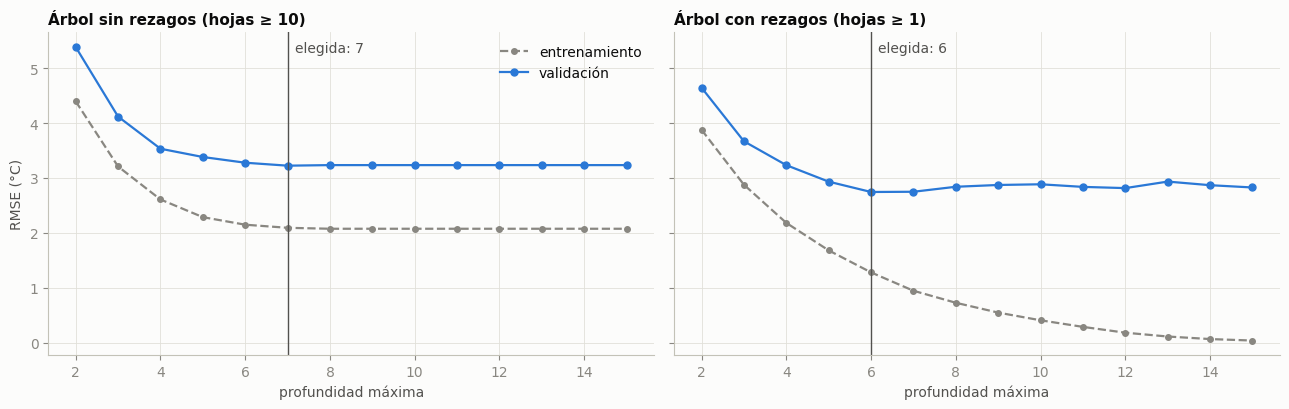

In [39]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for eje, (nombre, gs) in zip(ejes, busquedas.items()):
    r = pd.DataFrame(gs.cv_results_)
    hoja = gs.best_params_['modelo__min_samples_leaf']
    r = r[r['param_modelo__min_samples_leaf'] == hoja].sort_values('param_modelo__max_depth')
    prof = r['param_modelo__max_depth'].astype(int)
    eje.plot(prof, -r['mean_train_score'], color=TENUE, linestyle='--', marker='o', markersize=4, label='entrenamiento')
    eje.plot(prof, -r['mean_test_score'], color=COLOR['Planta 1'], marker='o', markersize=5, label='validación')
    mejor = gs.best_params_['modelo__max_depth']
    eje.axvline(mejor, color=TINTA2, linewidth=1)
    eje.annotate(f'elegida: {mejor}', xy=(mejor, 1), xycoords=('data', 'axes fraction'), xytext=(5, -14),
                 textcoords='offset points', color=TINTA2)
    eje.set_title(f'{nombre[3:]} (hojas ≥ {hoja})', loc='left'); eje.set_xlabel('profundidad máxima')
ejes[0].set_ylabel('RMSE (°C)'); ejes[0].legend()
fig.tight_layout(); guardar(fig, 't3_curva_profundidad'); plt.show()

**Interpretación** Esta es la curva solicitada: el error en entrenamiento contra el error en validación según la profundidad.
- **Árbol sin rezagos:** el mejor es **profundidad 7, con al menos 10 registros por hoja** (RMSE de validación de 3,22 °C). Desde la profundidad 6 o 7 la validación deja de mejorar: más profundidad ya no aprende nada nuevo.
- **Árbol con rezagos:** el mejor es **profundidad 6** (2,74 °C). Aquí se ve el **sobreajuste de libro**: con más profundidad el error de entrenamiento baja casi a 0 (el árbol memoriza cada dato), mientras que el de validación sube. LO que se conoce como el árbol "condenado al éxito al entrenar": las dos curvas bajan juntas hasta un punto y después se separan de golpe.
- Aun con la mejor profundidad, **los dos árboles tienen más error de validación que las regresiones lineales** (3,22 contra 2,64 °C sin rezagos, y 2,74 contra 1,78 °C con rezagos). La sección 3.2 lo confirma en la prueba.

### Importancia de variables en los árboles
Dice qué predictores usó cada árbol para cortar y cuánto redujo el error con cada uno. Se relaciona con la física de la Tarea 1.

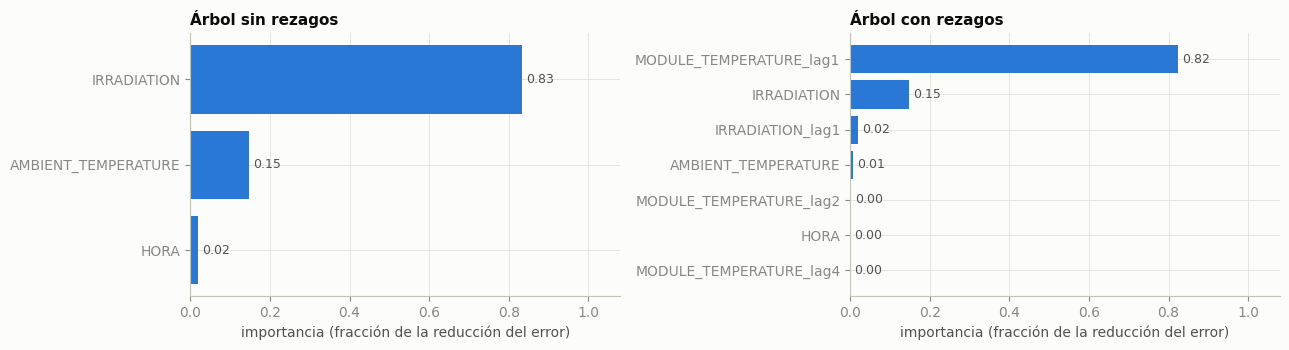

,6. Árbol sin rezagos,7. Árbol con rezagos
AMBIENT_TEMPERATURE,0.148,0.007
HORA,0.019,0.001
IRRADIATION,0.833,0.147
IRRADIATION_lag1,—,0.020
MODULE_TEMPERATURE_lag1,—,0.823
MODULE_TEMPERATURE_lag2,—,0.002
MODULE_TEMPERATURE_lag4,—,0.000


In [40]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.6))
importancias = {}
for eje, (nombre, gs) in zip(ejes, busquedas.items()):
    F = modelos[nombre][1]
    imp = pd.Series(gs.best_estimator_.named_steps['modelo'].feature_importances_, index=F).sort_values()
    importancias[nombre] = imp
    eje.barh(imp.index, imp.values, color=COLOR['Planta 1'])
    for i, v in enumerate(imp.values):
        eje.annotate(f'{v:.2f}', (v, i), xytext=(3, 0), textcoords='offset points', va='center', color=TINTA2, fontsize=9)
    eje.set_xlim(0, 1.08); eje.set_xlabel('importancia (fracción de la reducción del error)')
    eje.set_title(f'{nombre[3:]}', loc='left')
fig.tight_layout(); guardar(fig, 't3_importancia_arbol'); plt.show()
display(pd.DataFrame(importancias).round(3).fillna('—'))

**Interpretación**
- **Árbol sin rezagos:** la irradiación explica el **83 %** de la reducción del error, la temperatura ambiente el 15 % y la hora el 2 %. **Es el orden que predice la física** (modelo de Ross): el sol es lo que más calienta el módulo y el aire fija la base. Coincide con los coeficientes estandarizados de la regresión (sección 3.4).
- **Árbol con rezagos:** la temperatura del módulo de 15 minutos antes se lleva el **82 %** y la irradiación del instante el 15 %. El árbol se comporta como una **persistencia por tramos corregida por el sol**. Por eso solo mejora la persistencia en un 20 % (sección 3.2).
- Una importancia de 0 (los rezagos de 30 y 60 minutos, la hora) **no prueba que la variable no sirva**: casi toda su información ya está en el rezago de 15 minutos, con el que está muy correlacionada.

### Modelos de ensamble (opcional)
LOs realizamos como modelos opcionales. **Random Forest** entrena cientos de árboles con muestras distintas de los datos y los **promedia** (baja la varianza). **Gradient Boosting** entrena árboles pequeños en serie, cada uno sobre el error que dejaron los anteriores, y los **suma** (baja el sesgo). Se entrenan con los predictores del modelo 5 y **la misma validación cruzada** (`TimeSeriesSplit(5)`), para que compitan en igualdad de condiciones.

> **Decisión: los ensambles se dejan como modelos de comparación.** Son opcionales en el Proyecto. Aparecen en el notebook y en la tabla del informe, pero el modelo elegido sigue siendo la regresión lineal: se recomienda que, si empatan, se prefiera la lineal, porque es más simple y se interpreta con coeficientes.

In [41]:
busquedas_ens = {}
for nombre, estimador, rejilla in [
        ('8. Random Forest con rezagos', RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE), REJILLA_RF),
        ('9. Gradient Boosting con rezagos', HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE), REJILLA_GB)]:
    gs = GridSearchCV(tubo_arbol(estimador), rejilla, cv=tscv, scoring='neg_root_mean_squared_error', return_train_score=True)
    gs.fit(train[F_CON], train[OBJETIVO])
    busquedas_ens[nombre] = gs
    modelos[nombre] = (gs.best_estimator_, F_CON)
    cv_rmse[nombre] = -np.array([gs.cv_results_[f'split{i}_test_score'][gs.best_index_] for i in range(5)])
    print(f'{nombre}: mejor {gs.best_params_} | RMSE de validación media {-gs.best_score_:.2f} °C')
imp_rf = pd.Series(busquedas_ens['8. Random Forest con rezagos'].best_estimator_.named_steps['modelo'].feature_importances_, index=F_CON)
print('Importancia de variables del Random Forest:', imp_rf.sort_values(ascending=False).round(3).to_dict())

8. Random Forest con rezagos: mejor {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1} | RMSE de validación media 2.14 °C


9. Gradient Boosting con rezagos: mejor {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3} | RMSE de validación media 2.00 °C
Importancia de variables del Random Forest: {'MODULE_TEMPERATURE_lag1': 0.675, 'IRRADIATION_lag1': 0.197, 'IRRADIATION': 0.104, 'AMBIENT_TEMPERATURE': 0.012, 'MODULE_TEMPERATURE_lag2': 0.006, 'MODULE_TEMPERATURE_lag4': 0.004, 'HORA': 0.002}


### Líneas base sin entrenamiento: persistencia y persistencia diaria
- La **persistencia** predice que la temperatura del módulo es la de **15 minutos antes**.
- La **persistencia diaria** predice que es la del **mismo instante del día anterior** (24 horas antes). Es el *seasonal naive* o ingenuo estacional visto en las clases: en series con un ciclo diario tan marcado suele ser difícil de superar.

Ninguna de las dos se entrena: solo copian un valor pasado.

In [42]:
class Persistencia:
    """Línea base sin entrenamiento: la predicción es un valor pasado de la propia temperatura del módulo."""
    def __init__(self, columna):
        self.columna = columna

    def predict(self, X):
        return X[self.columna].to_numpy()


modelos['2. Base: persistencia'] = (Persistencia('MODULE_TEMPERATURE_lag1'), ['MODULE_TEMPERATURE_lag1'])
modelos['3. Base: persistencia diaria'] = (Persistencia('MODULE_TEMPERATURE_lag96'), ['MODULE_TEMPERATURE_lag96'])
modelos = dict(sorted(modelos.items()))   # ordenar por número
sin_dia_anterior = {n: int(d['MODULE_TEMPERATURE_lag96'].isna().sum()) for n, d in
                    [('entrenamiento', train), ('prueba P1', test), ('Planta 2', p2)]}
print('Instantes sin el valor del día anterior (la persistencia diaria no se evalúa en ellos):', sin_dia_anterior)

Instantes sin el valor del día anterior (la persistencia diaria no se evalúa en ellos): {'entrenamiento': 66, 'prueba P1': 0, 'Planta 2': 44}


## 3.2 Comparación de todos los modelos
MAPE, RMSE y MAE en **entrenamiento**, en la **prueba de la Planta 1** y en la **Planta 2 sin reentrenar**, más la **habilidad** frente a la persistencia en cada conjunto. La habilidad es mayor que 0 si el modelo mejora la persistencia y negativa si es peor que repetir el último valor. La columna "RMSE prueba / entrenamiento" mide el sobreajuste: si es mucho mayor que 1, el modelo memorizó.

In [43]:
filas = []
predicciones = {}
for nombre, (m, F) in modelos.items():
    yhat = {'train': m.predict(train[F]), 'test': m.predict(test[F]), 'p2': m.predict(p2[F])}
    predicciones[nombre] = yhat
    fila = {'modelo': nombre}
    for etiqueta, datos_eval, clave in [('entren.', train, 'train'), ('prueba P1', test, 'test'), ('Planta 2', p2, 'p2')]:
        for k, v in metricas(datos_eval[OBJETIVO], yhat[clave]).items():
            fila[(etiqueta, k)] = v
    fila[('validación', 'RMSE')] = cv_rmse[nombre].mean() if nombre in cv_rmse else np.nan
    filas.append(fila)
tabla = pd.DataFrame(filas).set_index('modelo')
tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
for conjunto in ('prueba P1', 'Planta 2'):
    tabla[(conjunto, 'habilidad')] = 1 - tabla[(conjunto, 'RMSE')] / tabla.loc['2. Base: persistencia', (conjunto, 'RMSE')]
tabla[('sobreajuste', 'RMSE prueba / entren.')] = tabla[('prueba P1', 'RMSE')] / tabla[('entren.', 'RMSE')]
orden = [(c, k) for c in ('entren.', 'validación', 'prueba P1', 'Planta 2', 'sobreajuste')
         for k in ('MAPE %', 'RMSE', 'MAE', 'habilidad', 'RMSE prueba / entren.') if (c, k) in tabla.columns]
tabla = tabla[orden]
display(tabla.round(3))

print(f'T. del módulo con sol: de {p1[OBJETIVO].min():.1f} a {p1[OBJETIVO].max():.1f} °C en la Planta 1 y de '
      f'{p2[OBJETIVO].min():.1f} a {p2[OBJETIVO].max():.1f} °C en la Planta 2 (nunca cerca de 0: el MAPE se puede usar)')
print('Tabla comparativa de la guía (prueba de la Planta 1, de mejor a peor RMSE):')
display(tabla['prueba P1'].sort_values('RMSE').round(3))

entren.               validación prueba P1                         Planta 2                          \
                                  MAPE %   RMSE    MAE       RMSE    MAPE %   RMSE    MAE habilidad   MAPE %   RMSE    MAE habilidad   
modelo                                                                                                                                 
1. Base: T. ambiente sola         15.020  7.310  6.040      7.550    11.723  5.161  4.193    -0.795   18.899  8.959  7.055    -2.226   
2. Base: persistencia              6.130  3.483  2.543        NaN     5.676  2.875  2.146     0.000    4.928  2.778  2.012     0.000   
3. Base: persistencia diaria      12.968  7.236  5.265        NaN    13.174  6.814  5.051    -1.370   11.743  6.832  4.728    -1.460   
4. Lineal sin rezagos              4.681  2.589  1.937      2.644     3.877  2.046  1.491     0.288    9.362  4.640  3.973    -0.670   
5. Lineal con rezagos              3.001  1.665  1.244      1.781     2.698  1.472  1.030     0.488    5.718  3.085  2.477    -0.111   
6. Árbol sin rezagos               3.645  2.107  1.567      3.223     5.526  2.877  2.093    -0.000    9.076  4.634  3.720    -0.668   
7. Árbol con rezagos               2.975  1.712  1.293      2.744     4.404  2.309  1.689     0.197    4.838  2.722  2.024     0.020   
8. Random Forest con rezagos       1.081  0.673  0.467      2.137     3.265  1.747  1.251     0.392    4.285  2.406  1.820     0.134   
9. Gradient Boosting con rezagos   1.752  1.014  0.751      1.996     2.858  1.496  1.094     0.480    5.363  2.953  2.311    -0.063   

                                           sobreajuste  
                                 RMSE prueba / entren.  
modelo                                                  
1. Base: T. ambiente sola                        0.706  
2. Base: persistencia                            0.825  
3. Base: persistencia diaria                     0.942  
4. Lineal sin rezagos                            0.790  
5. Lineal con rezagos                            0.884  
6. Árbol sin rezagos                             1.365  
7. Árbol con rezagos                             1.348  
8. Random Forest con rezagos                     2.597  
9. Gradient Boosting con rezagos                 1.475

T. del módulo con sol: de 19.9 a 65.5 °C en la Planta 1 y de 21.8 a 66.6 °C en la Planta 2 (nunca cerca de 0: el MAPE se puede usar)
Tabla comparativa de la guía (prueba de la Planta 1, de mejor a peor RMSE):


,MAPE %,RMSE,MAE,habilidad
modelo,,,,
5. Lineal con rezagos,2.698,1.472,1.030,0.488
9. Gradient Boosting con rezagos,2.858,1.496,1.094,0.480
8. Random Forest con rezagos,3.265,1.747,1.251,0.392
4. Lineal sin rezagos,3.877,2.046,1.491,0.288
7. Árbol con rezagos,4.404,2.309,1.689,0.197
2. Base: persistencia,5.676,2.875,2.146,0.000
6. Árbol sin rezagos,5.526,2.877,2.093,-0.000
1. Base: T. ambiente sola,11.723,5.161,4.193,-0.795
3. Base: persistencia diaria,13.174,6.814,5.051,-1.370


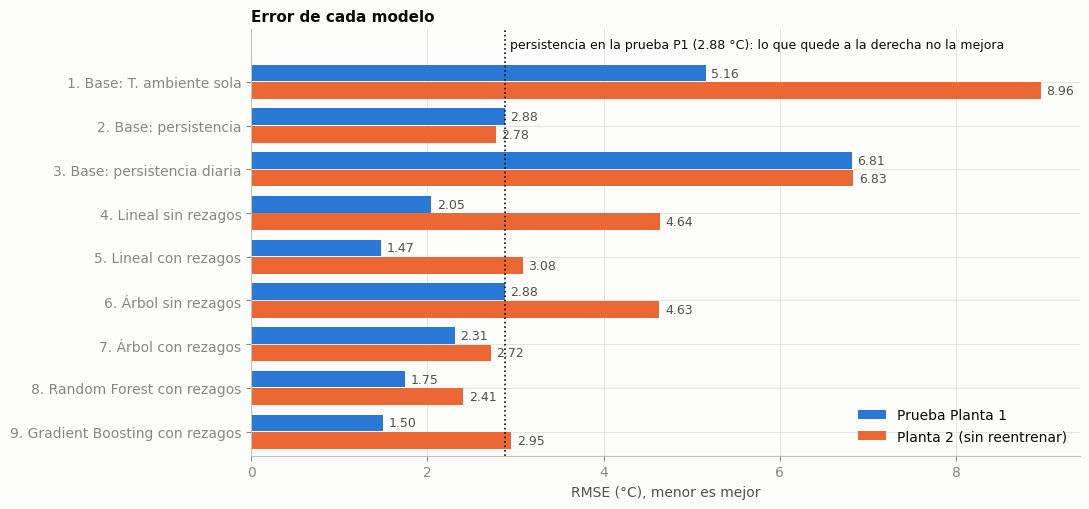

In [44]:
fig, eje = plt.subplots(figsize=(11, 5.2))
nombres = list(tabla.index)
y = np.arange(len(nombres))
eje.barh(y - 0.2, tabla[('prueba P1', 'RMSE')], height=0.38, color=COLOR['Planta 1'], label='Prueba Planta 1')
eje.barh(y + 0.2, tabla[('Planta 2', 'RMSE')], height=0.38, color=COLOR['Planta 2'], label='Planta 2 (sin reentrenar)')
for i, n in enumerate(nombres):
    eje.annotate(f"{tabla.loc[n, ('prueba P1', 'RMSE')]:.2f}", (tabla.loc[n, ('prueba P1', 'RMSE')], i - 0.2),
                 xytext=(4, 0), textcoords='offset points', va='center', color=TINTA2, fontsize=9)
    eje.annotate(f"{tabla.loc[n, ('Planta 2', 'RMSE')]:.2f}", (tabla.loc[n, ('Planta 2', 'RMSE')], i + 0.2),
                 xytext=(4, 0), textcoords='offset points', va='center', color=TINTA2, fontsize=9)
rmse_pers = tabla.loc['2. Base: persistencia', ('prueba P1', 'RMSE')]
eje.axvline(rmse_pers, color=TINTA, linestyle=':', linewidth=1.2)
eje.annotate(f'persistencia en la prueba P1 ({rmse_pers:.2f} °C): lo que quede a la derecha no la mejora', (rmse_pers, -0.85),
             xytext=(4, 0), textcoords='offset points', va='center', color=TINTA, fontsize=9)
eje.set_yticks(y); eje.set_yticklabels(nombres); eje.set_ylim(len(nombres) - 0.45, -1.2)
eje.set_xlabel('RMSE (°C), menor es mejor'); eje.set_title('Error de cada modelo', loc='left'); eje.legend(loc='lower right')
fig.tight_layout(); guardar(fig, 't3_comparacion_modelos'); plt.show()

**Interpretación** La columna clave es la **habilidad**: cuánto mejora cada modelo a la persistencia en la prueba.
- **Líneas base.** La temperatura ambiente sola es débil (MAPE de 11,7 %, RMSE de 5,16 °C), porque no sabe si hay sol. La persistencia es fuerte (MAPE de 5,7 %, RMSE de 2,88 °C), porque en 15 minutos el módulo cambia poco.
- **La persistencia diaria es la peor de todas** (MAPE de 13,2 %, RMSE de 6,81 °C, habilidad de −1,37): se equivoca más del doble que la persistencia de 15 minutos. El ciclo diario es claro, pero **lo que cambia de un día a otro son las nubes**: copiar la temperatura de ayer a la misma hora falla si ayer estuvo despejado y hoy nublado. Es lo que se vio en el paso 10.2: sin el ciclo diario, la autocorrelación a 24 horas cae a 0,24.
- **La regresión lineal sin rezagos le gana a las líneas base** (MAPE de 3,9 %, RMSE de 2,05 °C, habilidad de 0,29). Con solo el clima del momento, sin conocer la historia del módulo, predice mejor que copiar el último valor. Por eso sirve como **temperatura esperada según el clima** para las alertas (sección 3.6).
- **El mejor modelo es la regresión lineal con rezagos:** MAPE de **2,7 %**, RMSE de **1,47 °C**, MAE de 1,03 °C y **habilidad de 0,49**, es decir, **49 % menos error que la persistencia** y 28 % menos que la regresión sin rezagos.
- **La regresión lineal supera al árbol de decisión**, sin rezagos (2,05 contra 2,88 °C) y con rezagos (1,47 contra 2,31 °C). **El árbol sin rezagos empata con la persistencia** (habilidad de 0,00): no aporta nada. La razón es física: el calentamiento del módulo es casi lineal con la irradiación (modelo de Ross; r = 0,95 en el EDA). El árbol tiene que imitar una recta con "escalones" y no puede predecir fuera de los valores que vio al entrenar.
- **Ensambles (opcionales).** El **Gradient Boosting prácticamente empata** con la regresión lineal con rezagos (RMSE de 1,50 contra 1,47 °C; MAPE de 2,9 contra 2,7 %). El **Random Forest** queda detrás (1,75 °C) y es el modelo más sobreajustado: su error de prueba es 2,6 veces el de entrenamiento. Como dice la guía, **si un modelo complejo empata con la lineal, se prefiere la lineal**: es más simple y se interpreta con coeficientes. Un modelo complejo solo gana si hay algo no lineal que aprender, y aquí la relación es casi lineal.
- **Sobreajuste.** En los árboles y los ensambles, el error de entrenamiento es mucho menor que el de validación (por ejemplo, 0,67 contra 2,14 °C en el Random Forest): memorizan. En las regresiones lineales los dos son casi iguales (2,59 contra 2,64 °C sin rezagos y 1,67 contra 1,78 °C con rezagos): **no hay sobreajuste**. El cociente prueba / entrenamiento de las lineales es menor que 1 (0,79 y 0,88) porque la semana de prueba fue más nublada y fresca (paso 11), con errores absolutos más pequeños.
- **La validación (`TimeSeriesSplit`) ordena los modelos igual que la prueba**: lineal con rezagos, Gradient Boosting, Random Forest, lineal sin rezagos, árbol con rezagos, árbol sin rezagos y temperatura ambiente sola. Habríamos elegido el mismo modelo sin mirar la prueba, como debe ser.
- **Un MAPE bajo no es mérito por sí solo:** con sol, la temperatura del módulo nunca baja de unos 20 °C, así que todos los MAPE son pequeños. Por eso la habilidad frente a la persistencia es la métrica que manda.

### ¿Cuánto aporta el clima sobre la historia del módulo?
Entrenando la **misma regresión lineal** con tres grupos de predictorestenemos: **solo la historia** del módulo (sus rezagos y la hora), **solo el clima** (irradiación y temperatura ambiente) y **los dos juntos** (el modelo 5). Planteandose así: qué pasa si solo se usan los valores pasados, si solo se usan los sensores o si se combinan.

MAPE %               RMSE                MAE          
datos            Planta 2 prueba P1 Planta 2 prueba P1 Planta 2 prueba P1
grupo                                                                    
solo historia        4.36      4.93     2.54      2.65     1.75      1.87
solo clima           6.72      3.21     3.67      1.75     2.93      1.25
historia + clima     5.72      2.70     3.08      1.47     2.48      1.03

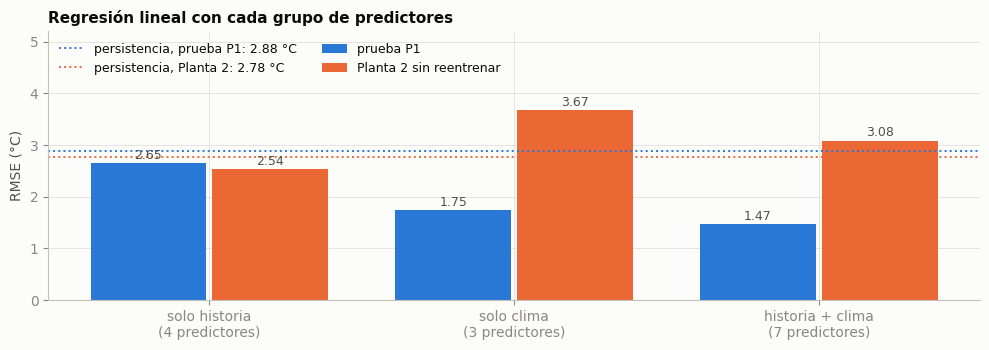

In [45]:
grupos = {'solo historia': HISTORIA, 'solo clima': CLIMA, 'historia + clima': F_CON}
filas = []
for nombre, F in grupos.items():
    m = tubo_lineal().fit(train[F], train[OBJETIVO])
    for conjunto, d in [('prueba P1', test), ('Planta 2', p2)]:
        filas.append({'grupo': nombre, 'predictores': len(F), 'datos': conjunto, **metricas(d[OBJETIVO], m.predict(d[F]))})
ablacion = pd.DataFrame(filas)
display(ablacion.pivot(index='grupo', columns='datos', values=['MAPE %', 'RMSE', 'MAE']).loc[list(grupos)].round(2))

fig, eje = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(grupos))
for desplaza, (conjunto, n) in zip((-0.2, 0.2), [('prueba P1', 'Planta 1'), ('Planta 2', 'Planta 2')]):
    v = ablacion[ablacion['datos'] == conjunto].set_index('grupo').loc[list(grupos), 'RMSE']
    eje.bar(x + desplaza, v.values, width=0.38, color=COLOR[n], label=conjunto if n == 'Planta 1' else 'Planta 2 sin reentrenar')
    for xi, vi in zip(x + desplaza, v.values):
        eje.annotate(f'{vi:.2f}', (xi, vi), xytext=(0, 3), textcoords='offset points', ha='center', color=TINTA2, fontsize=9)
    rp = tabla.loc['2. Base: persistencia', (conjunto, 'RMSE')]
    eje.axhline(rp, color=COLOR[n], linestyle=':', linewidth=1.4, label=f'persistencia, {conjunto}: {rp:.2f} °C')
eje.set_xticks(x); eje.set_xticklabels([f'{g}\n({len(F)} predictores)' for g, F in grupos.items()])
eje.set_ylim(0, 5.2); eje.set_ylabel('RMSE (°C)'); eje.set_title('Regresión lineal con cada grupo de predictores', loc='left')
eje.legend(loc='upper left', ncol=2, fontsize=9)
fig.tight_layout(); guardar(fig, 't3_grupos_predictores'); plt.show()

**Interpretación**
- **En la prueba de la Planta 1 el clima aporta más que la historia.** Solo con la historia del módulo el RMSE es de 2,65 °C (apenas mejor que la persistencia, 2,88). Solo con el clima baja a 1,75 °C. Juntos llegan a **1,47 °C**: **el clima del instante dice hacia dónde va la temperatura y los rezagos dicen de dónde viene**. Se complementan.
- **Ojo:** "solo clima" no es el modelo 4. Lleva la irradiación de 15 minutos antes y no lleva la hora. Que mejore al modelo 4 (1,75 contra 2,05 °C) confirma la **inercia térmica** del paso 10.3.
- **En la Planta 2 el orden se invierte.** Ahí gana "solo historia" (2,54 °C, mejor que la persistencia de esa planta, 2,78), y "solo clima" es el peor (3,67 °C). La parte de clima **trae la física de la Planta 1** (su k de 27,4 °C por kW/m²), que no aplica en la Planta 2. La historia usa la temperatura reciente del propio módulo, que ya "conoce" la planta.
- **Respuesta a la pregunta de la guía:** las variables meteorológicas **sí aportan** sobre la historia del módulo, pero ese aporte es **propio de cada planta**. Sin recalibrar, un modelo que se apoya en la historia se transfiere mejor (sección 3.5).

### Prueba de fuga de información
FUe advertido que: **si el modelo funciona demasiado bien, preocúpense**, porque lo más probable es que se esté colando información que no se tendría en la operación. Para mostrar cómo se vería, se agrega al modelo 5 la diferencia **módulo − aire del mismo instante**, que se calcula con el objetivo. **Este modelo no se usa**: solo sirve para justificar por qué esa variable no entra.

In [46]:
X_fuga_train = train[F_CON].assign(DIF=train[OBJETIVO] - train['AMBIENT_TEMPERATURE'])
X_fuga_test = test[F_CON].assign(DIF=test[OBJETIVO] - test['AMBIENT_TEMPERATURE'])
con_fuga = tubo_lineal().fit(X_fuga_train, train[OBJETIVO])
fuga = {'sin fuga (modelo 5)': metricas(test[OBJETIVO], modelos['5. Lineal con rezagos'][0].predict(test[F_CON])),
        'con fuga (+ módulo − aire en t)': metricas(test[OBJETIVO], con_fuga.predict(X_fuga_test))}
display(pd.DataFrame(fuga).T.round(4))

,MAPE %,RMSE,MAE
sin fuga (modelo 5),2.6985,1.472,1.0298
con fuga (+ módulo − aire en t),0.0000,0.000,0.0000


**Interpretación**
- Con la diferencia módulo − aire del mismo instante, **el error cae a 0** (MAPE de 0,00 %, RMSE de 0,000 °C). No es que el modelo aprenda: la temperatura del módulo es exactamente la del aire más esa diferencia, y la regresión solo la copia.
- **Por eso esa variable no entra a ningún modelo** y solo se usó en el EDA para explorar (paso 9). En la operación, la diferencia no existe antes de medir la temperatura del módulo, que es justo lo que se quiere estimar.
- **Nuestro mejor modelo no tiene señales de fuga:** su MAPE es de 2,7 % y mejora la persistencia en un 49 %, lejos del error casi nulo de un modelo con fuga. Todos sus predictores están en la tabla de la sección 3.0 con el momento en que se conocen.

## 3.3 El mejor modelo: real contra predicho, residuos y dónde falla

Mejor modelo en la prueba de la Planta 1: 5. Lineal con rezagos


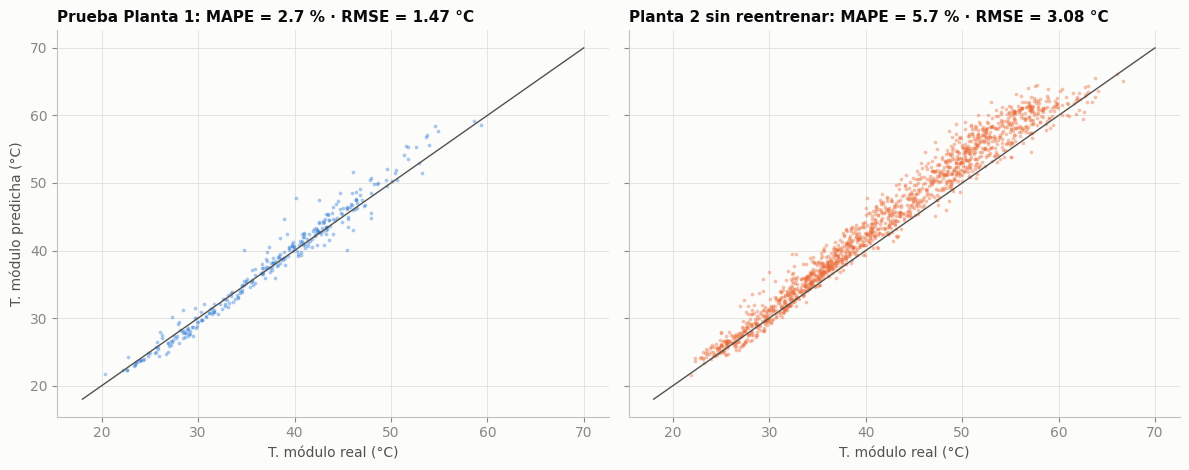

In [47]:
mejor = tabla[('prueba P1', 'RMSE')].idxmin()
m_mejor, F_mejor = modelos[mejor]
print('Mejor modelo en la prueba de la Planta 1:', mejor)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for eje, (etq, d, clave, n) in zip(ejes, [('Prueba Planta 1', test, 'test', 'Planta 1'), ('Planta 2 sin reentrenar', p2, 'p2', 'Planta 2')]):
    eje.scatter(d[OBJETIVO], predicciones[mejor][clave], s=7, alpha=0.4, color=COLOR[n], linewidths=0)
    lim = [18, 70]; eje.plot(lim, lim, color=TINTA2, linewidth=1)
    r = metricas(d[OBJETIVO], predicciones[mejor][clave])
    eje.set_title(f"{etq}: MAPE = {r['MAPE %']:.1f} % · RMSE = {r['RMSE']:.2f} °C", loc='left')
    eje.set_xlabel('T. módulo real (°C)')
ejes[0].set_ylabel('T. módulo predicha (°C)')
fig.tight_layout(); guardar(fig, 't3_real_vs_predicho'); plt.show()

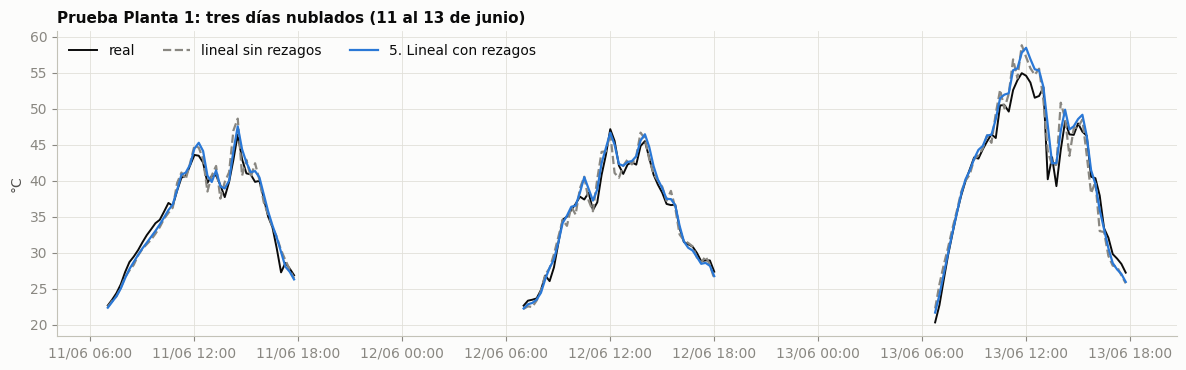

In [48]:
dias = test.loc['2020-06-11':'2020-06-13']
rejilla_dias = pd.date_range('2020-06-11 05:00', '2020-06-13 19:00', freq='15min')   # la noche queda vacía (sin línea)
serie = lambda valores: pd.Series(valores, index=dias.index).reindex(rejilla_dias)
fig, eje = plt.subplots(figsize=(12, 3.8))
eje.plot(rejilla_dias, serie(dias[OBJETIVO].to_numpy()), color=TINTA, linewidth=1.4, label='real')
eje.plot(rejilla_dias, serie(modelos['4. Lineal sin rezagos'][0].predict(dias[F_SIN])), color=TENUE, linestyle='--', label='lineal sin rezagos')
eje.plot(rejilla_dias, serie(m_mejor.predict(dias[F_mejor])), color=COLOR['Planta 1'], label=mejor)
eje.set_ylabel('°C'); eje.set_title('Prueba Planta 1: tres días nublados (11 al 13 de junio)', loc='left'); eje.legend(ncol=3)
eje.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.tight_layout(); guardar(fig, 't3_serie_prueba'); plt.show()

### Residuos: supuestos de la regresión
Como se solicito, los residuos (real − predicho) deben estar **acotados y parejos**: centrados en 0, sin forma contra lo predicho, con un histograma parecido a una campana y **sin memoria en el tiempo**. La tercera columna es la autocorrelación de los residuos (buscada por fecha, hasta 4 horas): si sale de la banda gris, al modelo todavía le queda memoria por aprovechar.

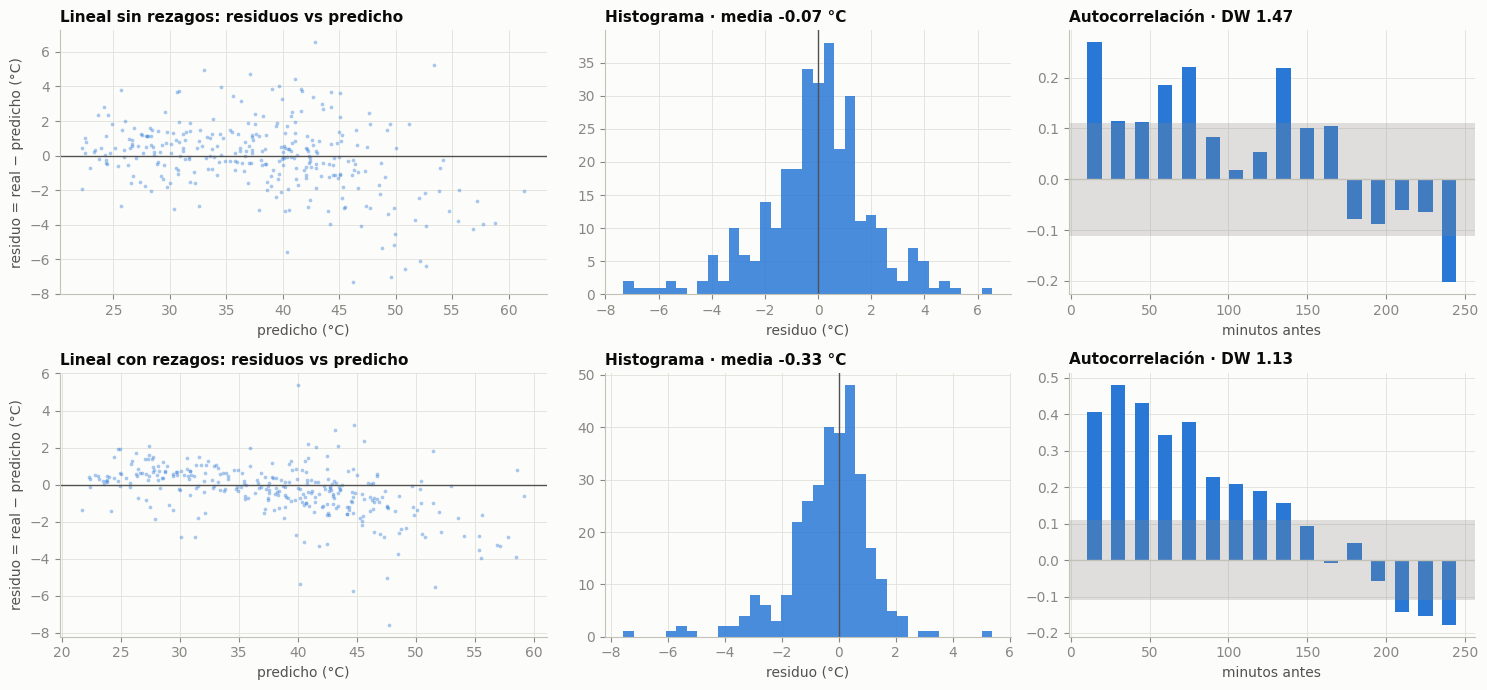

,media,DW,acf1,asimetria
4. Lineal sin rezagos,-0.068,1.466,0.269,-0.438
5. Lineal con rezagos,-0.330,1.127,0.406,-0.982


In [49]:
def acf_por_fecha(res, rezagos=range(1, 17)):
    # Autocorrelación de los residuos buscando el instante k × 15 min antes por fecha (no cruza las noches).
    return pd.Series([res.corr(res.shift(k, freq='15min').reindex(res.index)) for k in rezagos], index=list(rezagos))

fig, ejes = plt.subplots(2, 3, figsize=(15, 7), gridspec_kw={'width_ratios': [1.2, 1, 1]})
diag_residuos = {}
for fila, nombre in enumerate(['4. Lineal sin rezagos', mejor]):
    m, F = modelos[nombre]
    pred = m.predict(test[F]); res = test[OBJETIVO] - pred
    acf_res = acf_por_fecha(res)
    banda = 1.96 / np.sqrt(len(res))
    diag_residuos[nombre] = {'media': res.mean(), 'DW': durbin_watson(res), 'acf1': acf_res[1], 'asimetria': res.skew()}
    ejes[fila, 0].scatter(pred, res, s=7, alpha=0.4, color=COLOR['Planta 1'], linewidths=0)
    ejes[fila, 0].axhline(0, color=TINTA2, linewidth=1)
    ejes[fila, 0].set_title(f'{nombre[3:]}: residuos vs predicho', loc='left'); ejes[fila, 0].set_xlabel('predicho (°C)')
    ejes[fila, 0].set_ylabel('residuo = real − predicho (°C)')
    ejes[fila, 1].hist(res, bins=35, color=COLOR['Planta 1'], alpha=0.85)
    ejes[fila, 1].axvline(0, color=TINTA2, linewidth=1)
    ejes[fila, 1].set_title(f'Histograma · media {res.mean():.2f} °C', loc='left'); ejes[fila, 1].set_xlabel('residuo (°C)')
    ejes[fila, 2].bar(np.array(acf_res.index) * 15, acf_res.values, width=9, color=COLOR['Planta 1'])
    ejes[fila, 2].axhspan(-banda, banda, color=TENUE, alpha=0.25, linewidth=0)
    ejes[fila, 2].axhline(0, color=EJE, linewidth=1)
    ejes[fila, 2].set_title(f'Autocorrelación · DW {durbin_watson(res):.2f}', loc='left'); ejes[fila, 2].set_xlabel('minutos antes')
fig.tight_layout(); guardar(fig, 't3_residuos'); plt.show()
display(pd.DataFrame(diag_residuos).T.round(3))

### ¿Dónde falla? Error por hora del día y por día
La guía pide decir a qué horas y en qué días se equivoca más el mejor modelo.

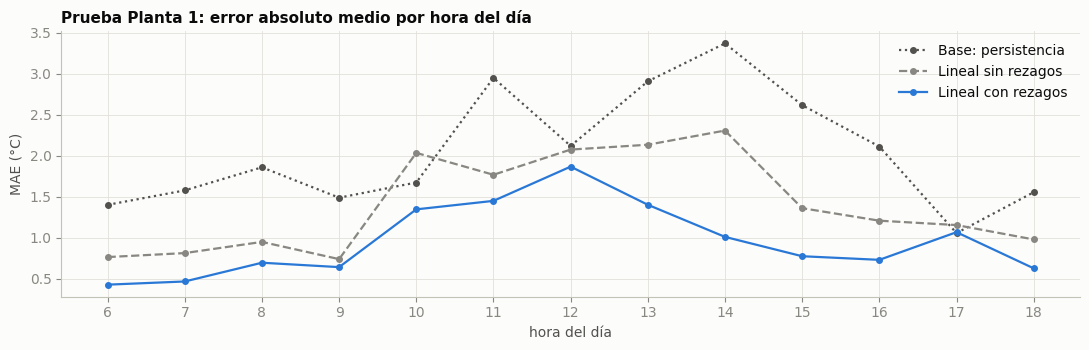

MAE (°C) por hora del día en la prueba de la Planta 1:


HORA,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0
Base: persistencia,1.40,1.58,1.86,1.49,1.67,2.95,2.12,2.91,3.37,2.62,2.11,1.06,1.55
Lineal sin rezagos,0.76,0.81,0.95,0.74,2.03,1.77,2.07,2.13,2.31,1.36,1.21,1.15,0.98
Lineal con rezagos,0.43,0.47,0.70,0.64,1.35,1.45,1.87,1.40,1.01,0.77,0.73,1.07,0.63


,Base: persistencia,Lineal sin rezagos,Lineal con rezagos,irradiación media
día,,,,
2020-06-11,1.40,1.07,0.81,0.35
2020-06-12,1.39,0.98,0.72,0.36
2020-06-13,2.15,1.86,1.52,0.56
2020-06-14,2.91,1.96,1.27,0.48
2020-06-15,2.25,1.55,0.94,0.43
2020-06-16,2.66,1.57,0.84,0.40
2020-06-17,2.27,1.44,1.11,0.38


In [50]:
fig, eje = plt.subplots(figsize=(11, 3.6))
hora_entera = np.floor(test['HORA'])
error_hora = {}
for nombre, estilo in [('2. Base: persistencia', dict(color=TINTA2, linestyle=':')),
                       ('4. Lineal sin rezagos', dict(color=TENUE, linestyle='--')),
                       (mejor, dict(color=COLOR['Planta 1']))]:
    e = (test[OBJETIVO] - predicciones[nombre]['test']).abs().groupby(hora_entera).mean()
    error_hora[nombre] = e
    eje.plot(e.index, e.values, marker='o', markersize=4, label=nombre[3:], **estilo)
eje.set_xlabel('hora del día'); eje.set_ylabel('MAE (°C)'); eje.set_xticks(range(6, 19))
eje.set_title('Prueba Planta 1: error absoluto medio por hora del día', loc='left'); eje.legend()
fig.tight_layout(); guardar(fig, 't3_error_por_hora'); plt.show()
print('MAE (°C) por hora del día en la prueba de la Planta 1:')
display(pd.DataFrame({n[3:]: e for n, e in error_hora.items()}).T.round(2))

error_dia = pd.DataFrame({n[3:]: (test[OBJETIVO] - predicciones[n]['test']).abs().groupby(test.index.date).mean()
                          for n in error_hora}).rename_axis('día')
error_dia['irradiación media'] = test['IRRADIATION'].groupby(test.index.date).mean().values
display(error_dia.round(2))

**Interpretación**
- **Real contra predicho.** En la prueba de la Planta 1, los puntos del mejor modelo caen sobre la diagonal (MAPE de 2,7 %). En la Planta 2 la nube queda **por encima de la diagonal**: el modelo **sobreestima** su temperatura (sección 3.5).
- **Serie de tres días nublados.** Los dos modelos siguen las subidas y bajadas por nubes. El modelo con rezagos sigue mejor las caídas rápidas. El modelo sin rezagos a veces "se adelanta" en los picos: como no tiene inercia, responde al instante a la irradiación, mientras que el módulo real tarda unos minutos en calentarse y enfriarse.
- **Revisión de los supuestos de la regresión con los residuos:**

| Supuesto | Sin rezagos | Con rezagos |
|---|---|---|
| Media cero | ✅ −0,07 °C | 🟡 −0,33 °C: sobreestima un poco los momentos más calientes de la semana nublada |
| Linealidad (sin forma en residuos contra predicho) | ✅ Sin patrón claro | 🟡 Residuos negativos por encima de 45 °C |
| Varianza constante | 🟡 La dispersión crece con la temperatura: al mediodía las nubes causan errores más grandes | 🟡 Parecido |
| Normalidad (histograma) | ✅ Aproximada, con algo de cola (asimetría de −0,44) | 🟡 Aproximada, con cola hacia la izquierda (asimetría de −0,98) |
| Independencia (Durbin-Watson ≈ 2 y autocorrelación dentro de la banda) | ❌ DW = 1,47; autocorrelación de 0,27 a 15 minutos | ❌ DW = 1,13; autocorrelación de 0,41 a 15 minutos, fuera de la banda hasta unas 2 horas |

- **Los residuos están acotados:** en la prueba van de unos −8 a +7 °C, sin crecer con el tiempo. 
- **Pero tienen memoria.** Si el modelo se equivoca a las 10:00, a las 10:15 se equivoca parecido. Es normal en series de tiempo y **no invalida las predicciones**, pero hace que los p-valores e intervalos de `statsmodels` (sección 3.4) sean **optimistas**. Como dice la guía, **al modelo todavía le queda memoria por aprovechar** (por ejemplo, con más rezagos).
- **¿Dónde falla?** El mejor modelo se equivoca poco en la mañana (MAE de 0,43 °C a las 6 h) y más **cerca del mediodía** (1,87 °C a las 12 h), cuando las nubes que pasan causan los cambios más bruscos. Le gana a la persistencia en casi todas las horas; a las 17 h empatan.
- **Por días**, los peores son el **13 y el 14 de junio** (MAE de 1,52 y 1,27 °C), los días con más sol de la semana de prueba: más sol con nubes pasajeras significa subidas y bajadas más grandes. El mejor es el 12 de junio (0,72 °C), uno de los días más nublados.

## 3.4 Coeficientes y física (P1) · comparación entre plantas (P2)
Para interpretar los coeficientes en sus unidades (°C por °C, °C por kW/m², °C por hora), se ajusta la regresión **sin rezagos** con `statsmodels`, sin escalar. Así se obtienen los intervalos de confianza y los p-valores. El modelo de Ross predice **T_módulo = T_aire + k·G**: el coeficiente de la temperatura ambiente debería estar cerca de **1** y el de la irradiación cerca de **k (21 a 31 °C por kW/m²)**.

Para comparar con la Planta 2 se ajusta la **misma regresión solo con la Planta 2**, en las mismas fechas de entrenamiento.

In [51]:
p2_train = p2[p2.index < CORTE]
coefs = {}
for n, d in [('Planta 1', train), ('Planta 2', p2_train)]:
    X = sm.add_constant(d[F_SIN])
    ols = sm.OLS(d[OBJETIVO], X).fit()
    ic = ols.conf_int()
    coefs[n] = pd.DataFrame({'coeficiente': ols.params, 'IC 95 % inf': ic[0], 'IC 95 % sup': ic[1], 'p-valor': ols.pvalues})
    print(f'{n}: n = {int(ols.nobs)} | Durbin-Watson = {durbin_watson(ols.resid):.2f}')
tabla_coef = pd.concat(coefs, axis=1)
tabla_coef.index = ['intercepto', 'T. ambiente (°C/°C)', 'irradiación (°C por kW/m²)', 'hora (°C/h)']
display(tabla_coef.round(4))

Planta 1: n = 1191 | Durbin-Watson = 1.55
Planta 2: n = 1211 | Durbin-Watson = 0.81


Planta 1                                    Planta 2                                
                           coeficiente IC 95 % inf IC 95 % sup p-valor coeficiente IC 95 % inf IC 95 % sup p-valor
intercepto                     -9.3631    -10.9526     -7.7736     0.0     -8.1894     -9.4849     -6.8940  0.0000
T. ambiente (°C/°C)             1.4475      1.3652      1.5299     0.0      1.3057      1.2395      1.3718  0.0000
irradiación (°C por kW/m²)     27.3872     26.6816     28.0928     0.0     24.0991     23.5042     24.6940  0.0000
hora (°C/h)                    -0.2143     -0.2845     -0.1442     0.0     -0.1397     -0.2083     -0.0711  0.0001

### Coeficientes estandarizados
Con el `StandardScaler` del `Pipeline`, cada coeficiente dice cuántos °C cambia la predicción al subir **una desviación estándar** el predictor, con los demás fijos. Así se puede comparar qué pesa más aunque las unidades sean distintas.

,Lineal sin rezagos,Lineal con rezagos
AMBIENT_TEMPERATURE,4.56,2.69
HORA,-0.7,-0.46
IRRADIATION,7.48,4.32
IRRADIATION_lag1,—,2.27
MODULE_TEMPERATURE_lag1,—,2.76
MODULE_TEMPERATURE_lag2,—,0.20
MODULE_TEMPERATURE_lag4,—,-0.46


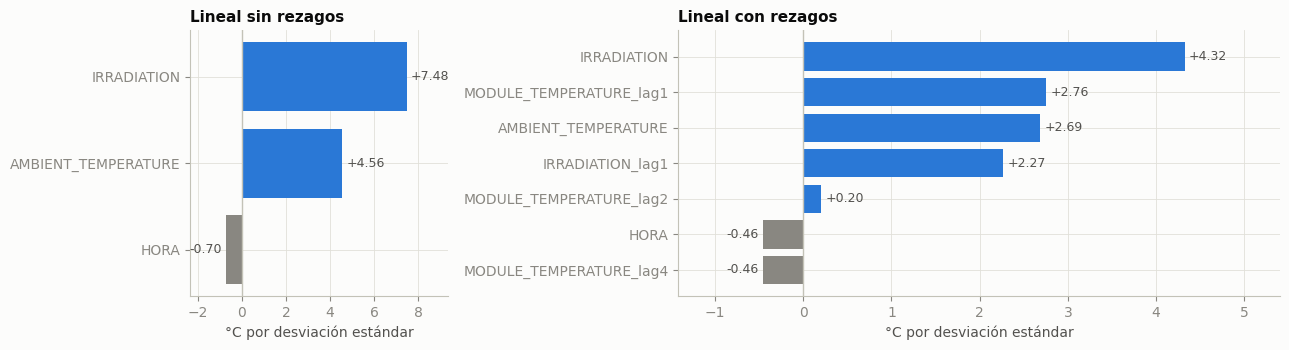

In [52]:
pesos = {n[3:]: pd.Series(modelos[n][0].named_steps['modelo'].coef_, index=modelos[n][1])
         for n in ['4. Lineal sin rezagos', '5. Lineal con rezagos']}
display(pd.DataFrame(pesos).round(2).fillna('—'))

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={'width_ratios': [3, 7]})
for eje, (nombre, p) in zip(ejes, pesos.items()):
    p = p.sort_values()
    eje.barh(p.index, p.values, color=[COLOR['Planta 1'] if v >= 0 else TENUE for v in p.values])
    for i, v in enumerate(p.values):
        eje.annotate(f'{v:+.2f}', (v, i), xytext=(3 if v >= 0 else -3, 0), textcoords='offset points', va='center',
                     ha='left' if v >= 0 else 'right', color=TINTA2, fontsize=9)
    eje.axvline(0, color=EJE, linewidth=1); eje.set_title(nombre, loc='left'); eje.set_xlabel('°C por desviación estándar')
    eje.set_xlim(p.min() - 0.2 * (p.max() - p.min()), p.max() * 1.25)
fig.tight_layout(); guardar(fig, 't3_coef_estandarizados'); plt.show()

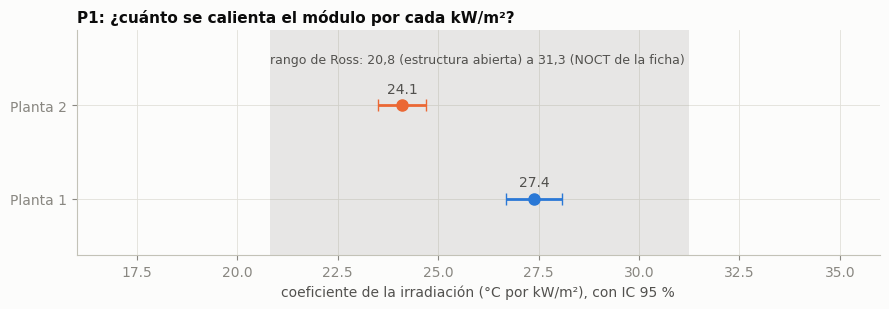

In [53]:
fig, eje = plt.subplots(figsize=(9, 3.2))
for i, n in enumerate(['Planta 1', 'Planta 2']):
    c = coefs[n].loc['IRRADIATION']
    eje.errorbar(c['coeficiente'], i, xerr=[[c['coeficiente'] - c['IC 95 % inf']], [c['IC 95 % sup'] - c['coeficiente']]],
                 fmt='o', color=COLOR[n], markersize=8, capsize=4, linewidth=2)
    eje.annotate(f"{c['coeficiente']:.1f}", (c['coeficiente'], i), xytext=(0, 9), textcoords='offset points',
                 ha='center', color=TINTA2)
eje.axvspan(20.8, 31.25, color=TENUE, alpha=0.18, linewidth=0)
eje.annotate('rango de Ross: 20,8 (estructura abierta) a 31,3 (NOCT de la ficha)', (20.8, 1.45), color=TINTA2, fontsize=9)
eje.set_yticks([0, 1]); eje.set_yticklabels(['Planta 1', 'Planta 2']); eje.set_ylim(-0.6, 1.8); eje.set_xlim(16, 36)
eje.set_xlabel('coeficiente de la irradiación (°C por kW/m²), con IC 95 %')
eje.set_title('P1: ¿cuánto se calienta el módulo por cada kW/m²?', loc='left')
fig.tight_layout(); guardar(fig, 't3_coeficiente_irradiacion'); plt.show()

**Interpretación**
- **Respuesta a P1:** en la Planta 1, el módulo se calienta **27,4 °C por encima de lo que explica la temperatura del aire por cada kW/m² de irradiación** (IC 95 %: 26,7 a 28,1). Queda **dentro del rango de 21 a 31 °C** de la Tarea 1: entre el k de Ross para estructura abierta (20,8, Skoplaki [4]) y el que sale del NOCT de la ficha (31,3, Jinko [6]). La pendiente exploratoria del EDA daba 29,4, un valor coherente.
- **El coeficiente de la temperatura ambiente es 1,45, no 1 como predice Ross.** Una explicación es que la temperatura del aire también recoge efectos que el modelo no tiene, por ejemplo días más calmados (menos viento, que no se midió) y la hora (r = 0,63 con la temperatura ambiente). El modelo es **parecido a Ross, no idéntico**.
- **La hora** tiene un efecto pequeño: −0,21 °C por hora, con el mismo sol y la misma temperatura del aire.
- **Coeficientes estandarizados.** Sin rezagos, la irradiación es la variable que más pesa (7,5 °C por desviación estándar), seguida de la temperatura ambiente (4,6) y la hora (−0,7). Con rezagos, **la irradiación del instante sigue siendo la que más pesa** (4,3), seguida del módulo de 15 minutos antes (2,8), la temperatura ambiente (2,7) y la irradiación de 15 minutos antes (2,3). Los rezagos de 30 y 60 minutos casi no aportan (0,2 y −0,5). Los signos tienen sentido físico: el sol y el aire calientan el módulo. Como los predictores están correlacionados, **se reparten el efecto**, y por eso P1 se responde con el modelo sin rezagos.
- **Comparación entre plantas (P2):** en la Planta 2 el coeficiente de la irradiación es **24,1 °C por kW/m²** (IC 95 %: 23,5 a 24,7). **Los intervalos no se cruzan:** con el mismo sol, el módulo de la Planta 2 se calienta unos **3,3 °C menos por cada kW/m², un 12 % menos**. Posibles causas físicas, según la Tarea 1 (Sandia [10], Skoplaki [4]):
  - mejor ventilación (estructura más alta o más separada);
  - otro tipo de montaje o inclinación;
  - otra tecnología de módulo;
  - el sensor puesto en otro lugar.
- **Cuidado con los intervalos:** como los residuos están autocorrelacionados (Durbin-Watson de 1,55 y 0,81), los intervalos reales son más anchos que los que se muestran. Aun así, la diferencia entre plantas (3,3) es mucho mayor que el ancho de los intervalos (±0,7), así que **probablemente es real**.

## 3.5 Transferencia a la Planta 2 (P2)
Cuánto empeora cada modelo al pasar de la prueba de la Planta 1 a la Planta 2, y si el error es sistemático (sesgo).

In [54]:
transfer = pd.DataFrame({
    'RMSE prueba P1': tabla[('prueba P1', 'RMSE')], 'RMSE Planta 2': tabla[('Planta 2', 'RMSE')],
    'MAPE prueba P1 (%)': tabla[('prueba P1', 'MAPE %')], 'MAPE Planta 2 (%)': tabla[('Planta 2', 'MAPE %')],
    'habilidad Planta 2': tabla[('Planta 2', 'habilidad')]})
transfer['aumento RMSE (%)'] = 100 * (transfer['RMSE Planta 2'] / transfer['RMSE prueba P1'] - 1)
transfer['sesgo en P2 (°C)'] = [float(np.nanmean(p2[OBJETIVO] - predicciones[n]['p2'])) for n in transfer.index]
display(transfer.round(2))

# ¿Dónde se equivoca el modelo sin rezagos en la Planta 2? Sesgo por nivel de irradiación
res_p2 = p2[OBJETIVO] - predicciones['4. Lineal sin rezagos']['p2']
tramos = pd.cut(p2['IRRADIATION'], [0.05, 0.2, 0.4, 0.6, 0.8, 1.2])
print('Sesgo medio del modelo sin rezagos en la Planta 2 por tramo de irradiación (real − predicho, °C):')
print(res_p2.groupby(tramos, observed=True).mean().round(2).to_string())

,RMSE prueba P1,RMSE Planta 2,MAPE prueba P1 (%),MAPE Planta 2 (%),habilidad Planta 2,aumento RMSE (%),sesgo en P2 (°C)
modelo,,,,,,,
1. Base: T. ambiente sola,5.16,8.96,11.72,18.90,-2.23,73.60,-6.21
2. Base: persistencia,2.88,2.78,5.68,4.93,0.00,-3.40,0.19
3. Base: persistencia diaria,6.81,6.83,13.17,11.74,-1.46,0.26,-0.18
4. Lineal sin rezagos,2.05,4.64,3.88,9.36,-0.67,126.77,-3.85
5. Lineal con rezagos,1.47,3.08,2.70,5.72,-0.11,109.56,-2.35
6. Árbol sin rezagos,2.88,4.63,5.53,9.08,-0.67,61.08,-2.87
7. Árbol con rezagos,2.31,2.72,4.40,4.84,0.02,17.89,-0.73
8. Random Forest con rezagos,1.75,2.41,3.26,4.29,0.13,37.72,-1.05
9. Gradient Boosting con rezagos,1.50,2.95,2.86,5.36,-0.06,97.46,-1.81


Sesgo medio del modelo sin rezagos en la Planta 2 por tramo de irradiación (real − predicho, °C):
IRRADIATION
(0.05, 0.2]   -1.83
(0.2, 0.4]    -3.00
(0.4, 0.6]    -4.09
(0.6, 0.8]    -4.89
(0.8, 1.2]    -5.70


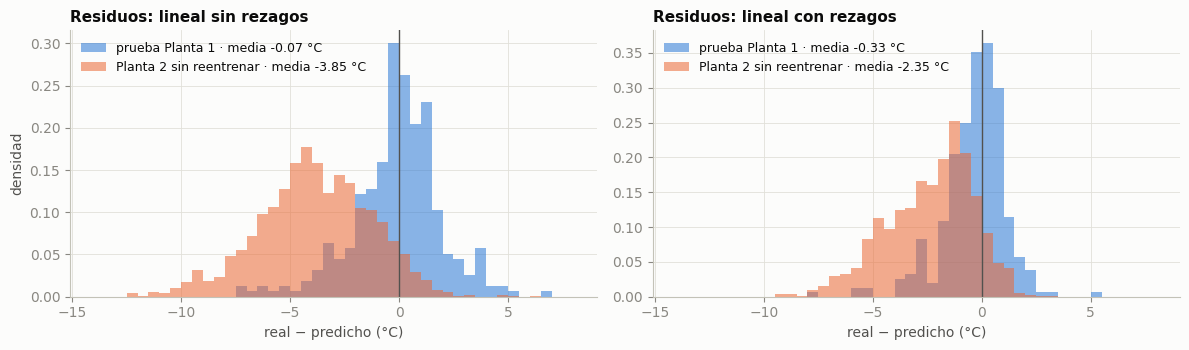

In [55]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
for eje, nombre in zip(ejes, ['4. Lineal sin rezagos', mejor]):
    for n, d, clave, etq in [('Planta 1', test, 'test', 'prueba Planta 1'), ('Planta 2', p2, 'p2', 'Planta 2 sin reentrenar')]:
        res = d[OBJETIVO] - predicciones[nombre][clave]
        eje.hist(res, bins=np.arange(-14, 8.5, 0.5), density=True, alpha=0.55, color=COLOR[n],
                 label=f'{etq} · media {res.mean():+.2f} °C')
    eje.axvline(0, color=TINTA2, linewidth=1)
    eje.set_title(f'Residuos: {nombre[3:].lower()}', loc='left'); eje.set_xlabel('real − predicho (°C)')
    eje.legend(loc='upper left', fontsize=9)
ejes[0].set_ylabel('densidad')
fig.tight_layout(); guardar(fig, 't3_residuos_plantas'); plt.show()

**Interpretación (P2).**
- **El error crece mucho en la Planta 2.** El modelo lineal sin rezagos pasa de un RMSE de 2,05 a **4,64 °C (+127 %)** y de un MAPE de 3,9 a 9,4 %. El lineal con rezagos pasa de 1,47 a **3,08 °C (+110 %)**, y **en la Planta 2 ya no le gana a la persistencia** (habilidad de −0,11).
- **El error es sobre todo sistemático.** El modelo de la Planta 1 **sobreestima la Planta 2 en 3,85 °C en promedio**, y el sesgo **crece con la irradiación**: de −1,8 °C con poca irradiación a −5,7 °C con mucha. Es lo esperable si la Planta 2 tiene un k menor: el modelo aplica 27,4 °C por kW/m² y la Planta 2 solo se calienta 24,1. Los histogramas lo muestran: los residuos de la Planta 2 están **corridos a la izquierda**.
- **Los modelos que se apoyan en la historia del módulo se transfieren mejor.** El árbol con rezagos solo empeora un 18 % (sesgo de −0,7 °C) y el Random Forest un 38 % (sesgo de −1,1 °C). **El Random Forest es el mejor modelo en la Planta 2** (2,41 °C, habilidad de 0,13), porque estos árboles basan la mayor parte de sus cortes en la temperatura del módulo de 15 minutos antes (82 % en el árbol y 68 % en el Random Forest), que ya "conoce" la planta. Lo mismo se vio con los grupos de predictores (sección 3.2). Las persistencias no cambian, porque no se entrenan.
- **Conclusión para la empresa:** la **forma** del modelo se transfiere (la Planta 2 sigue la misma física), pero sus **coeficientes no**. Antes de usar el modelo en una planta nueva hay que **recalibrarlo con unos días de datos de esa planta**. Con su propio modelo, el sesgo de la Planta 2 baja de −2,8 a 0,2 °C (sección 3.6).

## 3.6 Uso para el negocio (P3)
### Pérdidas de potencia por calor
Con el coeficiente de temperatura de la ficha Jinko (γ = −0,30 %/°C) [6]: **pérdida (%) = γ × (T_módulo − 25 °C)**. La consigna pide usar el promedio de las horas de sol de la Planta 1. Como la potencia es proporcional a la irradiación, también se calcula el promedio **ponderado por irradiación**, que pesa más las horas en que la planta genera más.

T. media del módulo con sol (Planta 1): 41.47 °C
Pérdida por calor con la temperatura media: 4.94 % de la potencia
Pérdida ponderada por irradiación (energía): 6.52 %
Pérdida al mediodía (11 a 13 h): 7.77 % | máxima: 12.16 %


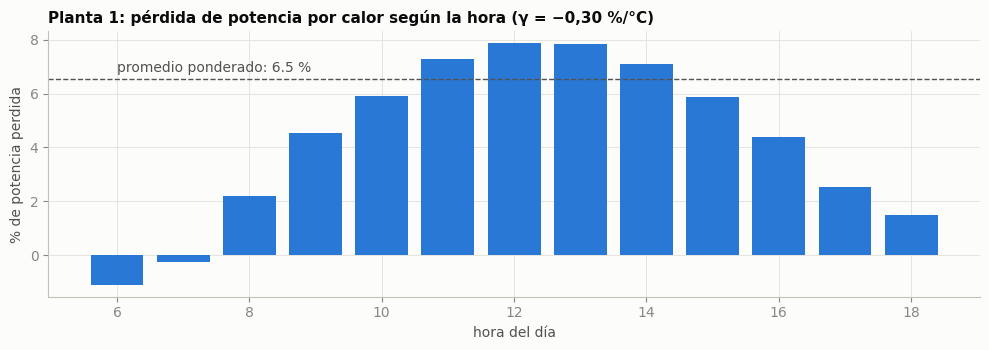

In [56]:
sol_p1 = modelo['Planta 1']                     # todas las horas de sol de la Planta 1 (34 días)
t_media = sol_p1[OBJETIVO].mean()
perdida_simple = -GAMMA * (t_media - T_STC)
perdida_inst = -GAMMA * (sol_p1[OBJETIVO] - T_STC)
perdida_pond = (perdida_inst * sol_p1['IRRADIATION']).sum() / sol_p1['IRRADIATION'].sum()
print(f'T. media del módulo con sol (Planta 1): {t_media:.2f} °C')
print(f'Pérdida por calor con la temperatura media: {perdida_simple:.2f} % de la potencia')
print(f'Pérdida ponderada por irradiación (energía): {perdida_pond:.2f} %')
print(f'Pérdida al mediodía (11 a 13 h): {perdida_inst[(sol_p1["HORA"] >= 11) & (sol_p1["HORA"] <= 13)].mean():.2f} % | '
      f'máxima: {perdida_inst.max():.2f} %')

por_hora = perdida_inst.groupby(sol_p1['HORA'].round(0)).mean()
fig, eje = plt.subplots(figsize=(10, 3.6))
eje.bar(por_hora.index, por_hora.values, width=0.8, color=COLOR['Planta 1'])
eje.axhline(perdida_pond, color=TINTA2, linestyle='--', linewidth=1)
eje.annotate(f'promedio ponderado: {perdida_pond:.1f} %', (por_hora.index.min(), perdida_pond), xytext=(0, 5),
             textcoords='offset points', color=TINTA2)
eje.set_xlabel('hora del día'); eje.set_ylabel('% de potencia perdida')
eje.set_title('Planta 1: pérdida de potencia por calor según la hora (γ = −0,30 %/°C)', loc='left')
fig.tight_layout(); guardar(fig, 't3_perdidas_por_hora'); plt.show()

### Umbral de alerta
El umbral se calcula con los **residuos de entrenamiento** (real − predicho): un residuo mayor que el percentil 99 indica un módulo **más caliente de lo que debería estar según el clima**.

> **Decisión: la alerta usa el modelo SIN rezagos.** El modelo con rezagos "sigue" a la temperatura del propio módulo. Si un módulo se recalienta poco a poco por una falla, ese modelo lo predeciría caliente también y **no daría la alerta**. El modelo sin rezagos estima la temperatura **esperada según el clima**, que es justo la referencia que la empresa no tiene (problema de la consigna).

In [57]:
m_alerta = modelos['4. Lineal sin rezagos'][0]
res_train = train[OBJETIVO] - m_alerta.predict(train[F_SIN])
umbral_p = np.percentile(res_train, PERCENTIL_ALERTA)
umbral_3s = res_train.mean() + 3 * res_train.std()
print(f'Residuos de entrenamiento: media {res_train.mean():.2f} °C | desviación {res_train.std():.2f} °C | asimetría {res_train.skew():.2f}')
print(f'Umbral percentil {PERCENTIL_ALERTA}: {umbral_p:.2f} °C sobre lo predicho | umbral 3σ: {umbral_3s:.2f} °C')

filas = []
for etq, d in [('prueba Planta 1', test), ('Planta 2 (modelo P1)', p2)]:
    res = d[OBJETIVO] - m_alerta.predict(d[F_SIN])
    for nombre_u, u in [(f'percentil {PERCENTIL_ALERTA}', umbral_p), ('3σ', umbral_3s)]:
        a = res > u
        filas.append({'datos': etq, 'umbral': nombre_u, '°C sobre lo predicho': round(u, 2), 'alertas (instantes)': int(a.sum()),
                      '% de los instantes': round(100 * a.mean(), 2), 'días con alerta': d.index[a].normalize().nunique()})
display(pd.DataFrame(filas))

res_test = test[OBJETIVO] - m_alerta.predict(test[F_SIN])
alertas = test.index[res_test > umbral_p]
print(f'Alertas en la prueba de la Planta 1 (percentil {PERCENTIL_ALERTA}): {len(alertas)}')
print(f'Mayor exceso sobre lo predicho en la prueba: {res_test.max():.2f} °C ({res_test.idxmax()})')

print('\nSensibilidad: alertas en la prueba de la Planta 1 según el percentil elegido')
display(pd.DataFrame([{'percentil': q, '°C sobre lo predicho': round(np.percentile(res_train, q), 2),
                       'alertas': int((res_test > np.percentile(res_train, q)).sum()),
                       'días con alerta': res_test.index[res_test > np.percentile(res_train, q)].normalize().nunique()}
                      for q in (90, 95, 97.5, 99)]))

# Umbral calibrado con la propia Planta 2 (mismo procedimiento, entrenando con su semana de entrenamiento)
m_p2 = tubo_lineal().fit(p2_train[F_SIN], p2_train[OBJETIVO])
p2_test = p2[p2.index >= CORTE]
res_p2_train = p2_train[OBJETIVO] - m_p2.predict(p2_train[F_SIN])
res_p2_test = p2_test[OBJETIVO] - m_p2.predict(p2_test[F_SIN])
u2 = np.percentile(res_p2_train, PERCENTIL_ALERTA)
print(f'\nPlanta 2 con SU PROPIO modelo: umbral +{u2:.2f} °C -> {int((res_p2_test > u2).sum())} alertas en su semana de prueba '
      f'| sesgo en su prueba {res_p2_test.mean():.2f} °C (con el modelo de la Planta 1 era {np.mean(p2_test[OBJETIVO] - m_alerta.predict(p2_test[F_SIN])):.2f} °C)')

Residuos de entrenamiento: media 0.00 °C | desviación 2.59 °C | asimetría 0.58
Umbral percentil 99: 7.78 °C sobre lo predicho | umbral 3σ: 7.77 °C


,datos,umbral,°C sobre lo predicho,alertas (instantes),% de los instantes,días con alerta
0,prueba Planta 1,percentil 99,7.78,0,0.0,0
1,prueba Planta 1,3σ,7.77,0,0.0,0
2,Planta 2 (modelo P1),percentil 99,7.78,0,0.0,0
3,Planta 2 (modelo P1),3σ,7.77,0,0.0,0


Alertas en la prueba de la Planta 1 (percentil 99): 0
Mayor exceso sobre lo predicho en la prueba: 6.55 °C (2020-06-14 14:30:00)

Sensibilidad: alertas en la prueba de la Planta 1 según el percentil elegido


,percentil,°C sobre lo predicho,alertas,días con alerta
0,90.0,3.33,17,6
1,95.0,4.29,5,4
2,97.5,5.92,1,1
3,99.0,7.78,0,0



Planta 2 con SU PROPIO modelo: umbral +6.61 °C -> 0 alertas en su semana de prueba | sesgo en su prueba 0.20 °C (con el modelo de la Planta 1 era -2.82 °C)


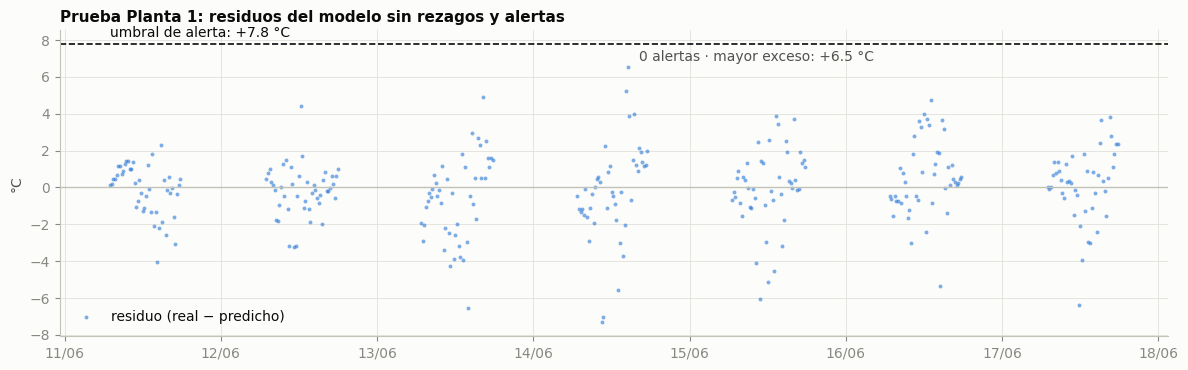

In [58]:
fig, eje = plt.subplots(figsize=(12, 3.8))
eje.scatter(res_test.index, res_test, s=8, color=COLOR['Planta 1'], alpha=0.6, linewidths=0, label='residuo (real − predicho)')
eje.axhline(umbral_p, color=TINTA, linestyle='--', linewidth=1.2)
eje.annotate(f'umbral de alerta: +{umbral_p:.1f} °C', (res_test.index[0], umbral_p), xytext=(0, 5), textcoords='offset points', color=TINTA)
if len(alertas):
    eje.scatter(alertas, res_test[alertas], s=40, facecolors='none', edgecolors=TINTA, linewidths=1.2, label='alerta')
eje.annotate(f'{len(alertas)} alertas · mayor exceso: +{res_test.max():.1f} °C', (res_test.idxmax(), res_test.max()),
             xytext=(8, 4), textcoords='offset points', color=TINTA2)
eje.axhline(0, color=EJE, linewidth=1)
eje.set_ylabel('°C'); eje.set_title('Prueba Planta 1: residuos del modelo sin rezagos y alertas', loc='left')
ejes_fecha(eje, cada=1); eje.legend(loc='lower left')
fig.tight_layout(); guardar(fig, 't3_alertas'); plt.show()

**Interpretación: pérdidas por calor (P3).**
- Con sol, la temperatura media del módulo de la Planta 1 es **41,5 °C**, es decir, 16,5 °C por encima de las condiciones estándar. Con γ = −0,30 %/°C, eso es una **pérdida de 4,9 % de la potencia**, que es el cálculo que pide la consigna.
- **Ponderada por irradiación, la pérdida es de 6,5 %.** Es más representativa de la energía, porque las horas más calientes son las que más producen. De cada 100 kWh que la planta generaría a 25 °C, se pierden unos 6,5 por el calor.
- Al mediodía la pérdida llega a **7,8 %**, y su máximo es **12,2 %**. A las 6 y 7 de la mañana es levemente negativa: el módulo está por debajo de 25 °C y rinde un poco más.
- Es coherente con la estimación para Cali de la introducción (6 a 9 % al mediodía).

**Interpretación: umbral de alerta.**
- Los residuos de entrenamiento del modelo sin rezagos tienen una desviación de 2,59 °C y algo de asimetría (0,58). El **percentil 99 da un umbral de +7,8 °C** sobre lo predicho, prácticamente igual al de 3σ (+7,8 °C). Que los dos coincidan indica que los residuos son aproximadamente normales, como muestra la guía.
- **En la semana de prueba de la Planta 1 hubo 0 alertas.** El mayor exceso fue de +6,5 °C (14 de junio, 14:30). Es coherente: la semana fue nublada y fresca y no hay ninguna falla registrada. **Un módulo 7,8 °C por encima de lo esperado sería algo anormal de verdad.**
- **Sensibilidad.** Con el percentil 95 (+4,3 °C) habría 5 alertas en 4 días, y con el percentil 90 (+3,3 °C), 17 alertas en 6 días. Un umbral más bajo detecta antes, pero da **más falsas alarmas** en una semana normal. El percentil 99 es conservador: en el entrenamiento, solo 1 de cada 100 instantes normales lo supera.
- **En la Planta 2 también hay 0 alertas, pero por la razón equivocada.** El modelo de la Planta 1 sobreestima esa planta en 3 a 4 °C, así que un recalentamiento de hasta unos 11 °C **pasaría desapercibido**. Es la advertencia de la guía: con los residuos corridos, el umbral de una planta no sirve en la otra. Con un modelo calibrado para la Planta 2 (umbral de +6,6 °C, sesgo de 0,2 °C) el sistema sí sería confiable.

> **Decisión: umbral = percentil 99 de los residuos de entrenamiento (+7,8 °C).** Es el ejemplo que da la consigna. Prioriza no saturar al equipo de mantenimiento con falsas alarmas.

## 3.7 Resumen: respuestas a las preguntas analíticas

| Pregunta | Respuesta con los datos |
|---|---|
| **P1.** ¿Cuántos °C se calienta el módulo por cada kW/m², y está en el rango de Ross? | En la Planta 1 el módulo se calienta **27,4 °C por cada kW/m²** de irradiación (IC 95 %: 26,7 a 28,1), con la temperatura del aire y la hora fijas. En la práctica son unos 13 °C por encima de lo que explica el aire con la irradiación media con sol (0,49 kW/m²) y unos 27 °C a pleno sol (1 kW/m²). **Sí está dentro del rango de 21 a 31 °C por kW/m²** (Ross para estructura abierta y NOCT de la ficha), y es coherente con la pendiente exploratoria del EDA (29,4). El modelo **se parece a Ross, pero no es idéntico**: el coeficiente del aire es 1,45 y no 1, probablemente porque la temperatura del aire recoge efectos que no se midieron, como el viento. P1 se responde con el modelo **sin rezagos**: en el modelo con rezagos, la temperatura del módulo de 15 minutos antes ya contiene el efecto del sol y absorbe parte de él, así que el coeficiente de la irradiación deja de ser la k de Ross. La relación es casi lineal (r = 0,95), y por eso la regresión lineal le gana al árbol de decisión y empata con el Gradient Boosting |
| **P2.** ¿Cuánto aumenta el error (RMSE y MAE) en la Planta 2 sin reentrenar, y en qué difieren los coeficientes? | **Modelo sin rezagos:** el RMSE sube de 2,05 a **4,64 °C (+127 %)** y el MAE de 1,49 a **3,97 °C (+166 %)**. **Mejor modelo (con rezagos):** el RMSE sube de 1,47 a **3,08 °C (+110 %)** y el MAE de 1,03 a **2,48 °C (+140 %)**; en la Planta 2 ya no le gana a la persistencia (habilidad de −0,11). El error es sobre todo **sistemático**: el modelo de la Planta 1 sobreestima la Planta 2 en 3,85 °C en promedio con todos sus datos (2,8 °C en su semana de prueba), y el sesgo crece con la irradiación (de −1,8 °C con poco sol a −5,7 °C con mucho). **Coeficientes (Planta 1 contra Planta 2):** irradiación 27,4 contra **24,1 °C por kW/m²**, con intervalos que no se cruzan: con el mismo sol, el módulo de la Planta 2 se calienta un 12 % menos, aunque su aire es 2,5 °C más caliente; aire 1,45 contra 1,31 °C/°C; hora −0,21 contra −0,14 °C/h. Causas posibles: mejor ventilación, otro montaje o inclinación, otra tecnología de módulo o el sensor en otro lugar. Los modelos que se apoyan en la historia del módulo se transfieren mejor (el Random Forest es el mejor en la Planta 2, con 2,41 °C). **Conclusión:** la forma del modelo se transfiere, pero **los coeficientes hay que recalibrarlos por planta**; con su propio modelo, el sesgo de la Planta 2 baja a 0,2 °C |
| **P3.** ¿Cuánta potencia se pierde por calor, y cuántas alertas habría generado un umbral basado en los residuos? | Con γ = −0,30 %/°C (valor supuesto de la ficha Jinko Tiger Neo), la temperatura media del módulo con sol (41,5 °C, 16,5 °C sobre las condiciones estándar) implica una pérdida de **4,9 %** de la potencia. **Ponderada por irradiación**, que representa mejor la energía, es de **6,5 %**: de cada 100 kWh que se generarían a 25 °C se pierden unos 6,5. Al mediodía llega a **7,8 %** y su máximo es 12,2 %. La alerta usa el modelo **sin rezagos**, porque estima la temperatura **esperada según el clima** (el modelo con rezagos "seguiría" a un módulo que se recalienta poco a poco y no alertaría). Con el umbral del percentil 99 de los residuos de entrenamiento (**+7,8 °C** sobre lo esperado, igual que el de 3σ) hubo **0 alertas** en la semana de prueba; el mayor exceso fue de +6,5 °C (14 de junio, 14:30). **Sensibilidad:** con el percentil 95 (+4,3 °C) habría 5 alertas en 4 días, y con el percentil 90 (+3,3 °C), 17 alertas en 6 días. Como no hay fallas registradas, las 0 alertas muestran que el umbral **no genera falsas alarmas en una semana normal**, pero **no prueban que detecte hot spots** |

**El mejor modelo:** la regresión lineal con rezagos, con un MAPE de 2,7 %, un RMSE de 1,47 °C, un MAE de 1,03 °C y **49 % menos error que la persistencia** en la prueba de la Planta 1. Ninguno de los otros ocho modelos la supera en esa prueba, y la validación cruzada la habría elegido igual sin mirar la prueba (RMSE de validación de 1,78 °C, el menor). No sobreajusta (1,67 °C en entrenamiento contra 1,78 °C en validación). El Gradient Boosting prácticamente empata (1,50 °C), pero se prefiere la lineal por ser más simple e interpretable. **Su límite:** en la Planta 2 sin reentrenar su habilidad es de −0,11 (no le gana a la persistencia), lo que refuerza que hay que recalibrar por planta.

**Cómo usaría la empresa el modelo (despliegue):**
1. Cada 15 minutos, con los sensores de clima, el modelo **sin rezagos** calcula la temperatura **esperada** del módulo.
2. Si la temperatura medida supera la esperada en más de 7,8 °C, se lanza una alerta. Se puede pedir que el exceso dure 2 lecturas seguidas (30 minutos) para no alertar por una nube pasajera.
3. Ante una alerta, una cuadrilla revisa con **termografía infrarroja** (IEA PVPS [8]).
4. El modelo **con rezagos** se usa para estimar la temperatura y las pérdidas por calor en tiempo real.
5. **Antes de usarlo en una planta nueva, se recalibra con datos de esa planta**, tanto los coeficientes como el umbral de alerta (en la Planta 2, con el modelo de la Planta 1, un recalentamiento de hasta unos 11 °C pasaría desapercibido; con su propio modelo el umbral es de +6,6 °C).

**Limitaciones:**
- No hay datos de **viento**, que según Faiman y Sandia [7], [10] influye en la temperatura del módulo. Puede explicar por qué el coeficiente del aire es 1,45 y no 1.
- Solo hay **34 días** de una estación del año y **un sensor por planta**.
- El coeficiente de temperatura **γ = −0,30 %/°C es supuesto** (ficha Jinko): no se conoce la tecnología real de los módulos de las plantas, así que las pérdidas son una estimación.
- Los residuos están **autocorrelacionados** (Durbin-Watson de 1,13 a 1,55 en la Planta 1 y 0,81 en la Planta 2), así que los intervalos de confianza y los p-valores son optimistas.
- La **semana de prueba fue la más nublada y fresca** del periodo: parte de la diferencia entre entrenamiento y prueba se debe al clima y no al modelo.
- **No hay fallas reales registradas** para comprobar que las alertas detectan hot spots ni para elegir el percentil del umbral con datos.

**Mejoras posibles:**
- Agregar la velocidad del viento (modelo de Faiman).
- Calibrar por planta y por estación, con varios meses de datos.
- Aprovechar la memoria que queda en los residuos (autocorrelación de 0,41 a 15 minutos), por ejemplo con más rezagos.
- Usar el coeficiente γ de la ficha de los módulos reales de cada planta.
- Validar las alertas contra inspecciones termográficas reales y ajustar el percentil del umbral según las fallas detectadas y las falsas alarmas.

# 4. Salidas para el informe
Aqui se generan las **figuras a tamaño de una columna IEEE** y se guardan los **números del informe** en `informe/tablas/resultados.json`, para que el informe use exactamente las cifras de este notebook, sin copiarlas a mano.

In [59]:
import json
TABLAS = Path('..') / 'informe' / 'tablas'
TABLAS.mkdir(parents=True, exist_ok=True)
COL = 3.45   # ancho de una columna IEEE en pulgadas
estilo_columna = {'font.size': 7.5, 'axes.titlesize': 8, 'axes.labelsize': 7.5, 'xtick.labelsize': 7,
                  'ytick.labelsize': 7, 'legend.fontsize': 7, 'lines.linewidth': 1.2}

with mpl.rc_context(estilo_columna):
    # Fig. 1: calentamiento sobre el aire vs irradiación (EDA, horas de sol)
    fig, eje = plt.subplots(figsize=(COL, 2.3))
    for n, d in limpios.items():
        s = d[d['IRRADIATION'] > UMBRAL_SOL].dropna(subset=VARS)
        dif = s['MODULE_TEMPERATURE'] - s['AMBIENT_TEMPERATURE']
        eje.scatter(s['IRRADIATION'], dif, s=2, alpha=0.2, color=COLOR[n], linewidths=0)
        m, b = np.polyfit(s['IRRADIATION'], dif, 1)
        xs = np.linspace(UMBRAL_SOL, s['IRRADIATION'].max(), 20)
        eje.plot(xs, m * xs + b, color=COLOR[n], linewidth=1.6, label=f'{n}: {m:.1f} °C por kW/m²')
    eje.set_xlabel('Irradiación (kW/m²)'); eje.set_ylabel('T. módulo − T. aire (°C)'); eje.legend(loc='upper left')
    fig.tight_layout(); fig.savefig(FIGURAS / 'inf_fig1_calentamiento.png', dpi=300); plt.close(fig)

    # Fig. 2: real vs predicho del mejor modelo (prueba P1 y Planta 2)
    fig, eje = plt.subplots(figsize=(COL, 2.6))
    for n, d, clave in [('Planta 2', p2, 'p2'), ('Planta 1', test, 'test')]:
        r = metricas(d[OBJETIVO], predicciones[mejor][clave])
        eje.scatter(d[OBJETIVO], predicciones[mejor][clave], s=3, alpha=0.35, color=COLOR[n], linewidths=0,
                    label=f"{'Prueba Planta 1' if n == 'Planta 1' else 'Planta 2 sin reentrenar'} (RMSE {r['RMSE']:.2f} °C)")
    eje.plot([18, 70], [18, 70], color=TINTA2, linewidth=0.8)
    eje.set_xlabel('T. módulo real (°C)'); eje.set_ylabel('T. módulo predicha (°C)'); eje.legend(loc='upper left', markerscale=3)
    fig.tight_layout(); fig.savefig(FIGURAS / 'inf_fig2_real_vs_predicho.png', dpi=300); plt.close(fig)

    # Fig. 3: residuos del mejor modelo en la prueba de la Planta 1
    res_mejor = test[OBJETIVO] - predicciones[mejor]['test']
    fig, ejes = plt.subplots(1, 2, figsize=(COL, 1.9), gridspec_kw={'width_ratios': [1.4, 1]})
    ejes[0].scatter(predicciones[mejor]['test'], res_mejor, s=3, alpha=0.5, color=COLOR['Planta 1'], linewidths=0)
    ejes[0].axhline(0, color=TINTA2, linewidth=0.8); ejes[0].set_xlabel('Predicho (°C)'); ejes[0].set_ylabel('Residuo (°C)')
    ejes[1].hist(res_mejor, bins=25, color=COLOR['Planta 1'], alpha=0.85); ejes[1].axvline(0, color=TINTA2, linewidth=0.8)
    ejes[1].set_xlabel('Residuo (°C)'); ejes[1].set_ylabel('Frecuencia')
    fig.tight_layout(); fig.savefig(FIGURAS / 'inf_fig3_residuos.png', dpi=300); plt.close(fig)

    # Fig. 4: coeficiente de la irradiación en ambas plantas frente al rango de Ross
    fig, eje = plt.subplots(figsize=(COL, 1.5))
    eje.axvspan(20.8, 31.25, color=TENUE, alpha=0.18, linewidth=0)
    for i, n in enumerate(['Planta 1', 'Planta 2']):
        c = coefs[n].loc['IRRADIATION']
        eje.errorbar(c['coeficiente'], i, xerr=[[c['coeficiente'] - c['IC 95 % inf']], [c['IC 95 % sup'] - c['coeficiente']]],
                     fmt='o', color=COLOR[n], markersize=5, capsize=3, linewidth=1.5)
        eje.annotate(f"{c['coeficiente']:.1f}", (c['coeficiente'], i), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=7)
    eje.annotate('rango de Ross (20,8 a 31,3)', (21.1, 1.55), fontsize=6.5, color=TINTA2)
    eje.set_yticks([0, 1]); eje.set_yticklabels(['Planta 1', 'Planta 2']); eje.set_ylim(-0.6, 1.9); eje.set_xlim(16, 36)
    eje.set_xlabel('Coeficiente de la irradiación (°C por kW/m²), IC 95 %')
    fig.tight_layout(); fig.savefig(FIGURAS / 'inf_fig4_coeficientes.png', dpi=300); plt.close(fig)

    # Fig. 5: pérdida por hora (arriba) y residuos de la prueba con el umbral de alerta (abajo)
    fig, ejes = plt.subplots(2, 1, figsize=(COL, 3.2))
    ejes[0].bar(por_hora.index, por_hora.values, width=0.8, color=COLOR['Planta 1'])
    ejes[0].axhline(perdida_pond, color=TINTA2, linestyle='--', linewidth=0.8)
    ejes[0].set_xlabel('Hora del día'); ejes[0].set_ylabel('Pérdida (%)')
    ejes[0].set_title('(a) Pérdida de potencia por calor, Planta 1', loc='left')
    ejes[1].scatter(res_test.index, res_test, s=3, color=COLOR['Planta 1'], alpha=0.6, linewidths=0)
    ejes[1].axhline(umbral_p, color=TINTA, linestyle='--', linewidth=0.9)
    ejes[1].annotate(f'umbral +{umbral_p:.1f} °C', (res_test.index[0], umbral_p), xytext=(0, 3), textcoords='offset points', fontsize=6.5)
    ejes[1].axhline(0, color=EJE, linewidth=0.8); ejes[1].set_ylabel('Residuo (°C)')
    ejes[1].set_title('(b) Residuos en la semana de prueba', loc='left'); ejes_fecha(ejes[1], cada=2)
    fig.tight_layout(); fig.savefig(FIGURAS / 'inf_fig5_negocio.png', dpi=300); plt.close(fig)
print('Figuras del informe:', sorted(p.name for p in FIGURAS.glob('inf_*.png')))

Figuras del informe: ['inf_fig1_calentamiento.png', 'inf_fig2_real_vs_predicho.png', 'inf_fig3_residuos.png', 'inf_fig4_coeficientes.png', 'inf_fig5_negocio.png']


In [60]:
# Números del informe (todo sale de este notebook)
r = lambda x, k=2: None if pd.isna(x) else round(float(x), k)
fila = lambda n: {c[0] + ' ' + c[1]: r(v, 3) for c, v in tabla.loc[n].items()}
salida = {
    'datos': {n: {'recibidos': int(len(datos[n])), 'faltantes': int(completos[n][OBJETIVO].isna().sum()),
                  'huecos': int(len(huecos[n])), 'rellenados': int(limpios[n]['imputado'].sum()),
                  'con_sol': int(len(modelo[n])), 'modelado': int(len(datos_m[n]))} for n in datos},
    'division': {'train': int(len(train)), 'test': int(len(test)), 'dias_train': int(dias_train), 'dias_test': int(dias_test),
                 'pct_train': r(100 * len(train) / len(p1), 1)},
    'arbol': {k[3:]: gs.best_params_ for k, gs in busquedas.items()},
    'ensambles': {k[3:]: gs.best_params_ for k, gs in busquedas_ens.items()},
    'mejor': mejor,
    'modelos': {n: fila(n) for n in tabla.index},
    'sin_dia_anterior': sin_dia_anterior,
    'grupos': [{k: (r(v, 3) if isinstance(v, float) else v) for k, v in f.items()} for f in ablacion.to_dict('records')],
    'fuga': {k: {m: r(v, 4) for m, v in d.items()} for k, d in fuga.items()},
    'residuos': {k[3:]: {m: r(v, 3) for m, v in d.items()} for k, d in diag_residuos.items()},
    'importancia': {k[3:]: {i: r(v, 3) for i, v in s.items()} for k, s in importancias.items()},
    'pesos_estandarizados': {k: {i: r(v, 2) for i, v in s.items()} for k, s in pesos.items()},
    'coeficientes': {n: {idx: {k: r(v, 4) for k, v in fila_c.items()} for idx, fila_c in coefs[n].iterrows()} for n in coefs},
    'transferencia': {n: {'aumento_rmse_pct': r(transfer.loc[n, 'aumento RMSE (%)'], 1), 'sesgo': r(transfer.loc[n, 'sesgo en P2 (°C)'])}
                      for n in transfer.index},
    'negocio': {'t_media': r(t_media), 'perdida_simple': r(perdida_simple), 'perdida_ponderada': r(perdida_pond),
                'perdida_mediodia': r(perdida_inst[(sol_p1['HORA'] >= 11) & (sol_p1['HORA'] <= 13)].mean()),
                'perdida_max': r(perdida_inst.max()), 'umbral_p99': r(umbral_p), 'umbral_3s': r(umbral_3s),
                'alertas_test': int((res_test > umbral_p).sum()), 'max_exceso': r(res_test.max()),
                'sd_residuos': r(res_train.std()), 'umbral_p2_propio': r(u2), 'sesgo_p2_propio': r(res_p2_test.mean())},
    'pendientes_eda': {p['planta']: p['pendiente'] for p in pendientes if p['relación'].startswith('Módulo − aire')},
    'versiones': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                  'matplotlib': mpl.__version__, 'scikit-learn': sklearn.__version__, 'statsmodels': sm.__version__},
}
with open(TABLAS / 'resultados.json', 'w', encoding='utf-8') as f:
    json.dump(salida, f, ensure_ascii=False, indent=1, default=str)
print('Guardado:', TABLAS / 'resultados.json')

Guardado: ..\informe\tablas\resultados.json
